# Predicción de la dificultad de pago mediante modelos explicables

## Proyecto práctico de la Unidad 2 · Fase II

## <a id="indice"></a> Índice

- [0. Portada y objetivos](#sec-0)
  - [Datos del proyecto](#sec-0-datos-del-proyecto)
  - [Objetivo de predicción](#sec-0-objetivo-de-prediccion)
  - [Objetivos específicos](#sec-0-objetivos-especificos)
  - [Alcance](#sec-0-alcance)
  - [Guía del notebook](#sec-0-guia-del-notebook)
- [1. Entorno y reproducibilidad](#sec-1)
  - [1.1. Entorno de ejecución y dependencias](#sec-1-1)
  - [1.2. Importaciones, versiones y semillas](#sec-1-2)
  - [1.3. Localización y carga de archivos](#sec-1-3)
- [2. Datos, exploración y preprocesamiento](#sec-2)
  - [2.1. Contexto, objetivo y archivos](#sec-2-1)
  - [2.2. Diccionario de variables](#sec-2-2)
  - [2.3. Organización de los datos](#sec-2-3)
  - [2.4. Distribución de la variable objetivo](#sec-2-4)
  - [2.5. Calidad, tipos y valores ausentes](#sec-2-5)
  - [2.6. Distribuciones, asociaciones y fugas](#sec-2-6)
  - [2.7. Decisiones de preprocesamiento](#sec-2-7)
  - [2.8. Integración con los modelos y validación cruzada](#sec-2-8)
- [3. Diseño de la evaluación](#sec-3)
  - [3.1. Cinco particiones comunes](#sec-3-1)
  - [3.2. Métricas y criterio de selección](#sec-3-2)
  - [3.3. Referencia de la clase mayoritaria](#sec-3-3)
  - [3.4. Ajuste de configuraciones, variables y umbrales](#sec-3-4)
  - [3.5. Comparación y entrenamiento final](#sec-3-5)
- [4. Modelo lógico](#sec-4)
  - [4.1. Árbol de decisión y presupuesto de complejidad](#sec-4-1)
  - [4.2. Diagnóstico de un árbol sin restricciones](#sec-4-2)
  - [4.3. Evaluación anidada y resultados externos](#sec-4-3)
  - [4.4. Árbol de referencia, reglas y probabilidades de las hojas](#sec-4-4)
  - [4.5. Variables utilizadas e importancias por impureza](#sec-4-5)
  - [4.6. Estabilidad entre divisiones](#sec-4-6)
  - [4.7. Síntesis de la interpretación y limitaciones](#sec-4-7)
- [5. Regresión logística](#sec-5)
  - [5.1. Modelo y regularización](#sec-5-1)
  - [5.2. Configuraciones y criterios de selección](#sec-5-2)
  - [5.3. Evaluación anidada de cinco particiones](#sec-5-3)
  - [5.4. Resultados externos y efecto del umbral](#sec-5-4)
  - [5.5. Coeficientes, referencias y odds ratios](#sec-5-5)
  - [5.6. Visualización global de los coeficientes](#sec-5-6)
  - [5.7. Estabilidad entre las cinco particiones](#sec-5-7)
  - [5.8. Visualización con InterpretML](#sec-5-8)
  - [5.9. Síntesis de la interpretación y limitaciones](#sec-5-9)
- [6. Explainable Boosting Machine](#sec-6)
  - [6.1. Modelo aditivo y explicabilidad](#sec-6-1)
  - [6.2. Configuraciones y control del coste](#sec-6-2)
  - [6.3. Evaluación anidada de cinco particiones](#sec-6-3)
  - [6.4. Resultados externos y efecto del umbral](#sec-6-4)
  - [6.5. Primera exploración de las funciones aprendidas](#sec-6-5)
  - [6.6. Gráficas de todas las funciones univariantes](#sec-6-6)
  - [6.7. Variabilidad de las contribuciones globales](#sec-6-7)
  - [6.8. Comparación de las funciones en valores comunes](#sec-6-8)
  - [6.9. Síntesis de la interpretación y limitaciones](#sec-6-9)
- [7. Comparación del rendimiento](#sec-7)
  - [7.1. Tabla conjunta de configuraciones y métricas](#sec-7-1)
  - [7.2. Comparación por partición y variabilidad](#sec-7-2)
  - [7.3. Análisis de falsos positivos y falsos negativos](#sec-7-3)
  - [7.4. Coincidencias y discrepancias entre errores](#sec-7-4)
  - [7.5. Rendimiento, complejidad e interpretabilidad](#sec-7-5)
  - [7.6. Discusión y alcance de la comparación](#sec-7-6)
- [8. Interpretación local comparada](#sec-8)
  - [8.1. Selección de casos comunes y procedencia](#sec-8-1)
  - [8.2. Probabilidades, umbrales y decisiones](#sec-8-2)
  - [8.3. Explicación local del árbol: recorrido y hoja](#sec-8-3)
  - [8.4. Reconstrucción de logística y EBM por contribuciones](#sec-8-4)
  - [8.5. Gráficas de contribuciones para los casos comunes](#sec-8-5)
  - [8.6. Vistas locales de InterpretML](#sec-8-6)
  - [8.7. Alcance y revisión de las explicaciones locales](#sec-8-7)
- [9. Discusión de las explicaciones](#sec-9)
  - [9.1. Qué aporta cada forma de explicación](#sec-9-1)
  - [9.2. Coincidencias y variables relevantes](#sec-9-2)
  - [9.3. Discrepancias entre explicaciones y decisiones](#sec-9-3)
  - [9.4. Estabilidad y dependencia entre variables](#sec-9-4)
  - [9.5. Asociaciones aprendidas y límites causales](#sec-9-5)
  - [9.6. Balance de la discusión y posibles mejoras](#sec-9-6)
- [10. Selección y entrenamiento final](#sec-10)
  - [10.1. Justificación de la familia seleccionada](#sec-10-1)
  - [10.2. Selección de la configuración con todos los datos etiquetados](#sec-10-2)
  - [10.3. Selección del umbral con probabilidades OOF](#sec-10-3)
  - [10.4. Ajuste final y comprobación de la estructura](#sec-10-4)
  - [10.5. Revisión del modelo final y alcance de los resultados](#sec-10-5)
- [11. Predicción y exportación del test](#sec-11)
  - [11.1. Comprobación de las entradas y del modelo final](#sec-11-1)
  - [11.2. Predicciones y distribución de las etiquetas](#sec-11-2)
  - [11.3. Exportación y verificación de test.csv](#sec-11-3)
  - [11.4. Archivo de entrega y descarga en Colab](#sec-11-4)
- [12. Conclusiones](#sec-12)
  - [12.1. Hallazgos principales](#sec-12-1)
  - [12.2. Modelo final y entrega de predicciones](#sec-12-2)
  - [12.3. Limitaciones y posibles mejoras](#sec-12-3)
- [13. Referencias y uso de IA generativa](#sec-13)
  - [13.1. Referencias](#sec-13-1)
  - [13.2. Uso de IA generativa](#sec-13-2)


## <a id="sec-0"></a> 0. Portada y objetivos

### <a id="sec-0-datos-del-proyecto"></a> Datos del proyecto

**Asignatura:** Inteligencia Artificial Explicable  
**Grupo:** 3  
**Repositorio:** [germansanchezz/iax-group-3](https://github.com/germansanchezz/iax-group-3)  
**Fecha de actualización:** 13 de octubre de 2026

**Integrantes:**

| Nombre | Correo electrónico |
| --- | --- |
| Damián Benasco Sánchez | d.benasco@alumnos.upm.es |
| Germán Sánchez Carmona | german.sanchez.carmona@alumnos.upm.es |
| Jorge Enrique Vega Ortiz | jorge.vega@alumnos.upm.es |

### <a id="sec-0-objetivo-de-prediccion"></a> Objetivo de predicción

Predecir la variable binaria `payment_difficulty_next_month`: **1 indica dificultad de pago en el mes siguiente y 0 indica ausencia de dificultad**, según el diccionario de datos. El propósito del proyecto es evaluar el rendimiento predictivo y comprender qué aprende cada modelo, explicar predicciones individuales y analizar coincidencias y discrepancias entre sus explicaciones.

### <a id="sec-0-objetivos-especificos"></a> Objetivos específicos

- Entrenar e interpretar las tres familias de modelos exigidas: un modelo lógico (árbol de decisión, lista de reglas o conjunto de reglas), una regresión logística y un modelo aditivo generalizado Explainable Boosting Machine (EBM) con `interactions=0`.
- Utilizar validación cruzada de cinco particiones para comparar modelos y seleccionar hiperparámetros, variables y umbrales de clasificación, con métricas elegidas y justificadas.
- Interpretar globalmente los modelos y comparar sus explicaciones locales sobre los mismos casos, incluyendo al menos un caso de cada clase.
- Examinar el equilibrio entre rendimiento, complejidad e interpretabilidad y distinguir las asociaciones aprendidas de las afirmaciones causales.
- Seleccionar una configuración mediante validación cruzada, entrenar el modelo final con todos los datos etiquetados y completar `test.csv` con una columna `predicted_class` de valores 0 o 1, conservando las filas y columnas originales.

### <a id="sec-0-alcance"></a> Alcance

Este notebook corresponde al proyecto completo de la Fase II descrito en [el enunciado](../pdfs/project-statement-xai-2026.pdf). El análisis utilizará los datos etiquetados de `train.csv`, el conjunto sin etiquetas `test.csv` y las definiciones de `data-dictionary.xlsx`. La variable objetivo y algunas variables docentes son semisintéticas; las conclusiones se limitarán al ejercicio de predicción e interpretación y no se considerarán evidencia sobre una población real de crédito ni una política lista para su despliegue.

El notebook recogerá el análisis y la implementación reproducible, con ejecución de principio a fin en Google Colab. Los resultados y conclusiones se incorporarán cuando se completen las secciones correspondientes.

### <a id="sec-0-guia-del-notebook"></a> Guía del notebook

Las secciones 1–3 preparan el entorno, describen, exploran y preparan los datos, y definen la evaluación. Las secciones 4–6 desarrollan e interpretan las tres familias de modelos. Las secciones 7–9 comparan el rendimiento, las explicaciones locales y sus limitaciones. Las secciones 10–11 seleccionan y entrenan el modelo final y exportan las predicciones del test. Las secciones 12–13 recogen las conclusiones, las referencias y el uso de IA generativa.


### IMPORTANTE

Se necesitan `train.csv`, `test.csv` y `data-dictionary.xlsx`. En el repositorio se buscan en `data/`, tanto si el kernel se inicia en la raíz como en `notebooks/`. También se admite que los tres archivos estén en el directorio de ejecución.

En Google Colab, si no se encuentran los archivos, se abrirá el selector para subir los tres. Si están en Google Drive, montar primero la unidad con `from google.colab import drive; drive.mount('/content/drive')` y establecer `DATA_DIR_OVERRIDE` con la ruta de su carpeta. La ruta explícita tiene prioridad; si está incompleta, se mostrará qué archivos faltan.


[Volver al índice](#indice)

## <a id="sec-1"></a> 1. Entorno y reproducibilidad

### <a id="sec-1-1"></a> 1.1. Entorno de ejecución y dependencias


In [1]:
import importlib
import subprocess
import sys
from importlib.metadata import PackageNotFoundError, version

REFERENCE_VERSIONS = {
    "numpy": "2.2.6",
    "pandas": "2.3.3",
    "scipy": "1.15.3",
    "matplotlib": "3.10.9",
    "scikit-learn": "1.7.2",
    "interpret": "0.7.8",
    "openpyxl": "3.1.5",
}

missing_dependencies = []
for package, reference_version in REFERENCE_VERSIONS.items():
    try:
        version(package)
    except PackageNotFoundError:
        missing_dependencies.append(f"{package}=={reference_version}")

if missing_dependencies:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "--quiet", *missing_dependencies]
    )
    importlib.invalidate_caches()
    print("Dependencias ausentes instaladas.")
else:
    print("Todas las dependencias están instaladas.")

Todas las dependencias están instaladas.


### <a id="sec-1-2"></a> 1.2. Importaciones, versiones y semillas

Se importan las clases necesarias para los modelos lógicos, la regresión logística y Explainable Boosting Machine. La regresión logística se ajusta con scikit-learn; las herramientas de InterpretML permiten visualizar sus explicaciones globales y locales. Se configura `InlineProvider` para visualizar las explicaciones dentro del notebook, tanto en Jupyter como en Google Colab.

`SEED = 42` se utilizará también como `random_state` en los modelos y particiones que lo admitan. `N_JOBS = 1` fija un único proceso para las operaciones que admitan este parámetro. Las semillas por sí solas no garantizan resultados idénticos entre versiones, plataformas o implementaciones; por ello se registra también el entorno.

In [2]:
import hashlib
import platform
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from IPython.display import display
from sklearn.tree import DecisionTreeClassifier
from interpret import set_visualize_provider, show
from interpret.glassbox import (
    ClassificationTree,
    ExplainableBoostingClassifier,
    LogisticRegression,
)
from interpret.provider import InlineProvider

SEED = 42
N_JOBS = 1
random.seed(SEED)
np.random.seed(SEED)
set_visualize_provider(InlineProvider())

print(f"Python: {platform.python_version()}")
print(f"Plataforma: {platform.platform()}")
print(f"Semilla: {SEED} | Procesos: {N_JOBS}")

environment_versions = pd.DataFrame(
    [
        {
            "Paquete": package,
            "Versión instalada": version(package),
            "Versión de referencia": reference_version,
        }
        for package, reference_version in REFERENCE_VERSIONS.items()
    ]
)
display(environment_versions)

# Registro de versiones exactas para repetir esta ejecución.
print("Dependencias de esta ejecución:")
print("\n".join(f"{package}=={version(package)}" for package in REFERENCE_VERSIONS))

Python: 3.13.13
Plataforma: Linux-7.2.9-2-cachyos-x86_64-with-glibc2.44
Semilla: 42 | Procesos: 1


,Paquete,Versión instalada,Versión de referencia
0,numpy,2.5.3,2.2.6
1,pandas,3.0.6,2.3.3
2,scipy,1.18.1,1.15.3
3,matplotlib,3.11.2,3.10.9
4,scikit-learn,1.9.1,1.7.2
5,interpret,0.7.8,0.7.8
6,openpyxl,3.1.5,3.1.5


Dependencias de esta ejecución:
numpy==2.5.3
pandas==3.0.6
scipy==1.18.1
matplotlib==3.11.2
scikit-learn==1.9.1
interpret==0.7.8
openpyxl==3.1.5


### <a id="sec-1-3"></a> 1.3. Localización y carga de archivos
Se cargan los CSV en `train_raw` y `test_raw`, y todas las hojas del Excel en `dictionary_sheets`. Se conserva `row_id` como texto para mantener los identificadores. En este apartado no se transforman las variables ni se ajustan modelos. La tabla de archivos registra su tamaño y huella SHA-256 para comprobar que distintas ejecuciones utilizan los mismos datos.

In [3]:
# Ejemplo en Drive: Path("/content/drive/MyDrive/proyecto_xai/data")
DATA_DIR_OVERRIDE = None
REQUIRED_FILES = ("train.csv", "test.csv", "data-dictionary.xlsx")

if DATA_DIR_OVERRIDE is not None:
    data_dir = Path(DATA_DIR_OVERRIDE).expanduser().resolve()
else:
    working_dir = Path.cwd().resolve()
    candidates = [working_dir / "data", working_dir.parent / "data", working_dir]
    data_dir = next(
        (directory for directory in candidates
         if all((directory / name).is_file() for name in REQUIRED_FILES)),
        None,
    )
    if data_dir is None and "google.colab" in sys.modules:
        from google.colab import files

        print("Sube train.csv, test.csv y data-dictionary.xlsx.")
        uploaded_files = files.upload()
        data_dir = working_dir

if data_dir is None:
    raise FileNotFoundError(
        "No se encontró una carpeta con los tres archivos. "
        "Establece DATA_DIR_OVERRIDE con la ruta de la carpeta de datos."
    )

missing_files = [name for name in REQUIRED_FILES if not (data_dir / name).is_file()]
if missing_files:
    raise FileNotFoundError(f"Faltan archivos en {data_dir}: {', '.join(missing_files)}")

train_raw = pd.read_csv(data_dir / "train.csv", dtype={"row_id": "string"})
test_raw = pd.read_csv(data_dir / "test.csv", dtype={"row_id": "string"})
dictionary_sheets = pd.read_excel(
    data_dir / "data-dictionary.xlsx", sheet_name=None, engine="openpyxl"
)

file_manifest = pd.DataFrame(
    [
        {
            "Archivo": name,
            "Bytes": (data_dir / name).stat().st_size,
            "SHA-256": hashlib.sha256((data_dir / name).read_bytes()).hexdigest(),
        }
        for name in REQUIRED_FILES
    ]
)
print(f"Carpeta de datos: {data_dir}")
display(file_manifest)
print(f"train_raw: {train_raw.shape[0]} filas × {train_raw.shape[1]} columnas")
print(f"test_raw: {test_raw.shape[0]} filas × {test_raw.shape[1]} columnas")
print(f"Hojas del diccionario: {', '.join(dictionary_sheets)}")

Carpeta de datos: /home/damian/Documents/MUIA/IAx/iax-group-3/data


,Archivo,Bytes,SHA-256
0,train.csv,2202681,80abfae992397f7869cb712ed7aef11988a584fe0edc0b...
1,test.csv,430761,1d07915ab453c8bf1e174647e358ae041e36ec6596826a...
2,data-dictionary.xlsx,10469,bebaedc4e865295d983cbae46356039852379b78575db1...


train_raw: 25000 filas × 17 columnas
test_raw: 5000 filas × 16 columnas
Hojas del diccionario: Data dictionary, Domain context


[Volver al índice](#indice)

## <a id="sec-2"></a> 2. Datos, exploración y preprocesamiento

Este apartado reúne la descripción de los datos, la exploración de su calidad y el preprocesamiento. El análisis se realiza sobre `train.csv`; `test.csv` se reserva para la predicción final y no participa en ninguna decisión. Todas las transformaciones se ajustan dentro de cada entrenamiento.


### <a id="sec-2-1"></a> 2.1. Contexto, objetivo y archivos

Los datos describen una cartera de crédito: límite, características demográficas y resúmenes de facturación, pagos y retrasos de los seis meses anteriores. La tarea es clasificar `payment_difficulty_next_month`: **1 = dificultad de pago el mes siguiente**, **0 = ausencia de dificultad**; la clase 1 es la positiva. Cada fila es un registro identificado por `row_id`.

`train.csv` contiene los registros etiquetados; `test.csv`, los registros sin etiqueta para la predicción final; y el Excel, las definiciones y el contexto de las variables. La celda siguiente comprueba la estructura, resume los tamaños y muestra una vista compacta de los datos.


In [4]:
TARGET = "payment_difficulty_next_month"
ID_COLUMN = "row_id"
PREDICTION_COLUMN = "predicted_class"

for name, frame in (("train.csv", train_raw), ("test.csv", test_raw)):
    if ID_COLUMN not in frame.columns:
        raise ValueError(f"Falta {ID_COLUMN} en {name}.")
if TARGET not in train_raw.columns:
    raise ValueError(f"Falta la variable objetivo {TARGET} en train.csv.")
if TARGET in test_raw.columns:
    raise ValueError("Se esperaba un test sin la variable objetivo.")
if PREDICTION_COLUMN in train_raw.columns or PREDICTION_COLUMN in test_raw.columns:
    raise ValueError("Utiliza los archivos originales, sin la columna de predicciones.")

feature_columns = [
    column for column in train_raw.columns if column not in (ID_COLUMN, TARGET)
]
test_feature_columns = [column for column in test_raw.columns if column != ID_COLUMN]
if set(feature_columns) != set(test_feature_columns):
    raise ValueError("Las columnas predictoras de entrenamiento y test no coinciden.")

# Los tamaños se obtienen de los archivos, sin fijarlos manualmente.
dataset_summary = pd.DataFrame(
    [
        {
            "Archivo": name,
            "Filas": len(frame),
            "Columnas totales": frame.shape[1],
            "Predictores candidatos": len(feature_columns),
            "Identificador": ID_COLUMN,
            "Variable objetivo": TARGET if TARGET in frame.columns else "No incluida",
            "Uso": purpose,
        }
        for name, frame, purpose in (
            ("train.csv", train_raw, "Desarrollo, validación cruzada y entrenamiento final"),
            ("test.csv", test_raw, "Predicción final; sin etiquetas para evaluar"),
        )
    ]
)
display(dataset_summary)
print("Hojas del diccionario:", ", ".join(dictionary_sheets))

print("Primeras filas del conjunto etiquetado:")
display(train_raw.head())
print("Primeras filas del conjunto sin etiquetas:")
display(test_raw.head())

,Archivo,Filas,Columnas totales,Predictores candidatos,Identificador,Variable objetivo,Uso
0,train.csv,25000,17,15,row_id,payment_difficulty_next_month,"Desarrollo, validación cruzada y entrenamiento..."
1,test.csv,5000,16,15,row_id,No incluida,Predicción final; sin etiquetas para evaluar


Hojas del diccionario: Data dictionary, Domain context
Primeras filas del conjunto etiquetado:


,row_id,credit_limit,sex,education,marital_status,age,latest_repayment_status,maximum_repayment_delay_6m,delayed_months_6m,average_bill_6m,bill_change_sep_to_apr,total_payment_6m,payment_to_bill_ratio_6m,zero_payment_months_6m,utilization_sep,repayment_assistance_plan,payment_difficulty_next_month
0,CR26-120473,80000,male,university,married,54,0,0,0,24600,3700,10300,0.07,0,0.33,no,0
1,CR26-127004,20000,male,university,single,30,0,0,0,21100,21000,6700,0.05,0,1.98,no,0
2,CR26-116408,230000,female,graduate_school,married,35,0,0,0,1700,3600,5100,0.49,1,0.03,no,0
3,CR26-125768,150000,female,university,married,51,0,0,0,76100,-8800,15400,0.03,0,0.48,no,0
4,CR26-118040,500000,male,graduate_school,married,43,0,0,0,121600,26200,25000,0.03,0,0.25,yes,0


Primeras filas del conjunto sin etiquetas:


,row_id,credit_limit,sex,education,marital_status,age,latest_repayment_status,maximum_repayment_delay_6m,delayed_months_6m,average_bill_6m,bill_change_sep_to_apr,total_payment_6m,payment_to_bill_ratio_6m,zero_payment_months_6m,utilization_sep,repayment_assistance_plan
0,CR26-128173,50000,male,graduate_school,single,25,0,0,0,27700,31600,21700,0.13,0,0.80,no
1,CR26-102911,280000,female,university,married,41,1,1,1,100,300,600,0.63,4,0.00,no
2,CR26-104960,420000,male,university,married,38,0,0,0,262500,108200,56200,0.04,0,0.70,no
3,CR26-123913,270000,male,university,single,44,0,0,0,247400,48900,56400,0.04,0,1.02,no
4,CR26-111750,120000,female,graduate_school,single,29,-1,0,0,1700,-2100,12000,1.20,0,0.00,yes


### <a id="sec-2-2"></a> 2.2. Diccionario de variables

La tabla resume las definiciones del diccionario. **NTD** = dólar taiwanés. Los tipos son semánticos: un código numérico puede representar una categoría, no una magnitud.

| Variable | Papel y tipo | Significado y observaciones |
| --- | --- | --- |
| `row_id` | ID, texto | Identificador opaco para alinear registros y predicciones; se conserva para exportar y se excluye de los predictores. |
| `credit_limit` | Predictor, entero | Límite de crédito, en NTD. |
| `sex` | Predictor/auditoría, categórica | Sexo (`female`/`male`; la fuente solo recoge estas dos categorías). Permite auditoría descriptiva; su inclusión como predictor debe justificarse. |
| `education` | Predictor, categórica | Grupo de educación; los códigos no documentados se agrupan en `unknown`. |
| `marital_status` | Predictor, categórica | Estado civil; los códigos no documentados y otras categorías se agrupan en `other_or_unknown`. |
| `age` | Predictor, entero | Edad en años al registrar el crédito. |
| `latest_repayment_status` | Predictor, código entero | Estado de pago más reciente; valores positivos = meses de retraso. Los códigos negativos o cero no están completamente documentados y no reciben interpretación específica. |
| `maximum_repayment_delay_6m` | Predictor, entero | Máximo retraso positivo en seis meses; los códigos no positivos suman cero. |
| `delayed_months_6m` | Predictor, entero | Meses con retraso positivo en seis meses; rango 0–6. |
| `average_bill_6m` | Predictor, entero | Facturación media de seis meses, en NTD, redondeada a centenas. |
| `bill_change_sep_to_apr` | Predictor, entero | Factura de septiembre − abril, en NTD, redondeada a centenas; positivo = mayor facturación en septiembre. |
| `total_payment_6m` | Predictor, entero | Total pagado en seis meses, en NTD, redondeado a centenas. |
| `payment_to_bill_ratio_6m` | Predictor, real | Total pagado / suma de facturas positivas; denominador mínimo 1.000 NTD y cociente máximo 5. Valores altos pueden reflejar pagos extraordinarios o facturas pequeñas; no se presupone linealidad con el riesgo. |
| `zero_payment_months_6m` | Predictor, entero | Meses con pago cero en seis meses; rango 0–6. Un mes sin pago no equivale necesariamente a varios consecutivos o repetidos. |
| `utilization_sep` | Predictor, real | Factura de septiembre dividida por el límite; limitada a [0, 2] y redondeada a dos decimales. |
| `repayment_assistance_plan` | Predictor, categórica | Plan temporal de apoyo al pago o reestructuración anterior al resultado; asignación selectiva, posiblemente ligada a signos previos de dificultad. |
| `payment_difficulty_next_month` | Objetivo, binaria | Indicador semisintético de dificultad el mes siguiente: 1 sí, 0 no. Solo en entrenamiento. |
| `predicted_class` | Salida, binaria | Etiqueta predicha (0 o 1) añadida al test; no es una variable de entrada. |

La celda siguiente vincula los nombres de los CSV con el diccionario y compara el tipo de pandas con el semántico documentado; incluye `predicted_class`, que aún no está en los archivos originales.


In [5]:
data_dictionary = dictionary_sheets["Data dictionary"].copy()
required_dictionary_columns = {"variable", "role", "type", "units", "description", "notes"}
if not required_dictionary_columns.issubset(data_dictionary.columns):
    raise ValueError("El diccionario no contiene las columnas esperadas.")

undocumented_columns = set(train_raw.columns) - set(data_dictionary["variable"])
if undocumented_columns:
    raise ValueError(f"Variables no documentadas: {sorted(undocumented_columns)}")

variable_schema = data_dictionary[["variable", "role", "type", "units"]].copy()
variable_schema["En entrenamiento"] = variable_schema["variable"].isin(train_raw.columns)
variable_schema["En test original"] = variable_schema["variable"].isin(test_raw.columns)
variable_schema["Tipo en pandas (train)"] = variable_schema["variable"].map(
    train_raw.dtypes.astype(str).to_dict()
).fillna("No incluida")
variable_schema = variable_schema.rename(
    columns={"variable": "Variable", "role": "Papel documentado",
             "type": "Tipo semántico", "units": "Unidad"}
)
variable_schema["Unidad"] = variable_schema["Unidad"].fillna("No aplicable")
display(variable_schema)

,Variable,Papel documentado,Tipo semántico,Unidad,En entrenamiento,En test original,Tipo en pandas (train)
0,row_id,identifier,text,No aplicable,True,True,string
1,credit_limit,predictor,integer,NTD,True,True,int64
2,sex,predictor / audit attribute,categorical,No aplicable,True,True,str
3,education,predictor,categorical,No aplicable,True,True,str
4,marital_status,predictor,categorical,No aplicable,True,True,str
5,age,predictor,integer,years,True,True,int64
6,latest_repayment_status,predictor,integer code,No aplicable,True,True,int64
7,maximum_repayment_delay_6m,predictor,integer,months,True,True,int64
8,delayed_months_6m,predictor,integer,months,True,True,int64
9,average_bill_6m,predictor,integer,NTD,True,True,int64


### <a id="sec-2-3"></a> 2.3. Organización de los datos

Se separan `X_raw` (15 predictores), `y` y `X_test_raw` (test sin etiquetas); `row_id` se conserva aparte para alinear la exportación. Aquí no se imputa, codifica, escala ni selecciona.

El test no participa en ninguna decisión de modelo, variable, hiperparámetro o umbral: todas se toman por validación cruzada sobre `train.csv`.


In [6]:
X_raw = train_raw.loc[:, feature_columns].copy()
y = train_raw[TARGET].copy()
X_test_raw = test_raw.loc[:, feature_columns].copy()
test_row_ids = test_raw[ID_COLUMN].copy()

print(f"X_raw: {X_raw.shape} | y: {y.shape}")
print(f"X_test_raw: {X_test_raw.shape}")
print("Predictores candidatos:", ", ".join(feature_columns))

X_raw: (25000, 15) | y: (25000,)
X_test_raw: (5000, 15)
Predictores candidatos: credit_limit, sex, education, marital_status, age, latest_repayment_status, maximum_repayment_delay_6m, delayed_months_6m, average_bill_6m, bill_change_sep_to_apr, total_payment_6m, payment_to_bill_ratio_6m, zero_payment_months_6m, utilization_sep, repayment_assistance_plan


### <a id="sec-2-4"></a> 2.4. Distribución de la variable objetivo

Se comprueba que las etiquetas sean 0 o 1. La tabla y el gráfico muestran el tamaño de cada clase. La proporción mayoritaria contextualiza la exactitud: predecir siempre esa clase daría esa exactitud sin detectar ningún caso de la otra. Las métricas se definen en el [apartado 3](#sec-3).


,Registros,Porcentaje
Clase,,
0,19697,78.79
1,5303,21.21


Exactitud de predecir siempre la clase mayoritaria: 78.79%


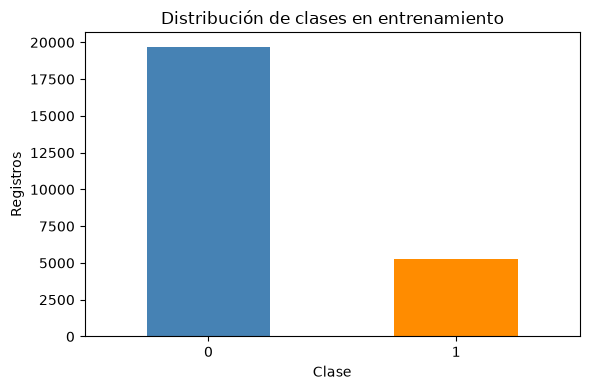

In [7]:
if y.isna().any() or not y.isin([0, 1]).all():
    raise ValueError("La variable objetivo contiene etiquetas ausentes o distintas de 0 y 1.")

class_counts = y.value_counts().reindex([0, 1], fill_value=0)
class_summary = pd.DataFrame({
    "Registros": class_counts,
    "Porcentaje": (class_counts / len(y) * 100).round(2),
})
class_summary.index.name = "Clase"
display(class_summary)
print(f"Exactitud de predecir siempre la clase mayoritaria: {class_counts.max() / len(y):.2%}")

ax = class_counts.plot.bar(color=["steelblue", "darkorange"], rot=0, figsize=(6, 4))
ax.set(title="Distribución de clases en entrenamiento", xlabel="Clase", ylabel="Registros")
plt.tight_layout()
plt.show()

De 25.000 registros, **19.697 (78,79 %) son clase 0 y 5.303 (21,21 %) clase 1**. Predecir siempre 0 daría 78,79 % de exactitud sin detectar ningún positivo, así que la evaluación debe mirar también sensibilidad y exactitud equilibrada.


### <a id="sec-2-5"></a> 2.5. Calidad, tipos y valores ausentes

Se identifican las variables numéricas y categóricas según su tipo en pandas y se revisan ausentes, infinitos, duplicados, identificadores compartidos y límites documentados. `unknown` y `other_or_unknown` son categorías, no ausentes. El test solo se usa aquí para comprobar su integridad y compatibilidad con entrenamiento, sin orientar decisiones de modelo o transformación.


In [8]:
numeric_features = X_raw.select_dtypes(include="number").columns.tolist()
categorical_features = [column for column in feature_columns if column not in numeric_features]

print(
    f"{len(feature_columns)} predictores: "
    f"{len(numeric_features)} numéricos y {len(categorical_features)} categóricos."
)

quality_tables = []
for name, frame in (("train.csv", train_raw), ("test.csv", test_raw)):
    quality_tables.append(pd.DataFrame({
        "Archivo": name,
        "Variable": frame.columns,
        "Tipo": frame.dtypes.astype(str).to_numpy(),
        "Ausentes": frame.isna().sum().to_numpy(),
        "Infinitos": [
            int(np.isinf(frame[column]).sum()) if column in numeric_features else 0
            for column in frame.columns
        ],
    }))

quality_summary = pd.concat(quality_tables, ignore_index=True)
problems = quality_summary[
    (quality_summary["Ausentes"] > 0) | (quality_summary["Infinitos"] > 0)
]
if problems.empty:
    print("Sin valores ausentes ni infinitos en train ni en test.")
else:
    display(problems)

duplicate_summary = pd.DataFrame([
    {
        "Archivo": name,
        "Filas duplicadas completas": int(frame.duplicated().sum()),
        "Identificadores repetidos": int(frame[ID_COLUMN].dropna().duplicated().sum()),
        "Perfiles de predictores repetidos": int(frame.duplicated(subset=feature_columns).sum()),
    }
    for name, frame in (("train.csv", train_raw), ("test.csv", test_raw))
])
display(duplicate_summary)

shared_ids = set(train_raw[ID_COLUMN].dropna()) & set(test_raw[ID_COLUMN].dropna())
labels_per_profile = train_raw.groupby(feature_columns, dropna=False)[TARGET].nunique()
print("Identificadores compartidos entre train y test:", len(shared_ids))
print("Perfiles con etiquetas diferentes:", int((labels_per_profile > 1).sum()))

bounded_domains = {
    "delayed_months_6m": (0, 6),
    "zero_payment_months_6m": (0, 6),
    "payment_to_bill_ratio_6m": (0, 5),
    "utilization_sep": (0, 2),
}
integer_counts = ["delayed_months_6m", "zero_payment_months_6m", "maximum_repayment_delay_6m"]
domain_results = []

for name, frame in (("train.csv", train_raw), ("test.csv", test_raw)):
    for column, (lower, upper) in bounded_domains.items():
        values = frame[column].dropna()
        domain_results.append({
            "Archivo": name,
            "Variable": column,
            "Comprobación": f"Intervalo [{lower}, {upper}]",
            "Incumplimientos": int((~values.between(lower, upper)).sum()),
        })
    for column in integer_counts:
        values = frame[column].dropna()
        invalid = (values < 0) | (values % 1 != 0)
        domain_results.append({
            "Archivo": name,
            "Variable": column,
            "Comprobación": "Entero no negativo",
            "Incumplimientos": int(invalid.sum()),
        })
    invalid_sex = frame["sex"].notna() & ~frame["sex"].isin(["female", "male"])
    domain_results.append({
        "Archivo": name,
        "Variable": "sex",
        "Comprobación": "female o male",
        "Incumplimientos": int(invalid_sex.sum()),
    })

domain_summary = pd.DataFrame(domain_results)
domain_pivot = (
    domain_summary.pivot_table(
        index=["Variable", "Comprobación"],
        columns="Archivo",
        values="Incumplimientos",
        aggfunc="sum",
    )
    .reset_index()
    .rename(columns={"train.csv": "Train", "test.csv": "Test"})
)
domain_pivot.columns.name = None
display(domain_pivot)
print("Incumplimientos totales:", int(domain_summary["Incumplimientos"].sum()))

15 predictores: 11 numéricos y 4 categóricos.
Sin valores ausentes ni infinitos en train ni en test.


,Archivo,Filas duplicadas completas,Identificadores repetidos,Perfiles de predictores repetidos
0,train.csv,0,0,31
1,test.csv,0,0,0


Identificadores compartidos entre train y test: 0
Perfiles con etiquetas diferentes: 13


,Variable,Comprobación,Test,Train
0,delayed_months_6m,Entero no negativo,0,0
1,delayed_months_6m,"Intervalo [0, 6]",0,0
2,maximum_repayment_delay_6m,Entero no negativo,0,0
3,payment_to_bill_ratio_6m,"Intervalo [0, 5]",0,0
4,sex,female o male,0,0
5,utilization_sep,"Intervalo [0, 2]",0,0
6,zero_payment_months_6m,Entero no negativo,0,0
7,zero_payment_months_6m,"Intervalo [0, 6]",0,0


Incumplimientos totales: 0


Los 15 predictores son **11 numéricos y 4 categóricos**. No hay ausentes, infinitos, filas duplicadas ni identificadores repetidos, y train y test no comparten identificadores. Las siete comprobaciones de dominio dan cero incumplimientos. Hay 31 perfiles repetidos y 13 perfiles con etiquetas distintas, lo que indica que los predictores no determinan por completo la etiqueta.


### <a id="sec-2-6"></a> 2.6. Distribuciones, asociaciones y fugas

Se resumen las distribuciones numéricas y categóricas y las asociaciones descriptivas con el objetivo. No se eliminan valores extremos ni se agrupan categorías.


,count,mean,std,min,25%,50%,75%,max,Asimetría
credit_limit,25000.0,167740.95,129975.98,10000.0,50000.00,140000.00,240000.00,1000000.0,0.99
age,25000.0,35.50,9.24,21.0,28.00,34.00,41.00,79.0,0.73
latest_repayment_status,25000.0,-0.02,1.12,-2.0,-1.00,0.00,0.00,8.0,0.71
maximum_repayment_delay_6m,25000.0,0.68,1.07,0.0,0.00,0.00,2.00,8.0,1.72
delayed_months_6m,25000.0,0.83,1.55,0.0,0.00,0.00,1.00,6.0,2.13
average_bill_6m,25000.0,44910.44,63267.26,-56000.0,4700.00,21000.00,57100.00,877300.0,2.75
bill_change_sep_to_apr,25000.0,12389.51,44068.85,-403600.0,-3000.00,900.00,19900.00,708300.0,2.38
total_payment_6m,25000.0,31635.05,57337.82,0.0,6700.00,14400.00,33700.00,2314200.0,8.96
payment_to_bill_ratio_6m,25000.0,0.37,0.59,0.0,0.04,0.09,0.60,5.0,3.94
zero_payment_months_6m,25000.0,1.23,1.72,0.0,0.00,0.00,2.00,6.0,1.44


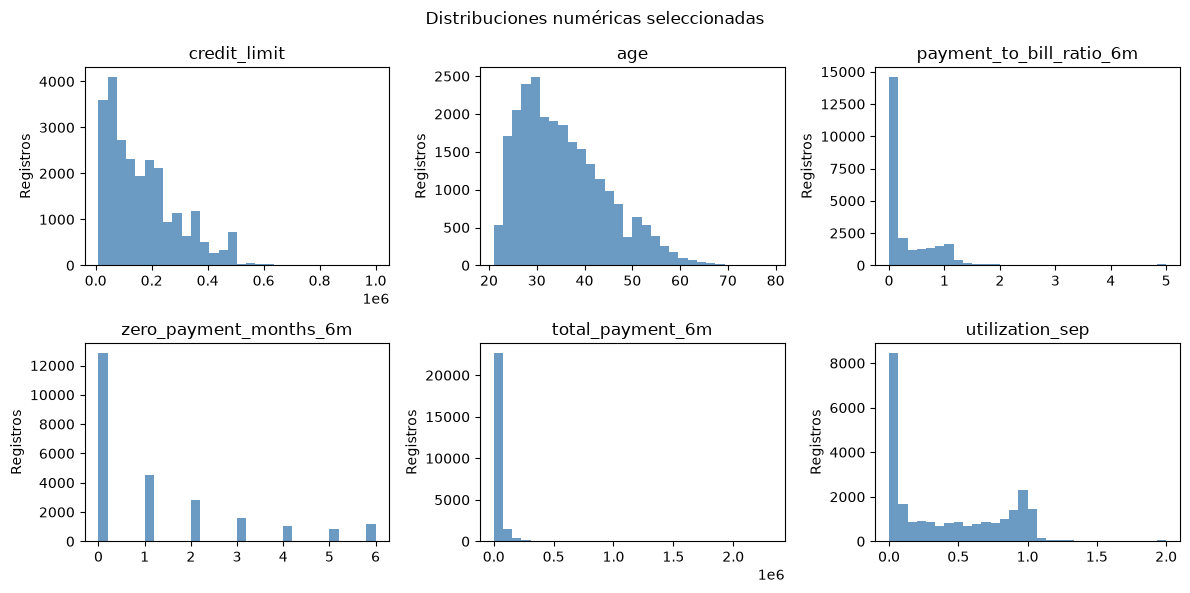

,Variable,Categoría,Registros,Porcentaje
0,sex,female,15130,60.52
1,sex,male,9870,39.48
2,education,university,11675,46.70
3,education,graduate_school,8820,35.28
4,education,high_school,4107,16.43
5,education,unknown,289,1.16
6,education,other,109,0.44
7,marital_status,single,13310,53.24
8,marital_status,married,11368,45.47
9,marital_status,other_or_unknown,322,1.29


In [9]:
numeric_summary = X_raw[numeric_features].describe().T
numeric_summary["Asimetría"] = X_raw[numeric_features].skew()
display(numeric_summary.round(2))

key_numeric = [
    "credit_limit", "age", "payment_to_bill_ratio_6m",
    "zero_payment_months_6m", "total_payment_6m", "utilization_sep",
]
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, column in zip(axes.flat, key_numeric):
    ax.hist(X_raw[column], bins=30, color="steelblue", alpha=0.8)
    ax.set_title(column)
    ax.set_ylabel("Registros")
fig.suptitle("Distribuciones numéricas seleccionadas")
plt.tight_layout()
plt.show()

categorical_tables = []
for column in categorical_features:
    counts = X_raw[column].value_counts(dropna=False)
    table = counts.rename_axis("Categoría").reset_index(name="Registros")
    table.insert(0, "Variable", column)
    table["Porcentaje"] = (table["Registros"] / len(X_raw) * 100).round(2)
    categorical_tables.append(table)

categorical_summary = pd.concat(categorical_tables, ignore_index=True)
display(categorical_summary)

In [10]:
association_tables = []
for column in ["repayment_assistance_plan", "sex"]:
    table = train_raw.groupby(column, dropna=False)[TARGET].agg(
        Registros="size", Casos_positivos="sum", Tasa_positiva="mean"
    ).reset_index().rename(columns={column: "Categoría"})
    table.insert(0, "Variable", column)
    table["Tasa positiva (%)"] = (table.pop("Tasa_positiva") * 100).round(2)
    association_tables.append(table)

display(pd.concat(association_tables, ignore_index=True))

spearman_corr = X_raw[numeric_features].corr(method="spearman")
upper_triangle = np.triu(np.ones(spearman_corr.shape, dtype=bool), k=1)
correlation_pairs = spearman_corr.where(upper_triangle).stack().rename("Spearman").reset_index()
correlation_pairs.columns = ["Variable 1", "Variable 2", "Spearman"]
correlation_pairs["Magnitud"] = correlation_pairs["Spearman"].abs()
display(correlation_pairs.sort_values("Magnitud", ascending=False).head(6).round(3))

,Variable,Categoría,Registros,Casos_positivos,Tasa positiva (%)
0,repayment_assistance_plan,no,19680,3565,18.11
1,repayment_assistance_plan,yes,5320,1738,32.67
2,sex,female,15130,3150,20.82
3,sex,male,9870,2153,21.81


,Variable 1,Variable 2,Spearman,Magnitud
37,maximum_repayment_delay_6m,delayed_months_6m,0.982,0.982
65,average_bill_6m,utilization_sep,0.747,0.747
26,latest_repayment_status,delayed_months_6m,0.647,0.647
98,payment_to_bill_ratio_6m,utilization_sep,-0.609,0.609
25,latest_repayment_status,maximum_repayment_delay_6m,0.607,0.607
62,average_bill_6m,total_payment_6m,0.598,0.598


- Importes monetarios asimétricos: `total_payment_6m` tiene mediana 14.400 NTD y media 31.635 NTD.
- `female` 60,52 % y `male` 39,48 %; educación se concentra en `university` (46,70 %) y `graduate_school` (35,28 %).
- Dificultad observada: 32,67 % con plan de asistencia y 18,11 % sin plan; asociación descriptiva, no causal.
- Correlación máxima: `maximum_repayment_delay_6m`–`delayed_months_6m` (Spearman 0,982), seguida de `average_bill_6m`–`utilization_sep` (0,747). No se eliminan variables por estas asociaciones.


**Revisión de fugas.** `row_id` se excluye; el objetivo y `predicted_class` no pueden ser entradas. Los resúmenes de pagos, facturas y retrasos cubren los seis meses anteriores al resultado. El plan de asistencia es anterior, pero su asignación selectiva hace que se conserve sin interpretarlo como causa.


In [11]:
excluded_columns = {ID_COLUMN, TARGET, PREDICTION_COLUMN}
leaked_columns = excluded_columns.intersection(X_raw.columns)
if leaked_columns:
    raise ValueError(f"Columnas que deben excluirse de los predictores: {sorted(leaked_columns)}")
if list(X_raw.columns) != list(X_test_raw.columns):
    raise ValueError("El orden de predictores no coincide entre entrenamiento y test.")
print("Identificador, objetivo y salida de entrega excluidos de los predictores.")
print("Mismo orden de columnas predictoras en entrenamiento y test.")

Identificador, objetivo y salida de entrega excluidos de los predictores.
Mismo orden de columnas predictoras en entrenamiento y test.


**Síntesis.** El desequilibrio (21,21 %) exige métricas complementarias; no hay problemas de calidad y los dominios se cumplen; la asimetría y las escalas justifican estandarizar la logística; se conservan todos los registros, incluidos los 31 perfiles repetidos (13 con etiquetas distintas); los resúmenes de retraso obligan a interpretar sus coeficientes y contribuciones en conjunto; y el plan de asistencia se asocia con más dificultad, pero no se lee como causa.


### <a id="sec-2-7"></a> 2.7. Decisiones de preprocesamiento

El preprocesamiento se ajusta dentro de cada entrenamiento, conserva los nombres de las variables y no elimina registros, categorías ni valores extremos.

| Familia | Numéricas | Categóricas | Ausentes |
| --- | --- | --- | --- |
| Árbol | Sin escalado | One-hot con todas las categorías | Mediana / categoría más frecuente |
| Regresión logística | Estandarización | One-hot con categoría de referencia | Mediana / categoría más frecuente |
| EBM | Sin transformar | Categorías originales | Tratamiento nativo de EBM |

`unknown` y `other_or_unknown` se mantienen como categorías documentadas. `latest_repayment_status` se trata inicialmente como numérica; en regresión logística esto impone linealidad en los log-odds, que se comentará al interpretar sus coeficientes.

El one-hot evita asignar un orden artificial a las categóricas: el árbol conserva todas las categorías y la logística elimina la primera como referencia; es una elección inicial, no necesariamente la mejor para todas las configuraciones de regularización. Con `handle_unknown="ignore"`, una categoría nueva se representa con ceros: se evita un error al transformar la validación, pero no se aprende un efecto específico y, en logística, coincide con la referencia. `StandardScaler` solo se aplica a las numéricas de logística para que la penalización no dependa de la escala; árbol y EBM no se escalan. Los transformadores se construyen sin ajustar y devuelven DataFrames con nombres de columnas.


In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def make_preprocessor(family, selected_features=None):
    """Construye el preprocesamiento; todavía no aprende ningún parámetro."""
    if family not in ("tree", "logistic", "ebm"):
        raise ValueError("Familia no reconocida: usa tree, logistic o ebm.")
    columns = list(feature_columns if selected_features is None else selected_features)
    if not columns or len(columns) != len(set(columns)):
        raise ValueError("Selecciona al menos una variable y evita nombres repetidos.")
    unknown_columns = set(columns) - set(feature_columns)
    if unknown_columns:
        raise ValueError(f"Variables no disponibles: {sorted(unknown_columns)}")
    num_columns = [column for column in columns if column in numeric_features]
    cat_columns = [column for column in columns if column in categorical_features]

    if family == "ebm":
        # Selecciona las columnas en su orden original, conservando sus tipos.
        transformations = [("original", "passthrough", columns)]
    else:
        numeric_steps = [("imputer", SimpleImputer(strategy="median", keep_empty_features=True))]
        if family == "logistic":
            numeric_steps.append(("scaler", StandardScaler()))
        categorical_steps = [
            ("imputer", SimpleImputer(strategy="most_frequent", keep_empty_features=True)),
            ("encoder", OneHotEncoder(
                drop="first" if family == "logistic" else None,
                handle_unknown="ignore", sparse_output=False,
            )),
        ]
        transformations = [
            ("numeric", Pipeline(numeric_steps), num_columns),
            ("categorical", Pipeline(categorical_steps), cat_columns),
        ]

    return ColumnTransformer(
        transformations, remainder="drop", verbose_feature_names_out=False
    ).set_output(transform="pandas")

### <a id="sec-2-8"></a> 2.8. Integración con los modelos y validación cruzada

Cada pipeline contiene `preprocess` y `model`: al ajustar en una partición, el preprocesamiento aprende solo con el entrenamiento y el modelo se entrena con esa representación; las funciones crean pipelines nuevos para no compartir transformadores ajustados.

La regresión logística usa scikit-learn para seleccionar hiperparámetros con `GridSearchCV`; InterpretML se reserva para las explicaciones. EBM usa `interactions=0`. Los parámetros iniciales no son configuraciones seleccionadas: se ajustan en los apartados 4–6, donde los datos originales y el pipeline completo se pasan a las búsquedas internas. No se codifica ni escala `X_raw` antes de validar: categorías, imputaciones, medias y desviaciones se aprenden en cada entrenamiento. El número de columnas one-hot puede variar si falta un nivel poco frecuente en algún entrenamiento. Cada modelo conserva sus nombres transformados y sus referencias; EBM mantiene las variables originales y aprende sus intervalos internamente.


In [18]:
def make_tree_pipeline(selected_features=None, **model_params):
    params = {"random_state": SEED, **model_params}
    return Pipeline([
        ("preprocess", make_preprocessor("tree", selected_features)),
        ("model", DecisionTreeClassifier(**params)),
    ])


def make_logistic_pipeline(selected_features=None, **model_params):
    from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression

    params = {
        "random_state": SEED, "penalty": "l2", "solver": "liblinear",
        "max_iter": 2000, **model_params,
    }
    return Pipeline([
        ("preprocess", make_preprocessor("logistic", selected_features)),
        ("model", SklearnLogisticRegression(**params)),
    ])


def make_ebm_pipeline(selected_features=None, **model_params):
    if model_params.get("interactions", 0) != 0:
        raise ValueError("El EBM del proyecto debe utilizar interactions=0.")
    params = {"random_state": SEED, "n_jobs": N_JOBS, **model_params, "interactions": 0}
    return Pipeline([
        ("preprocess", make_preprocessor("ebm", selected_features)),
        ("model", ExplainableBoostingClassifier(**params)),
    ])

[Volver al índice](#indice)


## <a id="sec-3"></a> 3. Diseño de la evaluación

El protocolo se fija antes de entrenar para comparar las tres familias en las mismas condiciones. Solo se usa `train.csv`; el test se reserva para la predicción final.

### <a id="sec-3-1"></a> 3.1. Cinco particiones comunes

Se usan cinco particiones externas, con aproximadamente un 80 % para entrenamiento y un 20 % para validación. Cada registro se valida una vez y se entrena cuatro.

Los perfiles de predictores repetidos se mantienen en la misma partición mediante `StratifiedGroupKFold`, agrupando por la combinación de los 15 predictores. Las particiones se generan una sola vez con `SEED = 42` y se guardan en `cv_splits`.


In [12]:
from sklearn.model_selection import StratifiedGroupKFold, cross_validate

N_SPLITS = 5

# Los perfiles idénticos reciben el mismo grupo; la etiqueta no interviene.
profile_groups, unique_profiles = pd.factorize(pd.MultiIndex.from_frame(X_raw))
outer_cv = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
cv_splits = list(outer_cv.split(X_raw, y, groups=profile_groups))

fold_rows = []
validation_coverage = np.zeros(len(y), dtype=int)
for fold, (train_idx, valid_idx) in enumerate(cv_splits, start=1):
    shared_profiles = np.intersect1d(profile_groups[train_idx], profile_groups[valid_idx])
    if len(shared_profiles):
        raise ValueError(f"Hay perfiles compartidos en la partición {fold}.")
    if y.iloc[train_idx].nunique() != 2 or y.iloc[valid_idx].nunique() != 2:
        raise ValueError(f"Falta una clase en la partición {fold}.")
    validation_coverage[valid_idx] += 1
    fold_rows.append({
        "Partición": fold,
        "Registros de entrenamiento": len(train_idx),
        "Registros de validación": len(valid_idx),
        "Clase 1 en entrenamiento (%)": round(y.iloc[train_idx].mean() * 100, 2),
        "Clase 1 en validación (%)": round(y.iloc[valid_idx].mean() * 100, 2),
        "Perfiles compartidos": len(shared_profiles),
    })

if not np.all(validation_coverage == 1):
    raise ValueError("Cada registro debe aparecer exactamente una vez en validación.")
fold_summary = pd.DataFrame(fold_rows)
display(fold_summary)
print(f"Perfiles distintos: {len(unique_profiles)} | Registros: {len(y)}")
print("Cada registro aparece exactamente una vez en validación.")

,Partición,Registros de entrenamiento,Registros de validación,Clase 1 en entrenamiento (%),Clase 1 en validación (%),Perfiles compartidos
0,1,20000,5000,21.22,21.20,0
1,2,20000,5000,21.21,21.22,0
2,3,19999,5001,21.21,21.22,0
3,4,20000,5000,21.21,21.22,0
4,5,20001,4999,21.21,21.20,0


Perfiles distintos: 24969 | Registros: 25000
Cada registro aparece exactamente una vez en validación.


**Lectura.** Las validaciones contienen 4.997–5.004 registros y entre 20,66 % y 21,90 % de clase 1, cerca del 21,21 % global. Hay 24.969 perfiles distintos en 25.000 registros, no se comparte ningún perfil entre entrenamiento y validación y cada registro se valida exactamente una vez.


### <a id="sec-3-2"></a> 3.2. Métricas y criterio de selección

La clase positiva es **1: dificultad de pago**. Se registran seis métricas:

| Métrica | Uso en la evaluación |
| --- | --- |
| ROC-AUC | Discriminación sin fijar umbral; criterio para elegir configuraciones. No mide calibración. |
| Exactitud | Proporción de aciertos; se compara con la referencia mayoritaria del 78,79 %. |
| Exactitud equilibrada | Media de sensibilidad y especificidad; criterio para elegir el umbral. |
| Sensibilidad | Detección de positivos; permite valorar los falsos negativos. |
| Precisión | Proporción de positivos correctos entre los clasificados como positivos. |
| F1 | Media armónica de precisión y sensibilidad. |

La configuración se elige por la mayor ROC-AUC media en validación interna; el umbral, por la mayor exactitud equilibrada media. Los empates se resuelven hacia la opción más sencilla y, para el umbral, hacia el valor más cercano a 0,5.

La desviación típica entre particiones se describe, no se usa como prueba de significación. Para las métricas con etiquetas se usa `zero_division=0`.


In [13]:
from sklearn.metrics import f1_score, make_scorer, precision_score, recall_score

SCORING = {
    "roc_auc": "roc_auc",
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "recall": make_scorer(recall_score, pos_label=1, zero_division=0),
    "precision": make_scorer(precision_score, pos_label=1, zero_division=0),
    "f1": make_scorer(f1_score, pos_label=1, zero_division=0),
}

PRIMARY_METRIC = "roc_auc"
THRESHOLD_METRIC = "balanced_accuracy"
DEFAULT_THRESHOLD = 0.5
THRESHOLD_GRID = np.round(np.arange(0.05, 1.00, 0.05), 2)


### <a id="sec-3-3"></a> 3.3. Referencia de la clase mayoritaria

Un `DummyClassifier` predice siempre la clase mayoritaria aprendida en cada entrenamiento. Sirve para cuantificar qué aporta cada modelo frente a una regla que ignora los predictores.


In [14]:
from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(strategy="most_frequent", random_state=SEED)
baseline_cv = cross_validate(
    baseline, X_raw, y, cv=cv_splits, scoring=SCORING,
    n_jobs=N_JOBS, error_score="raise",
)

baseline_scores = pd.DataFrame({
    metric: baseline_cv[f"test_{metric}"] for metric in SCORING
})
baseline_scores.index = pd.Index(range(1, N_SPLITS + 1), name="Partición")

baseline_summary = pd.DataFrame({
    "Media": baseline_scores.mean(),
    "Desviación típica": baseline_scores.std(ddof=1),
})
display(baseline_summary.round(4))


,Media,Desviación típica
roc_auc,0.5000,0.0000
accuracy,0.7879,0.0001
balanced_accuracy,0.5000,0.0000
recall,0.0000,0.0000
precision,0.0000,0.0000
f1,0.0000,0.0000


La referencia obtiene **78,79 % ± 0,52%** de exactitud, pero ROC-AUC y exactitud equilibrada de 0,5 y sensibilidad, precisión y F1 de cero. Su exactitud refleja el desequilibrio de clases, no capacidad de detección.


### <a id="sec-3-4"></a> 3.4. Ajuste de configuraciones, variables y umbrales

Se usa **validación cruzada anidada**. Para cada familia y cada partición externa:

1. Se crean cinco particiones internas solo con el entrenamiento externo, manteniendo juntos los perfiles repetidos.
2. Se selecciona la configuración por ROC-AUC media interna. La selección de variables o transformaciones, si se prueba, forma parte de esta búsqueda.
3. Con la configuración elegida se obtienen probabilidades OOF internas y se elige el umbral por exactitud equilibrada media.
4. Se reentrena con todo el entrenamiento externo y se evalúa una vez en su validación externa, con el umbral interno y con 0,5.
5. Se repite en las cinco particiones externas y se guardan configuraciones, umbrales y predicciones OOF.

Las métricas internas pueden ser optimistas porque se usan para seleccionar; las externas evalúan decisiones que no consultaron la validación.

<a id="sec-3-4-1"></a>
`make_inner_splits` construye las particiones internas. `metric_scores` calcula las seis métricas para un umbral. `choose_threshold` promedia la exactitud equilibrada de cada umbral y ordena por puntuación, distancia a 0,5 y umbral.


In [15]:
def make_inner_splits(outer_train_idx):
    """Devuelve índices relativos al subconjunto de entrenamiento externo."""
    inner_X = X_raw.iloc[outer_train_idx]
    inner_y = y.iloc[outer_train_idx]
    inner_groups = profile_groups[outer_train_idx]

    inner_cv = StratifiedGroupKFold(
        n_splits=N_SPLITS, shuffle=True, random_state=SEED
    )
    inner_splits = list(inner_cv.split(inner_X, inner_y, groups=inner_groups))

    for train_idx, valid_idx in inner_splits:
        if len(np.intersect1d(inner_groups[train_idx], inner_groups[valid_idx])):
            raise ValueError("Hay perfiles compartidos en una partición interna.")
        if inner_y.iloc[train_idx].nunique() != 2 or inner_y.iloc[valid_idx].nunique() != 2:
            raise ValueError("Falta una clase en una partición interna.")

    return inner_splits


In [16]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, roc_auc_score


def metric_scores(y_true, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(int)
    return {
        "roc_auc": roc_auc_score(y_true, probabilities),
        "accuracy": accuracy_score(y_true, predictions),
        "balanced_accuracy": balanced_accuracy_score(y_true, predictions),
        "recall": recall_score(y_true, predictions, pos_label=1, zero_division=0),
        "precision": precision_score(y_true, predictions, pos_label=1, zero_division=0),
        "f1": f1_score(y_true, predictions, pos_label=1, zero_division=0),
    }


def choose_threshold(inner_y, inner_probabilities, inner_splits):
    rows = []
    for threshold in THRESHOLD_GRID:
        fold_scores = [
            balanced_accuracy_score(
                inner_y.iloc[valid_idx],
                (inner_probabilities[valid_idx] >= threshold).astype(int),
            )
            for _, valid_idx in inner_splits
        ]
        rows.append({
            "Umbral": threshold,
            "Exactitud equilibrada interna": np.mean(fold_scores),
            "Desviación típica": np.std(fold_scores, ddof=1),
            "Distancia a 0,5": abs(threshold - DEFAULT_THRESHOLD),
        })

    table = pd.DataFrame(rows).sort_values(
        ["Exactitud equilibrada interna", "Distancia a 0,5", "Umbral"],
        ascending=[False, True, True],
    )
    return float(table.iloc[0]["Umbral"]), table


### <a id="sec-3-5"></a> 3.5. Comparación y entrenamiento final

Las tres familias se compararán con las mismas particiones, primero por ROC-AUC externa y después por exactitud equilibrada, F1, precisión y sensibilidad. Si el rendimiento es próximo, se preferirá la representación más sencilla e interpretable.

Tras elegir la familia, el apartado 10 repetirá la búsqueda sobre todos los datos etiquetados y fijará la configuración y el umbral finales. El apartado 11 aplicará ese modelo al test sin modificar sus filas ni columnas originales, añadiendo solo `predicted_class`.

[Volver al índice](#indice)


## <a id="sec-4"></a> 4. Modelo lógico

### <a id="sec-4-1"></a> 4.1. Árbol de decisión y presupuesto de complejidad

Se usa un CART (`DecisionTreeClassifier`) como modelo lógico: cada recorrido raíz-hoja es una regla y cada hoja estima P(1) con la proporción de positivos de su entrenamiento. Se busca una estructura inspeccionable, así que la búsqueda se limita a profundidades 1–3 (máximo 2, 4 y 8 hojas) y mínimos de 50, 200 o 500 registros por hoja.
El objetivo es obtener una estructura que pueda inspeccionarse completa. Por ello, **la búsqueda se restringe de antemano a profundidades 1, 2 y 3**, con un máximo de 2, 4 y 8 hojas, respectivamente. La profundidad limita el número de decisiones consecutivas; el mínimo de registros por hoja evita reglas apoyadas en grupos demasiado pequeños. Estos controles no garantizan por sí solos estabilidad o ausencia de sobreajuste.

| Parámetro | Valores |
| --- | --- |
| `max_depth` | 1, 2, 3 |
| `min_samples_leaf` | 50, 200, 500 |

La rejilla no impone la profundidad 2 ni el mínimo 200 de la entrega parcial. Se mantienen los 15 predictores, se usa Gini, sin pesos de clase ni poda adicional. La configuración se elige por ROC-AUC interna y el umbral por exactitud equilibrada interna. Las importancias Gini se interpretarán con cautela, especialmente al comparar variables con distinta cardinalidad.

Se utiliza el criterio Gini y no se aplican pesos de clase ni poda adicional en esta búsqueda. Las importancias por reducción de impureza se interpretarán con cautela, especialmente al comparar variables con distinta cardinalidad. La selección de configuraciones sigue la ROC-AUC interna acordada, dentro del presupuesto de complejidad fijado, y el ajuste del umbral sigue la exactitud equilibrada interna.

In [19]:
from time import perf_counter
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, ParameterGrid, cross_val_predict, cross_validate

TREE_PARAM_GRID = {
    "model__max_depth": [1, 2, 3],
    "model__min_samples_leaf": [50, 200, 500],
}
tree_base_pipeline = make_tree_pipeline(criterion="gini")

### <a id="sec-4-2"></a> 4.2. Diagnóstico de un árbol sin restricciones

Antes de interpretar los árboles pequeños se evalúa un CART sin límite de profundidad y con una observación mínima por hoja. Es solo un diagnóstico, ya que no participa en la búsqueda ni se usa para ampliar la rejilla.

In [20]:
tree_unrestricted_cv = cross_validate(
    make_tree_pipeline(criterion="gini", max_depth=None, min_samples_leaf=1),
    X_raw, y, cv=cv_splits, scoring=SCORING,
    return_train_score=True, return_estimator=True,
    n_jobs=N_JOBS, error_score="raise",
)
tree_unrestricted_complexity = pd.DataFrame([
    {"Partición": fold, "Profundidad": pipeline["model"].get_depth(),
     "Hojas": pipeline["model"].get_n_leaves(),
     "Nodos": pipeline["model"].tree_.node_count}
    for fold, pipeline in enumerate(tree_unrestricted_cv.pop("estimator"), start=1)
]).set_index("Partición")
tree_unrestricted_summary = pd.DataFrame({
    "Media en entrenamiento": {
        metric: np.mean(tree_unrestricted_cv[f"train_{metric}"]) for metric in SCORING
    },
    "Media en validación": {
        metric: np.mean(tree_unrestricted_cv[f"test_{metric}"]) for metric in SCORING
    },
    "Desviación típica en validación": {
        metric: np.std(tree_unrestricted_cv[f"test_{metric}"], ddof=1) for metric in SCORING
    },
})
display(tree_unrestricted_summary.round(4))
display(tree_unrestricted_complexity)

,Media en entrenamiento,Media en validación,Desviación típica en validación
roc_auc,1.0000,0.5963,0.0087
accuracy,0.9995,0.7216,0.0062
balanced_accuracy,0.9988,0.5955,0.0081
recall,0.9977,0.3764,0.0164
precision,0.9998,0.3535,0.0120
f1,0.9988,0.3645,0.0127


,Profundidad,Hojas,Nodos
Partición,,,
1,44,3604,7207
2,41,3555,7109
3,43,3597,7193
4,42,3599,7197
5,40,3644,7287


El árbol sin restricciones alcanza ROC-AUC ≈ 1 y 99,95 % de exactitud en entrenamiento, pero 0,5985 de ROC-AUC y 72,26 % de exactitud en validación lo que indica un claro sobreajuste a los datos de entrenamiento. Sus 37–54 niveles y 3.522–3.673 hojas lo hacen impracticable como explicación global. El diagnóstico respalda el límite de profundidad.

### <a id="sec-4-3"></a> 4.3. Evaluación anidada y resultados externos

Para cada partición externa se comparan las nueve configuraciones en cinco particiones internas. El preprocesamiento se ajusta dentro de cada entrenamiento y los perfiles repetidos se mantienen juntos. Con la configuración elegida se generan probabilidades OOF internas, se elige el umbral y se reentrena con todo el entrenamiento externo para evaluar una vez su validación.

La celda realiza 255 ajustes y guarda modelos, búsquedas, umbrales y predicciones OOF. No se entrena aún el modelo final.

Además del rendimiento, se registran la profundidad efectiva, las hojas, los nodos y el número de columnas transformadas utilizadas. El nombre de la raíz y estas medidas permiten iniciar la revisión de estabilidad, pero no sustituyen la comparación posterior de las reglas completas.

In [21]:
tree_models = []
tree_search_results = []
tree_threshold_tables = []
tree_settings_rows = []
tree_default_rows = []
tree_tuned_rows = []
tree_oof_probability = np.full(len(y), np.nan)
tree_oof_threshold = np.full(len(y), np.nan)
tree_oof_fold = np.zeros(len(y), dtype=int)

for fold, (outer_train_idx, outer_valid_idx) in enumerate(cv_splits, start=1):
    fold_start = perf_counter()
    print(f"Árbol {fold}/{N_SPLITS}: búsqueda interna de nueve configuraciones.", flush=True)
    inner_X = X_raw.iloc[outer_train_idx]
    inner_y = y.iloc[outer_train_idx]
    inner_splits = make_inner_splits(outer_train_idx)
    search = GridSearchCV(
        clone(tree_base_pipeline), TREE_PARAM_GRID, cv=inner_splits,
        scoring=SCORING, refit=False, return_train_score=True,
        n_jobs=N_JOBS, error_score="raise",
    )
    search.fit(inner_X, inner_y)
    search_table = pd.DataFrame(search.cv_results_).sort_values(
        ["mean_test_roc_auc", "param_model__max_depth", "param_model__min_samples_leaf"],
        ascending=[False, True, False],
    )
    best_row = search_table.iloc[0]
    best_params = best_row["params"]
    selected_pipeline = clone(tree_base_pipeline).set_params(**best_params)
    inner_probability = cross_val_predict(
        selected_pipeline, inner_X, inner_y, cv=inner_splits,
        method="predict_proba", n_jobs=N_JOBS,
    )[:, 1]
    threshold, threshold_table = choose_threshold(inner_y, inner_probability, inner_splits)
    selected_pipeline.fit(inner_X, inner_y)
    model = selected_pipeline["model"]
    if not np.array_equal(model.classes_, [0, 1]):
        raise ValueError("El orden de clases esperado es [0, 1].")
    outer_probability = selected_pipeline.predict_proba(X_raw.iloc[outer_valid_idx])[:, 1]
    outer_y = y.iloc[outer_valid_idx]
    tree_default_rows.append(metric_scores(outer_y, outer_probability, DEFAULT_THRESHOLD))
    tree_tuned_rows.append(metric_scores(outer_y, outer_probability, threshold))
    tree_oof_probability[outer_valid_idx] = outer_probability
    tree_oof_threshold[outer_valid_idx] = threshold
    tree_oof_fold[outer_valid_idx] = fold

    feature_names = selected_pipeline["preprocess"].get_feature_names_out()
    used_columns = np.unique(model.tree_.feature[model.tree_.feature >= 0])
    root_feature = int(model.tree_.feature[0])
    tree_settings_rows.append({
        "Partición": fold,
        "max_depth": best_params["model__max_depth"],
        "min_samples_leaf": best_params["model__min_samples_leaf"],
        "ROC-AUC interna": best_row["mean_test_roc_auc"],
        "ROC-AUC entrenamiento": roc_auc_score(inner_y, selected_pipeline.predict_proba(inner_X)[:, 1]),
        "Umbral": threshold,
        "Profundidad efectiva": model.get_depth(),
        "Hojas": model.get_n_leaves(),
        "Nodos": model.tree_.node_count,
        "Columnas utilizadas": len(used_columns),
        "Raíz": feature_names[root_feature] if root_feature >= 0 else "Hoja sin división",
    })
    tree_models.append(selected_pipeline)
    tree_search_results.append(search_table)
    tree_threshold_tables.append(threshold_table)
    print(f"Partición {fold}/{N_SPLITS} completada en {perf_counter() - fold_start:.1f} s: "
          f"profundidad máxima={best_params['model__max_depth']}, "
          f"mínimo por hoja={best_params['model__min_samples_leaf']}, "
          f"umbral={threshold:.2f}", flush=True)

if not np.isfinite(tree_oof_probability).all() or not np.all(tree_oof_fold > 0):
    raise ValueError("Faltan predicciones externas OOF del árbol.")
tree_fold_settings = pd.DataFrame(tree_settings_rows).set_index("Partición")
tree_scores_default = pd.DataFrame(tree_default_rows, index=tree_fold_settings.index)
tree_scores_tuned = pd.DataFrame(tree_tuned_rows, index=tree_fold_settings.index)
tree_oof_results = pd.DataFrame({
    ID_COLUMN: train_raw[ID_COLUMN],
    "true_class": y,
    "fold": tree_oof_fold,
    "probability_class_1": tree_oof_probability,
    "threshold": tree_oof_threshold,
    "prediction_default": (tree_oof_probability >= DEFAULT_THRESHOLD).astype(int),
    "prediction_tuned": (tree_oof_probability >= tree_oof_threshold).astype(int),
}, index=X_raw.index)
display(tree_fold_settings.round(4))

Árbol 1/5: búsqueda interna de nueve configuraciones.
Partición 1/5 completada en 8.9 s: profundidad máxima=3, mínimo por hoja=500, umbral=0.25
Árbol 2/5: búsqueda interna de nueve configuraciones.
Partición 2/5 completada en 8.9 s: profundidad máxima=3, mínimo por hoja=500, umbral=0.25
Árbol 3/5: búsqueda interna de nueve configuraciones.
Partición 3/5 completada en 8.9 s: profundidad máxima=3, mínimo por hoja=500, umbral=0.25
Árbol 4/5: búsqueda interna de nueve configuraciones.
Partición 4/5 completada en 9.2 s: profundidad máxima=3, mínimo por hoja=500, umbral=0.25
Árbol 5/5: búsqueda interna de nueve configuraciones.
Partición 5/5 completada en 8.9 s: profundidad máxima=3, mínimo por hoja=500, umbral=0.20


,max_depth,min_samples_leaf,ROC-AUC interna,ROC-AUC entrenamiento,Umbral,Profundidad efectiva,Hojas,Nodos,Columnas utilizadas,Raíz
Partición,,,,,,,,,,
1,3,500,0.7383,0.7403,0.25,3,8,15,6,latest_repayment_status
2,3,500,0.7343,0.7368,0.25,3,8,15,5,latest_repayment_status
3,3,500,0.7381,0.7399,0.25,3,8,15,5,latest_repayment_status
4,3,500,0.7381,0.7413,0.25,3,8,15,4,latest_repayment_status
5,3,500,0.7400,0.7437,0.20,3,8,15,4,latest_repayment_status


Las cinco búsquedas seleccionan `max_depth=3`, `min_samples_leaf=500` y umbral 0,25. Los cinco árboles tienen profundidad efectiva 3, ocho hojas y quince nodos; la raíz es `latest_repayment_status`, pero usan entre 3 y 5 variables transformadas.

La evaluación externa compara las métricas con 0,5 y con el umbral interno. Cambiar el umbral no altera la estructura ni las probabilidades, solo qué hojas predicen clase 1; por eso ROC-AUC debe coincidir.

In [22]:
tree_summary_default = pd.DataFrame({
    "Media": tree_scores_default.mean(),
    "Desviación típica": tree_scores_default.std(ddof=1),
})
tree_summary_tuned = pd.DataFrame({
    "Media": tree_scores_tuned.mean(),
    "Desviación típica": tree_scores_tuned.std(ddof=1),
})
tree_comparison = pd.concat({
    "Referencia mayoritaria": baseline_summary,
    "Árbol: umbral 0,5": tree_summary_default,
    "Árbol: umbral ajustado": tree_summary_tuned,
}, axis=1)
display(tree_comparison.round(4))

Referencia mayoritaria                   Árbol: umbral 0,5  \
                                   Media Desviación típica             Media   
roc_auc                           0.5000            0.0000            0.7360   
accuracy                          0.7879            0.0001            0.8044   
balanced_accuracy                 0.5000            0.0000            0.5625   
recall                            0.0000            0.0000            0.1424   
precision                         0.0000            0.0000            0.6876   
f1                                0.0000            0.0000            0.2357   

                                    Árbol: umbral ajustado                    
                  Desviación típica                  Media Desviación típica  
roc_auc                      0.0064                 0.7360            0.0064  
accuracy                     0.0019                 0.7743            0.0151  
balanced_accuracy            0.0054                 0.6709            0.0083  
recall                       0.0119                 0.4912            0.0184  
precision                    0.0140                 0.4713            0.0286  
f1                           0.0166                 0.4804            0.0140

**ROC-AUC externa media 0,7372 ± 0,0044**. Con umbral 0,5 la exactitud es 80,40 %, la precisión 68,12 %, pero la sensibilidad solo 14,31 % (exactitud equilibrada 56,25 %, F1 0,2364). Con umbral 0,25 la sensibilidad sube a 48,90 %, la exactitud equilibrada a 67,32 % y F1 a 0,4846; la precisión baja a 48,05 % y la exactitud a 77,93 %. El ajuste mejora la detección a costa de más falsos positivos. El umbral 0,25 en los cinco entrenamientos no lo convierte todavía en un umbral final ni demuestra que sea óptimo fuera de la rejilla. Se conserva la distinción entre probabilidades aprendidas y regla de clasificación.

### <a id="sec-4-4"></a> 4.4. Árbol de referencia, reglas y probabilidades de las hojas

Se explica el árbol de la partición 1, elegido por su posición. La tabla siguiente contiene la regla completa de cada hoja, el soporte y los positivos de entrenamiento, la probabilidad aprendida y la tasa positiva en validación. Las etiquetas se muestran con 0,5 y con el umbral interno de esa partición.

Las condiciones impresas redondean los umbrales, pero las asignaciones usan el modelo sin redondear. La tasa de validación no se utiliza para modificar la regla ni la probabilidad de la hoja.

In [23]:
TREE_REFERENCE_FOLD = 1
tree_reference_pipeline = tree_models[TREE_REFERENCE_FOLD - 1]
tree_reference_model = tree_reference_pipeline["model"]
tree_reference_names = tree_reference_pipeline["preprocess"].get_feature_names_out()
tree_reference_train_idx, tree_reference_valid_idx = cv_splits[TREE_REFERENCE_FOLD - 1]
tree_reference_threshold = float(tree_fold_settings.loc[TREE_REFERENCE_FOLD, "Umbral"])


def leaf_rules(model, names):
    """Condiciones raíz-hoja; los umbrales se redondean solo para mostrarlos."""
    rules = {}
    def visit(node, conditions):
        left = model.tree_.children_left[node]
        right = model.tree_.children_right[node]
        if left == right:
            rules[node] = " Y ".join(conditions) if conditions else "Sin condiciones"
            return
        name = names[model.tree_.feature[node]]
        threshold = model.tree_.threshold[node]
        visit(left, conditions + [f"{name} <= {threshold:.6g}"])
        visit(right, conditions + [f"{name} > {threshold:.6g}"])
    visit(0, [])
    return rules


tree_reference_rules = leaf_rules(tree_reference_model, tree_reference_names)
reference_train_data = tree_reference_pipeline["preprocess"].transform(X_raw.iloc[tree_reference_train_idx])
reference_valid_data = tree_reference_pipeline["preprocess"].transform(X_raw.iloc[tree_reference_valid_idx])
reference_train_leaves = tree_reference_model.apply(reference_train_data)
reference_valid_leaves = tree_reference_model.apply(reference_valid_data)
reference_train_y = y.iloc[tree_reference_train_idx].to_numpy()
reference_valid_y = y.iloc[tree_reference_valid_idx].to_numpy()
leaf_rows = []
for node, rule in tree_reference_rules.items():
    training_mask = reference_train_leaves == node
    validation_mask = reference_valid_leaves == node
    count = int(training_mask.sum())
    positives = int(reference_train_y[training_mask].sum())
    probability = positives / count
    values = tree_reference_model.tree_.value[node][0]
    if not np.isclose(probability, values[1] / values.sum()):
        raise ValueError("La proporción observada no coincide con la probabilidad de la hoja.")
    leaf_rows.append({
        "Hoja": node, "Regla": rule,
        "Registros entrenamiento": count, "Positivos entrenamiento": positives,
        "Probabilidad aprendida": probability,
        "Registros validación": int(validation_mask.sum()),
        "Tasa positiva validación": float(reference_valid_y[validation_mask].mean()) if validation_mask.any() else np.nan,
        "Clase con 0,5": int(probability >= DEFAULT_THRESHOLD),
        "Clase con umbral interno": int(probability >= tree_reference_threshold),
    })
tree_leaf_summary = pd.DataFrame(leaf_rows).set_index("Hoja")
with pd.option_context("display.max_colwidth", None, "display.max_columns", None):
    display(tree_leaf_summary.round(4))
print(f"Umbral interno del modelo explicado: {tree_reference_threshold:.2f}")

,Regla,Registros entrenamiento,Positivos entrenamiento,Probabilidad aprendida,Registros validación,Tasa positiva validación,"Clase con 0,5",Clase con umbral interno
Hoja,,,,,,,,
3,latest_repayment_status <= 0.5 Y payment_to_bill_ratio_6m <= 0.105 Y zero_payment_months_6m <= 4.5,6831,1337,0.1957,1713,0.1996,0,0
4,latest_repayment_status <= 0.5 Y payment_to_bill_ratio_6m <= 0.105 Y zero_payment_months_6m > 4.5,602,252,0.4186,132,0.4621,0,1
6,latest_repayment_status <= 0.5 Y payment_to_bill_ratio_6m > 0.105 Y repayment_assistance_plan_yes <= 0.5,6754,496,0.0734,1690,0.0728,0,0
7,latest_repayment_status <= 0.5 Y payment_to_bill_ratio_6m > 0.105 Y repayment_assistance_plan_yes > 0.5,1270,159,0.1252,313,0.1182,0,0
10,latest_repayment_status > 0.5 Y payment_to_bill_ratio_6m <= 0.105 Y delayed_months_6m <= 5.5,2257,1068,0.4732,549,0.4645,0,1
11,latest_repayment_status > 0.5 Y payment_to_bill_ratio_6m <= 0.105 Y delayed_months_6m > 5.5,838,595,0.7100,231,0.6667,1,1
13,latest_repayment_status > 0.5 Y payment_to_bill_ratio_6m > 0.105 Y credit_limit <= 95000,539,158,0.2931,132,0.2576,0,1
14,latest_repayment_status > 0.5 Y payment_to_bill_ratio_6m > 0.105 Y credit_limit > 95000,909,178,0.1958,240,0.2250,0,0


Umbral interno del modelo explicado: 0.25


El árbol usa tres variables: `latest_repayment_status`, `payment_to_bill_ratio_6m` y `zero_payment_months_6m`. La raíz separa códigos no positivos (≤ 0,5) de positivos (> 0,5); ambas ramas se dividen después por el cociente en 0,105. El último nivel usa distintos límites de meses sin pago según la rama.

La hoja 11 tiene la mayor probabilidad (69,32 %, 955 registros y 662 positivos): código reciente positivo, cociente ≤ 0,105 y al menos tres meses sin pago. La hoja 6 tiene la menor (7,20 %, 6.747 registros y 486 positivos). Con umbral 0,5 solo la hoja 11 predice clase 1; con 0,25 también lo hacen las hojas 4, 10 y 14.

El dibujo conserva todas las divisiones y sustituye las etiquetas de cada hoja por soporte, probabilidad y ambas decisiones. Los colores reflejan la composición de clases de la visualización estándar, no un nuevo entrenamiento.

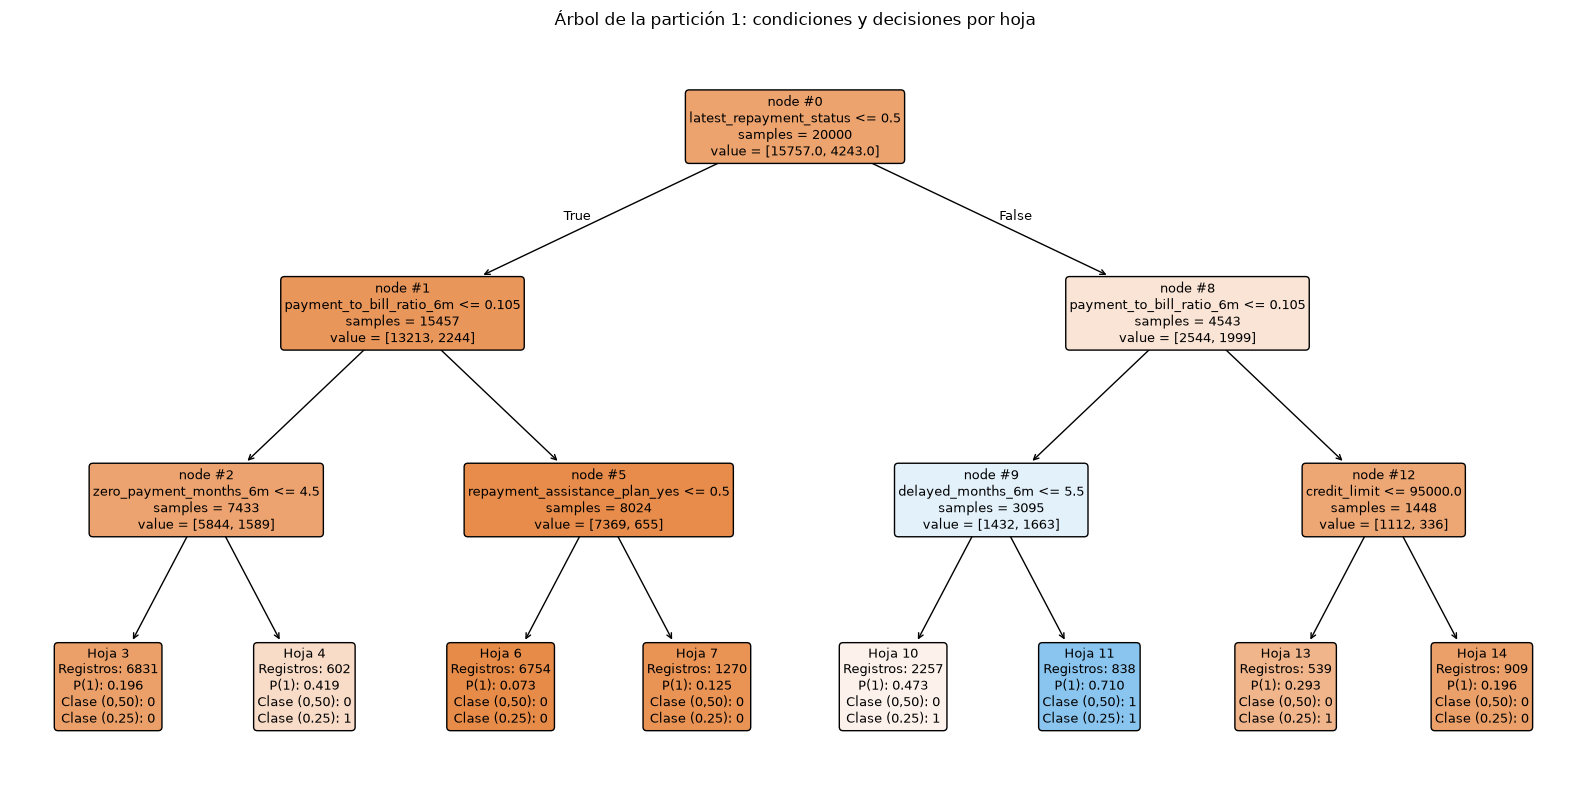

In [24]:
import re
from sklearn.tree import plot_tree

fig, ax = plt.subplots(figsize=(16, 8))
annotations = plot_tree(
    tree_reference_model, feature_names=list(tree_reference_names),
    node_ids=True, impurity=False, filled=True, rounded=True,
    precision=3, fontsize=9, ax=ax,
)
for annotation in annotations:
    match = re.search(r"node #(\d+)", annotation.get_text())
    if match:
        node = int(match.group(1))
        if node in tree_leaf_summary.index:
            row = tree_leaf_summary.loc[node]
            annotation.set_text(
                f"Hoja {node}\nRegistros: {int(row['Registros entrenamiento'])}"
                f"\nP(1): {row['Probabilidad aprendida']:.3f}"
                f"\nClase (0,50): {int(row['Clase con 0,5'])}"
                f"\nClase ({tree_reference_threshold:.2f}): {int(row['Clase con umbral interno'])}"
            )
ax.set_title("Árbol de la partición 1: condiciones y decisiones por hoja")
plt.tight_layout()
plt.show()

El dibujo muestra las ocho reglas completas con un máximo de tres condiciones por recorrido. Los límites de meses sin pago dependen de las ramas previas: no existe una única regla global de ese predictor independiente del estado reciente y del cociente de pagos. El árbol representa, por tanto, combinaciones de condiciones que deben leerse completas.

Las hojas 4, 10 y 14 conservan colores asociados a su composición mayoritaria de clase 0, aunque sus etiquetas indican clase 1 con umbral 0,25. No hay contradicción: el color procede de la visualización estándar y las etiquetas explicitan la regla de decisión utilizada. Las condiciones y frecuencias describen asociaciones aprendidas; no justifican intervenir sobre una variable para producir el cambio de riesgo mostrado.

### <a id="sec-4-5"></a> 4.5. Variables utilizadas e importancias por impureza

La importancia Gini suma y normaliza las reducciones de impureza de cada variable original, agrupando las columnas one-hot. La tabla muestra todas las variables; una importancia cero significa que este árbol no la usa, no que sea irrelevante en general.

,Importancia Gini
Variable original,
latest_repayment_status,0.5733
payment_to_bill_ratio_6m,0.2993
delayed_months_6m,0.0644
zero_payment_months_6m,0.0516
credit_limit,0.0060
repayment_assistance_plan,0.0054
bill_change_sep_to_apr,0.0000
education,0.0000
age,0.0000


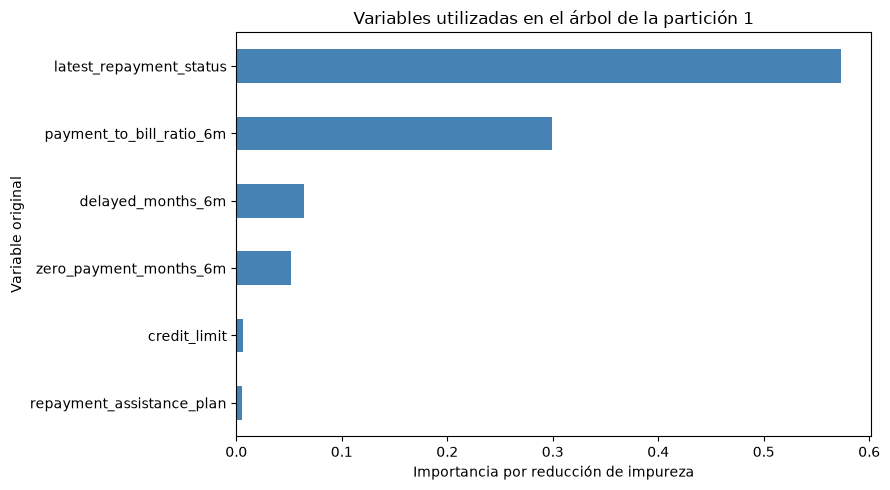

In [25]:
def tree_input_variables(pipeline):
    """Relaciona las columnas del preprocesador del árbol con las variables originales."""
    mapping = {variable: variable for variable in numeric_features}
    encoder = pipeline["preprocess"].named_transformers_["categorical"].named_steps["encoder"]
    encoded_names = iter(encoder.get_feature_names_out(categorical_features))
    for variable, categories in zip(categorical_features, encoder.categories_):
        for _ in categories:
            mapping[next(encoded_names)] = variable
    return mapping


tree_reference_mapping = tree_input_variables(tree_reference_pipeline)
tree_input_importance = pd.DataFrame({
    "Entrada": tree_reference_names,
    "Importancia Gini": tree_reference_model.feature_importances_,
})
tree_input_importance["Variable original"] = tree_input_importance["Entrada"].map(tree_reference_mapping)
tree_reference_importance = tree_input_importance.groupby("Variable original")["Importancia Gini"].sum().sort_values(ascending=False)
display(tree_reference_importance.to_frame().round(4))

used_importance = tree_reference_importance[tree_reference_importance > 0].sort_values()
ax = used_importance.plot.barh(figsize=(9, 5), color="steelblue")
ax.set(title="Variables utilizadas en el árbol de la partición 1",
       xlabel="Importancia por reducción de impureza", ylabel="Variable original")
plt.tight_layout()
plt.show()

En la partición 1, `latest_repayment_status` concentra 57,25 %, `payment_to_bill_ratio_6m` 29,71 % y `zero_payment_months_6m` 13,05 %. Las otras doce variables no se utilizan. La importancia no tiene signo ni interpretación causal.

### <a id="sec-4-6"></a> 4.6. Estabilidad entre divisiones

Se comparan los cinco árboles ya entrenados. La tabla resume cuántos usan cada variable y la media y desviación típica de su importancia Gini. La frecuencia de uso es descriptiva: los entrenamientos se solapan y la importancia puede repartirse entre variables correlacionadas.

,Modelos que utilizan la variable,Importancia media,Desviación típica
latest_repayment_status,5,0.5695,0.0031
payment_to_bill_ratio_6m,5,0.3233,0.0283
zero_payment_months_6m,5,0.0615,0.0575
delayed_months_6m,3,0.0386,0.0352
credit_limit,2,0.0023,0.0032
repayment_assistance_plan,2,0.0022,0.0030
age,1,0.0014,0.0032
utilization_sep,1,0.0012,0.0027
sex,0,0.0000,0.0000
education,0,0.0000,0.0000


Condiciones de la raíz:


,Entrada,Umbral,Registros entrenamiento
Partición,,,
1,latest_repayment_status,0.5,20000
2,latest_repayment_status,0.5,20000
3,latest_repayment_status,0.5,19999
4,latest_repayment_status,0.5,20000
5,latest_repayment_status,0.5,20001


Divisiones completas de los cinco modelos:


,Partición,Nodo,Nivel,Variable original,Entrada,Umbral,Registros entrenamiento
0,1,0,0,latest_repayment_status,latest_repayment_status,0.500,20000
1,1,1,1,payment_to_bill_ratio_6m,payment_to_bill_ratio_6m,0.105,15457
2,1,2,2,zero_payment_months_6m,zero_payment_months_6m,4.500,7433
3,1,5,2,repayment_assistance_plan,repayment_assistance_plan_yes,0.500,8024
4,1,8,1,payment_to_bill_ratio_6m,payment_to_bill_ratio_6m,0.105,4543
5,1,9,2,delayed_months_6m,delayed_months_6m,5.500,3095
6,1,12,2,credit_limit,credit_limit,95000.000,1448
7,2,0,0,latest_repayment_status,latest_repayment_status,0.500,20000
8,2,1,1,payment_to_bill_ratio_6m,payment_to_bill_ratio_6m,0.095,15425
9,2,2,2,payment_to_bill_ratio_6m,payment_to_bill_ratio_6m,0.025,7214


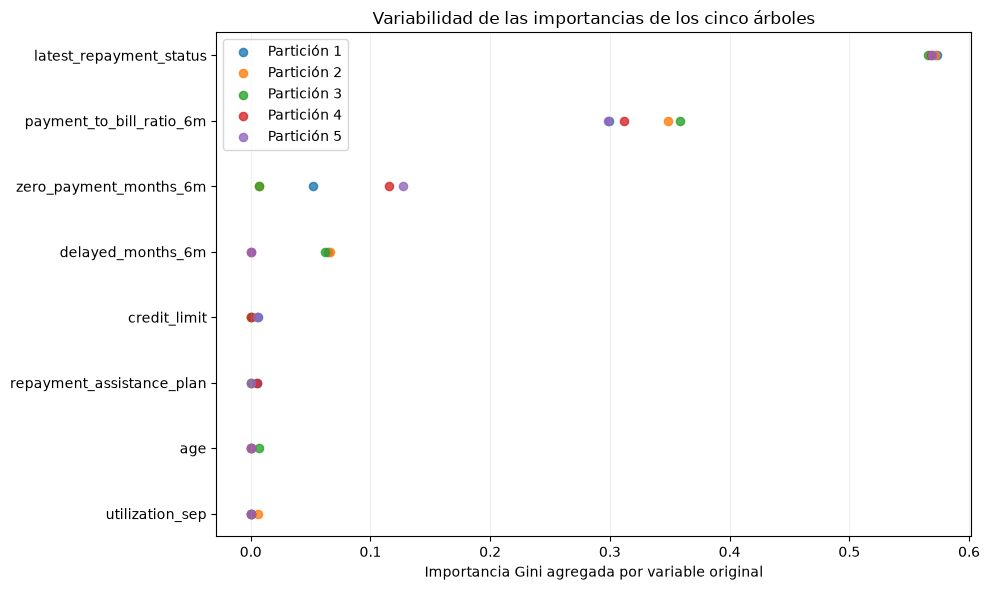

In [26]:
importance_rows = []
root_rows = []
split_rows = []
for fold, pipeline in enumerate(tree_models, start=1):
    model = pipeline["model"]
    names = pipeline["preprocess"].get_feature_names_out()
    mapping = tree_input_variables(pipeline)
    entry_importance = pd.Series(model.feature_importances_, index=names)
    original_importance = entry_importance.groupby([mapping[name] for name in names]).sum()
    importance_rows.append(original_importance.rename(fold))
    stack = [(0, 0)]
    while stack:
        node, level = stack.pop()
        feature_idx = int(model.tree_.feature[node])
        if feature_idx < 0:
            continue
        entry = names[feature_idx]
        row = {"Partición": fold, "Nodo": node, "Nivel": level,
               "Variable original": mapping[entry], "Entrada": entry,
               "Umbral": model.tree_.threshold[node],
               "Registros entrenamiento": model.tree_.n_node_samples[node]}
        split_rows.append(row)
        if node == 0:
            root_rows.append(row)
        stack.append((model.tree_.children_right[node], level + 1))
        stack.append((model.tree_.children_left[node], level + 1))

tree_importance_by_fold = pd.DataFrame(importance_rows).reindex(columns=feature_columns, fill_value=0)
tree_importance_by_fold.index.name = "Partición"
tree_variable_stability = pd.DataFrame({
    "Modelos que utilizan la variable": (tree_importance_by_fold > 0).sum(),
    "Importancia media": tree_importance_by_fold.mean(),
    "Desviación típica": tree_importance_by_fold.std(ddof=1),
}).sort_values(["Modelos que utilizan la variable", "Importancia media"], ascending=False)
tree_split_details = pd.DataFrame(split_rows)
tree_root_details = pd.DataFrame(root_rows).set_index("Partición")
display(tree_variable_stability.round(4))
print("Condiciones de la raíz:")
display(tree_root_details[["Entrada", "Umbral", "Registros entrenamiento"]])
print("Divisiones completas de los cinco modelos:")
display(tree_split_details.round(6))

plot_variables = tree_variable_stability.index[
    tree_variable_stability["Modelos que utilizan la variable"] > 0
][::-1]
positions = np.arange(1, len(plot_variables) + 1)
fig, ax = plt.subplots(figsize=(10, 6))
for fold in tree_importance_by_fold.index:
    ax.scatter(tree_importance_by_fold.loc[fold, plot_variables], positions,
               s=35, alpha=0.8, label=f"Partición {fold}")
ax.set_yticks(positions, labels=plot_variables)
ax.set(title="Variabilidad de las importancias de los cinco árboles",
       xlabel="Importancia Gini agregada por variable original")
ax.legend()
ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

Los cinco árboles comparten la raíz `latest_repayment_status <= 0,5` y la división `payment_to_bill_ratio_6m <= 0,105` en ambas ramas. En el tercer nivel aparecen meses sin pago (4 modelos), meses con retraso (3), edad (2), utilización y límite de crédito (1 cada uno); los umbrales también varían. El núcleo de dos niveles es estable; las reglas terminales requieren más cautela.

### <a id="sec-4-7"></a> 4.7. Síntesis de la interpretación y limitaciones

- CART de profundidad 3 y 8 reglas, con hojas de al menos 500 registros.
- ROC-AUC externa 0,7372; el umbral 0,25 mejora sensibilidad y exactitud equilibrada a costa de precisión y exactitud.
- El núcleo de variables estable son `latest_repayment_status` y `payment_to_bill_ratio_6m`; las divisiones del tercer nivel varían entre `zero_payment_months_6m`, `delayed_months_6m`, `age`, `utilization_sep` y `credit_limit`.
- Las probabilidades de hoja son frecuencias de entrenamiento, no garantías de calibración; las importancias Gini no son efectos causales.

[Volver al índice](#indice)

## <a id="sec-5"></a> 5. Regresión logística

### <a id="sec-5-1"></a> 5.1. Modelo y regularización

La regresión logística modela la probabilidad de dificultad de pago mediante una función logística aplicada a una combinación lineal de las entradas transformadas:

$$
\log\left(\frac{p}{1-p}\right)=\beta_0+\sum_j\beta_j z_j,
\qquad p=P(Y=1\mid X).
$$

donde $z_j$ son las numéricas estandarizadas y las columnas one-hot del apartado 2. El modelo es lineal en los **log-odds**; los coeficientes se interpretan como asociaciones condicionales, no causales.

Se comparan dos penalizaciones:

- **L2:** reduce la magnitud de los coeficientes y normalmente conserva todas las columnas. Puede ayudar a estabilizar el ajuste cuando hay predictores correlacionados.
- **L1:** puede anular coeficientes, proporcionando una representación más dispersa. Un coeficiente cero no demuestra que la variable sea irrelevante en general; los predictores correlacionados pueden sustituirse y la penalización también reduce los coeficientes que permanecen.

`C` es la inversa de la intensidad de regularización: cuanto menor sea, mayor es la penalización.  Se usa `liblinear`, máximo 2.000 iteraciones y los 15 predictores. No se usan pesos de clase.

Se conservan los 15 predictores originales. La selección implícita de columnas mediante L1 forma parte del entrenamiento dentro de cada partición; no se aplica una selección independiente sobre todo el conjunto.

### <a id="sec-5-2"></a> 5.2. Configuraciones y criterios de selección
Se prueban los siguientes valores de `C` para L1 y L2:
| Penalización | Valores de `C` |
| --- | --- |
| L1 | 0,01, 0,1, 1, 10 |
| L2 | 0,01, 0,1, 1, 10 |

La configuración se elige por ROC-AUC media interna. En caso de empate se prefiere `C` menor y después L1. El umbral se elige con probabilidades OOF internas y exactitud equilibrada media. Los resultados externos se guardan con 0,5 y con el umbral interno; no se consultan las etiquetas externas para seleccionar.

In [27]:
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import GridSearchCV, ParameterGrid, cross_val_predict
from sklearn.metrics import accuracy_score, balanced_accuracy_score, roc_auc_score

LR_PARAM_GRID = {
    "model__penalty": ["l1", "l2"],
    "model__C": [0.01, 0.1, 1.0, 10.0],
}
lr_base_pipeline = make_logistic_pipeline()
if "model__C" not in lr_base_pipeline.get_params(deep=True):
    raise ValueError("Vuelve a ejecutar la definición actualizada de los pipelines en 5.3.")


Las métricas y la selección del umbral reutilizan las funciones comunes del [apartado 3.4.1](#sec-3-4-1). Cada candidato se evalúa por separado en las cinco validaciones internas y después se promedian sus exactitudes equilibradas.

### <a id="sec-5-3"></a> 5.3. Evaluación anidada de cinco particiones
Para cada partición externa se comparan las ocho configuraciones en cinco particiones internas. Con la configuración elegida se generan probabilidades OOF internas, se selecciona el umbral y se reentrena con todo el entrenamiento externo para evaluar una vez su validación.

La celda realiza 230 ajustes y guarda modelos, búsquedas, umbrales y predicciones OOF. No se entrena aún el modelo final.

In [28]:
lr_models = []
lr_search_results = []
lr_threshold_tables = []
lr_settings_rows = []
lr_default_rows = []
lr_tuned_rows = []
lr_oof_probability = np.full(len(y), np.nan)
lr_oof_threshold = np.full(len(y), np.nan)
lr_oof_fold = np.zeros(len(y), dtype=int)

with warnings.catch_warnings():
    warnings.simplefilter("error", ConvergenceWarning)
    warnings.filterwarnings("ignore", category=FutureWarning, module="sklearn.linear_model")
    warnings.filterwarnings("ignore", message="Inconsistent values: penalty=.*")
    for fold, (outer_train_idx, outer_valid_idx) in enumerate(cv_splits, start=1):
        inner_X = X_raw.iloc[outer_train_idx]
        inner_y = y.iloc[outer_train_idx]
        inner_splits = make_inner_splits(outer_train_idx)

        search = GridSearchCV(
            clone(lr_base_pipeline), LR_PARAM_GRID, cv=inner_splits,
            scoring=SCORING, refit=False, n_jobs=N_JOBS, error_score="raise",
        )
        search.fit(inner_X, inner_y)
        search_table = pd.DataFrame(search.cv_results_).sort_values(
            ["mean_test_roc_auc", "param_model__C", "param_model__penalty"],
            ascending=[False, True, True],
        )
        best_row = search_table.iloc[0]
        best_params = best_row["params"]
        selected_pipeline = clone(lr_base_pipeline).set_params(**best_params)

        inner_probability = cross_val_predict(
            selected_pipeline, inner_X, inner_y, cv=inner_splits,
            method="predict_proba", n_jobs=N_JOBS,
        )[:, 1]
        threshold, threshold_table = choose_threshold(inner_y, inner_probability, inner_splits)

        selected_pipeline.fit(inner_X, inner_y)
        if not np.array_equal(selected_pipeline.classes_, [0, 1]):
            raise ValueError("El orden de clases esperado es [0, 1].")
        outer_probability = selected_pipeline.predict_proba(X_raw.iloc[outer_valid_idx])[:, 1]
        outer_y = y.iloc[outer_valid_idx]
        lr_default_rows.append(metric_scores(outer_y, outer_probability, DEFAULT_THRESHOLD))
        lr_tuned_rows.append(metric_scores(outer_y, outer_probability, threshold))
        lr_oof_probability[outer_valid_idx] = outer_probability
        lr_oof_threshold[outer_valid_idx] = threshold
        lr_oof_fold[outer_valid_idx] = fold

        coefficients = selected_pipeline["model"].coef_[0]
        lr_settings_rows.append({
            "Partición": fold,
            "Penalización": best_params["model__penalty"],
            "C": best_params["model__C"],
            "ROC-AUC interna": best_row["mean_test_roc_auc"],
            "Umbral": threshold,
            "Columnas transformadas": len(coefficients),
            "Coeficientes no nulos": int(np.count_nonzero(coefficients)),
        })
        lr_models.append(selected_pipeline)
        lr_search_results.append(search_table)
        lr_threshold_tables.append(threshold_table)
        print(f"Partición {fold}/{N_SPLITS} completada: "
              f"{best_params['model__penalty'].upper()}, C={best_params['model__C']}, "
              f"umbral={threshold:.2f}", flush=True)

if not np.isfinite(lr_oof_probability).all() or not np.all(lr_oof_fold > 0):
    raise ValueError("Faltan predicciones externas OOF.")
lr_fold_settings = pd.DataFrame(lr_settings_rows).set_index("Partición")
lr_scores_default = pd.DataFrame(lr_default_rows, index=lr_fold_settings.index)
lr_scores_tuned = pd.DataFrame(lr_tuned_rows, index=lr_fold_settings.index)
lr_oof_results = pd.DataFrame({
    ID_COLUMN: train_raw[ID_COLUMN],
    "true_class": y,
    "fold": lr_oof_fold,
    "probability_class_1": lr_oof_probability,
    "threshold": lr_oof_threshold,
    "prediction_default": (lr_oof_probability >= DEFAULT_THRESHOLD).astype(int),
    "prediction_tuned": (lr_oof_probability >= lr_oof_threshold).astype(int),
}, index=X_raw.index)
display(lr_fold_settings.round(4))

Partición 1/5 completada: L1, C=1.0, umbral=0.25
Partición 2/5 completada: L1, C=1.0, umbral=0.25
Partición 3/5 completada: L1, C=1.0, umbral=0.25
Partición 4/5 completada: L2, C=0.1, umbral=0.25
Partición 5/5 completada: L1, C=1.0, umbral=0.20


,Penalización,C,ROC-AUC interna,Umbral,Columnas transformadas,Coeficientes no nulos
Partición,,,,,,
1,l1,1.0,0.7510,0.25,19,19
2,l1,1.0,0.7503,0.25,19,19
3,l1,1.0,0.7503,0.25,19,18
4,l2,0.1,0.7524,0.25,19,19
5,l1,1.0,0.7549,0.20,19,18


 Las cinco búsquedas seleccionan L1, con `C=0,1` en las particiones 1 y 4, `C=1` en las 3 y 5, y `C=10` en la 2. Los modelos conservan entre 15 y 19 coeficientes no nulos de 19 columnas. Los umbrales internos son 0,25 en tres particiones y 0,20 en dos.

La evaluación externa compara las métricas con 0,5 y con el umbral interno. ROC-AUC no cambia; las demás métricas pueden mejorar o empeorar. No se elige un umbral nuevo con las etiquetas externas.

### <a id="sec-5-4"></a> 5.4. Resultados externos y efecto del umbral

Se muestran las seis métricas de cada validación externa con umbral 0,5 y con el umbral seleccionado exclusivamente dentro de su entrenamiento. Los resúmenes utilizan la media simple y la desviación típica muestral de las cinco particiones, como la referencia mayoritaria.

ROC-AUC debe coincidir entre ambas versiones, pues cambiar el umbral no cambia las probabilidades. Las restantes métricas pueden mejorar o empeorar: elegir un umbral por exactitud equilibrada interna no garantiza mejorar todas las métricas externas ni la exactitud del test. Las diferencias se interpretan a continuación, sin escoger un nuevo umbral a partir de las validaciones externas.

In [29]:
lr_summary_default = pd.DataFrame({
    "Media": lr_scores_default.mean(),
    "Desviación típica": lr_scores_default.std(ddof=1),
})
lr_summary_tuned = pd.DataFrame({
    "Media": lr_scores_tuned.mean(),
    "Desviación típica": lr_scores_tuned.std(ddof=1),
})
lr_comparison = pd.concat({
    "Referencia mayoritaria": baseline_summary,
    "Logística: umbral 0,5": lr_summary_default,
    "Logística: umbral ajustado": lr_summary_tuned,
}, axis=1)
display(lr_comparison.round(4))

Referencia mayoritaria                    \
                                   Media Desviación típica   
roc_auc                           0.5000            0.0000   
accuracy                          0.7879            0.0001   
balanced_accuracy                 0.5000            0.0000   
recall                            0.0000            0.0000   
precision                         0.0000            0.0000   
f1                                0.0000            0.0000   

                  Logística: umbral 0,5                    \
                                  Media Desviación típica   
roc_auc                          0.7518            0.0068   
accuracy                         0.8109            0.0013   
balanced_accuracy                0.6046            0.0030   
recall                           0.2463            0.0077   
precision                        0.6414            0.0117   
f1                               0.3558            0.0075   

                  Logística: umbral ajustado                    
                                       Media Desviación típica  
roc_auc                               0.7518            0.0068  
accuracy                              0.7405            0.0264  
balanced_accuracy                     0.6809            0.0033  
recall                                0.5774            0.0446  
precision                             0.4223            0.0277  
f1                                    0.4860            0.0072

ROC-AUC externa 0,7515 ± 0,0075. Con umbral 0,5 la exactitud es 81,06 %, la precisión 64,03 %, pero la sensibilidad solo 24,41 % (exactitud equilibrada 60,36 %, F1 0,3532). Con el umbral interno, la exactitud equilibrada sube a 68,06 %, la sensibilidad a 59,55 % y F1 a 0,4833; la precisión baja a 41,09 % y la exactitud a 72,97 %. El ajuste mejora la detección a costa de más falsos positivos y de exactitud total.

La evaluación muestra que L1 es seleccionada en los cinco entrenamientos, pero la intensidad de regularización y el número de coeficientes activos varían. El ajuste interno del umbral mejora la detección de dificultad y la exactitud equilibrada, a costa de precisión y exactitud total. Estos resultados justifican examinar conjuntamente rendimiento e interpretabilidad antes de elegir el modelo y su regla de decisión.

No se selecciona ahora una configuración final por ser la que obtuvo mejor resultado en una validación externa. Las siguientes subsecciones utilizan los modelos guardados para estudiar sus coeficientes, signos, odds ratios y variabilidad. El entrenamiento final y la predicción del test siguen reservados a los apartados 10 y 11.

### <a id="sec-5-5"></a> 5.5. Coeficientes, referencias y odds ratios

Se interpreta primero el modelo del **entrenamiento externo de la partición 1**, como ejemplo fijado por su posición y no por su rendimiento. Utiliza L1 con `C=0,1` en la ejecución actual. No es el modelo final ni representa necesariamente las configuraciones elegidas en las demás particiones.

Un coeficiente positivo aumenta los log-odds predichos de dificultad y uno negativo los reduce, manteniendo las demás entradas constantes. Su exponencial, $\exp(\beta_j)$, es el **odds ratio (OR)** del contraste descrito:

- Para una numérica estandarizada, el contraste es un incremento de **una desviación típica del entrenamiento**, no de una unidad original como un año o un NTD. Para un cambio de $\Delta x$ unidades originales, el OR sería $\exp(\beta_j\Delta x/s_j)$, donde $s_j$ es la escala aprendida.
- Para una columna one-hot, el contraste es su categoría frente a la **categoría de referencia** de la variable original.
- Un OR mayor que 1 aumenta las odds, uno menor que 1 las reduce y un OR igual a 1 corresponde a coeficiente cero. **Multiplicar las odds no equivale a multiplicar la probabilidad**: esta depende también del resto de las entradas.

El intercepto describe el caso con numéricas en sus medias de entrenamiento y categóricas en sus referencias. Este caso puede no representar un registro real y su probabilidad no es necesariamente la tasa positiva media del conjunto.

Los coeficientes son asociaciones condicionales del modelo regularizado, no efectos causales ni estimaciones sin sesgo. Las relaciones aprendidas para variables derivadas o correlacionadas pueden resultar difíciles de separar; variar una entrada manteniendo todas las demás constantes puede incluso describir una combinación poco plausible.

In [30]:
from scipy.special import expit

LR_REFERENCE_FOLD = 1
lr_reference_pipeline = lr_models[LR_REFERENCE_FOLD - 1]
lr_reference_preprocessor = lr_reference_pipeline["preprocess"]
lr_reference_model = lr_reference_pipeline["model"]
lr_reference_train_idx, lr_reference_valid_idx = cv_splits[LR_REFERENCE_FOLD - 1]
lr_reference_transformed = lr_reference_preprocessor.transform(X_raw.iloc[lr_reference_train_idx])
lr_reference_names = lr_reference_preprocessor.get_feature_names_out()

scaler_reference = lr_reference_preprocessor.named_transformers_["numeric"].named_steps["scaler"]
encoder_reference = lr_reference_preprocessor.named_transformers_["categorical"].named_steps["encoder"]
metadata_rows = [
    {"Entrada": name, "Variable original": name,
     "Contraste": "Incremento de 1 desviación típica",
     "Escala en unidades originales": scale}
    for name, scale in zip(numeric_features, scaler_reference.scale_)
]
reference_rows = []
encoded_names = iter(encoder_reference.get_feature_names_out(categorical_features))
for variable, categories, drop_idx in zip(
    categorical_features, encoder_reference.categories_, encoder_reference.drop_idx_
):
    reference = categories[drop_idx]
    reference_rows.append({"Variable": variable, "Referencia": reference})
    for category_idx, category in enumerate(categories):
        if category_idx != drop_idx:
            metadata_rows.append({
                "Entrada": next(encoded_names), "Variable original": variable,
                "Contraste": f"{category} frente a {reference}",
                "Escala en unidades originales": np.nan,
            })

lr_coefficient_table = pd.DataFrame(metadata_rows).set_index("Entrada").loc[lr_reference_names]
lr_coefficient_table["Coeficiente"] = lr_reference_model.coef_[0]
lr_coefficient_table["OR del contraste"] = np.exp(lr_reference_model.coef_[0])
lr_coefficient_table["Magnitud"] = lr_coefficient_table["Coeficiente"].abs()
lr_reference_categories = pd.DataFrame(reference_rows)
display(lr_reference_categories)
display(lr_coefficient_table.sort_values("Magnitud", ascending=False).drop(columns="Magnitud").round(4))

lr_reference_intercept = float(lr_reference_model.intercept_[0])
print(f"Intercepto: {lr_reference_intercept:.4f}")
print(f"Probabilidad del caso de referencia: {expit(lr_reference_intercept):.2%}")

,Variable,Referencia
0,sex,female
1,education,graduate_school
2,marital_status,married
3,repayment_assistance_plan,no


,Variable original,Contraste,Escala en unidades originales,Coeficiente,OR del contraste
Entrada,,,,,
zero_payment_months_6m,zero_payment_months_6m,Incremento de 1 desviación típica,1.7198,0.4966,1.6431
repayment_assistance_plan_yes,repayment_assistance_plan,yes frente a no,NaN,0.4392,1.5515
latest_repayment_status,latest_repayment_status,Incremento de 1 desviación típica,1.1191,0.4291,1.5359
utilization_sep,utilization_sep,Incremento de 1 desviación típica,0.4031,0.3929,1.4812
delayed_months_6m,delayed_months_6m,Incremento de 1 desviación típica,1.5461,0.3274,1.3874
education_other,education,other frente a graduate_school,NaN,-0.2725,0.7615
total_payment_6m,total_payment_6m,Incremento de 1 desviación típica,58501.5120,-0.1623,0.8502
maximum_repayment_delay_6m,maximum_repayment_delay_6m,Incremento de 1 desviación típica,1.0680,-0.1426,0.8671
education_high_school,education,high_school frente a graduate_school,NaN,0.1084,1.1144


Intercepto: -1.6464
Probabilidad del caso de referencia: 16.16%


Las referencias aprendidas son `female`, `graduate_school`, `married` y ausencia de plan (`no`). En el modelo de la partición 1, los principales contrastes positivos por magnitud del coeficiente son:

| Entrada | Coeficiente | OR | Lectura del contraste, manteniendo las demás entradas constantes |
| --- | --- | --- | --- |
| `zero_payment_months_6m` | 0,5156 | 1,6746 | Un incremento de una desviación típica, equivalente a 1,7219 meses, multiplica las odds predichas por aproximadamente 1,67. Es un contraste de escala; el recuento real solo toma valores enteros. |
| `repayment_assistance_plan_yes` | 0,4368 | 1,5478 | La categoría `yes`, frente a `no`, multiplica las odds predichas por aproximadamente 1,55. |
| `latest_repayment_status` | 0,4288 | 1,5354 | Un incremento de una desviación típica del código multiplica las odds por aproximadamente 1,54, bajo el tratamiento numérico utilizado. |
| `utilization_sep` | 0,3841 | 1,4683 | Un aumento de 0,4050 en la utilización, una desviación típica, multiplica las odds por aproximadamente 1,47. |
| `delayed_months_6m` | 0,2958 | 1,3441 | Un incremento de una desviación típica, equivalente a 1,5468 meses, multiplica las odds por aproximadamente 1,34. |

`total_payment_6m` es negativo (−0,1682; OR 0,85) y `maximum_repayment_delay_6m` también (−0,1216; OR 0,89), aunque `delayed_months_6m` sea positivo. El signo del retraso máximo es condicional a los demás resúmenes, incluido uno casi redundante; no indica que retrasarse proteja. `sex_male` es pequeño y negativo (−0,0430; OR 0,96).

L1 anula `education_other`, `education_unknown`, `marital_status_other_or_unknown` y `marital_status_single` en este modelo; sus OR son 1. El intercepto −1,6022 corresponde a una probabilidad de referencia de 16,77 %, no a la prevalencia del 21,21 %. El plan de asistencia conserva asociación positiva, pero su asignación selectiva impide una lectura causal.

### <a id="sec-5-6"></a> 5.6. Visualización global de los coeficientes

La primera gráfica muestra los coeficientes con su signo en log-odds; la segunda, `coeficiente × desviación típica observada`, que incorpora la frecuencia de las categorías. Una categoría poco frecuente puede tener un coeficiente grande y poca variación observada. Ninguna de las dos es una medida causal ni una importancia predictiva independiente.

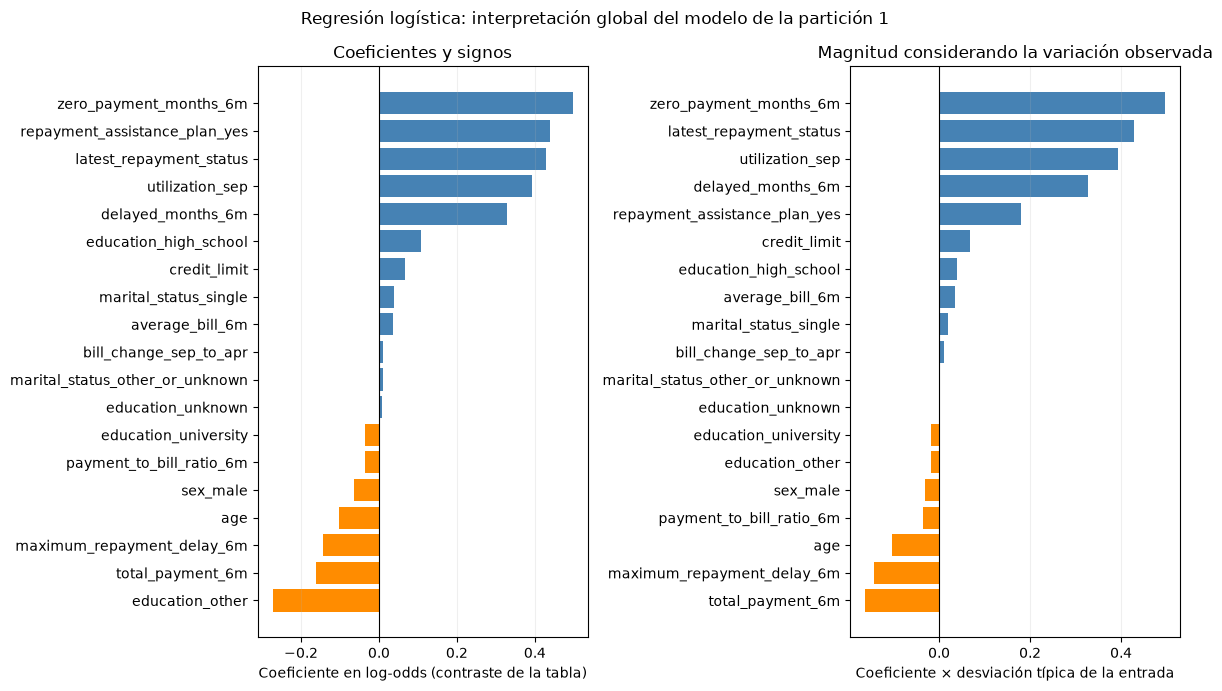

In [60]:
lr_signed_coefficients = pd.Series(
    lr_reference_model.coef_[0], index=lr_reference_names, name="Coeficiente"
)
lr_scaled_contributions = lr_signed_coefficients * lr_reference_transformed.std(ddof=0)

fig, axes = plt.subplots(1, 2, figsize=(12, 7))
for ax, values, title, xlabel in (
    (axes[0], lr_signed_coefficients, "Coeficientes y signos",
     "Coeficiente en log-odds (contraste de la tabla)"),
    (axes[1], lr_scaled_contributions, "Magnitud considerando la variación observada",
     "Coeficiente × desviación típica de la entrada"),
):
    ordered = values.sort_values()
    colors = ["steelblue" if value > 0 else "darkorange" if value < 0 else "gray" for value in ordered]
    ax.barh(ordered.index, ordered.values, color=colors)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set(title=title, xlabel=xlabel)
    ax.grid(axis="x", alpha=0.2)
fig.suptitle("Regresión logística: interpretación global del modelo de la partición 1")
plt.tight_layout()
plt.show()

La gráfica de coeficientes destaca los meses sin pago, el plan de asistencia, el estado reciente de pago, la utilización y los meses con retraso. Los pagos totales presentan la mayor magnitud negativa. Las cuatro entradas anuladas por L1 quedan en el eje de cero; sus categorías se conservaron en la codificación, pero este ajuste no les asignó un coeficiente distinto de cero.

Al incorporar la variación observada, `repayment_assistance_plan_yes` pasa de la segunda a la quinta posición entre las contribuciones positivas mostradas. Su coeficiente describe un cambio completo de categoría, mientras que su desviación típica binaria es menor que uno. Por eso su barra se reduce respecto a las numéricas ya estandarizadas. El cambio de orden ilustra que **magnitud del coeficiente y magnitud de la variación de su contribución no son lo mismo**. No se interpreta esta segunda gráfica como una clasificación definitiva de importancia.

### <a id="sec-5-7"></a> 5.7. Estabilidad entre las cinco particiones

Se alinean los coeficientes por nombre de entrada y se comprueba que las referencias categóricas coincidan. La tabla resume media, desviación típica, número de modelos con la entrada y cuántos tienen coeficiente positivo, negativo o nulo. La variabilidad combina cambios de datos, regularización y escala; no es un intervalo de confianza.

Se representa también el par `maximum_repayment_delay_6m` y `delayed_months_6m`, cuya correlación de Spearman fue 0,982. El objetivo es observar cómo se reparte su contribución entre los modelos y si cambia su signo, sin deducir que uno de ellos sea irrelevante o que la relación sea causal.

,Media,Desviación típica,Modelos con entrada,Coeficiente positivo,Coeficiente negativo,Coeficiente nulo
zero_payment_months_6m,0.5067,0.0126,5,5,0,0
repayment_assistance_plan_yes,0.4573,0.0159,5,5,0,0
latest_repayment_status,0.4171,0.0154,5,5,0,0
utilization_sep,0.3949,0.0090,5,5,0,0
delayed_months_6m,0.3152,0.0165,5,5,0,0
total_payment_6m,-0.1745,0.0289,5,0,5,0
education_other,-0.1660,0.1060,5,0,4,1
maximum_repayment_delay_6m,-0.1330,0.0076,5,0,5,0
marital_status_other_or_unknown,-0.1192,0.1001,5,1,4,0
age,-0.1075,0.0115,5,0,5,0


/tmp/ipykernel_425044/1880156402.py:35: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(


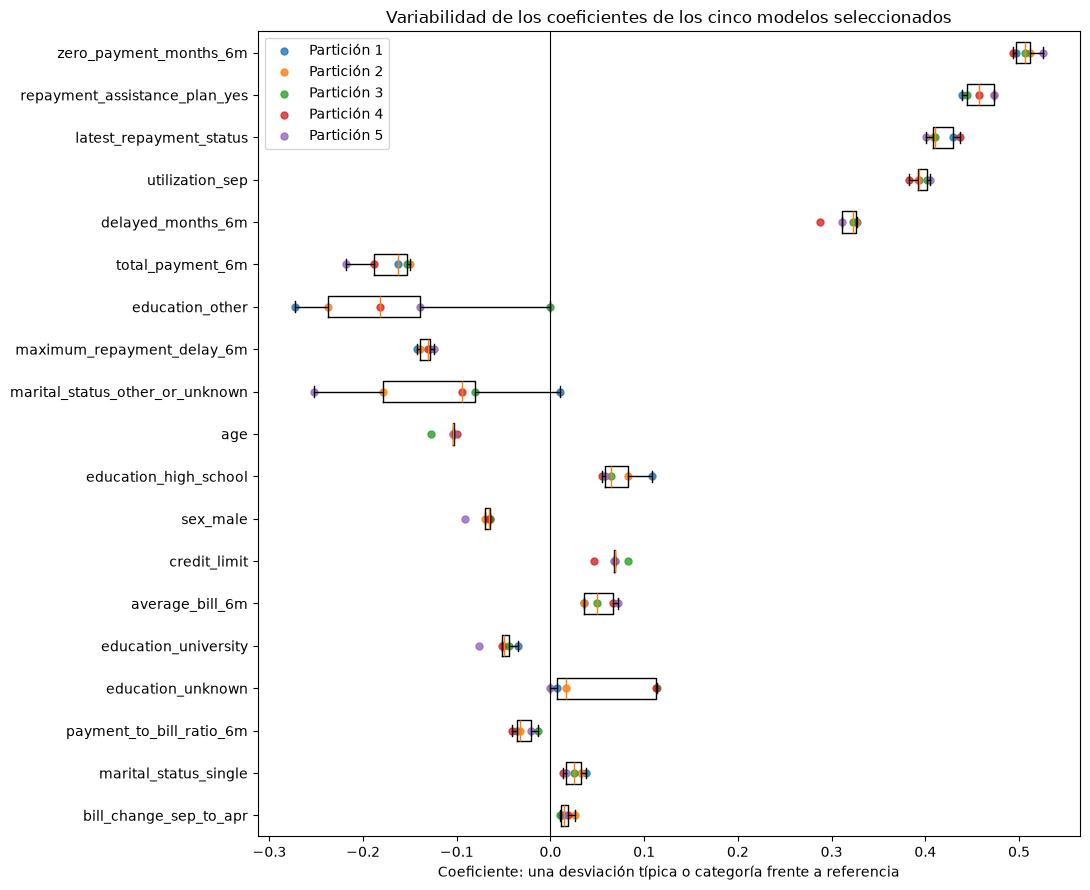

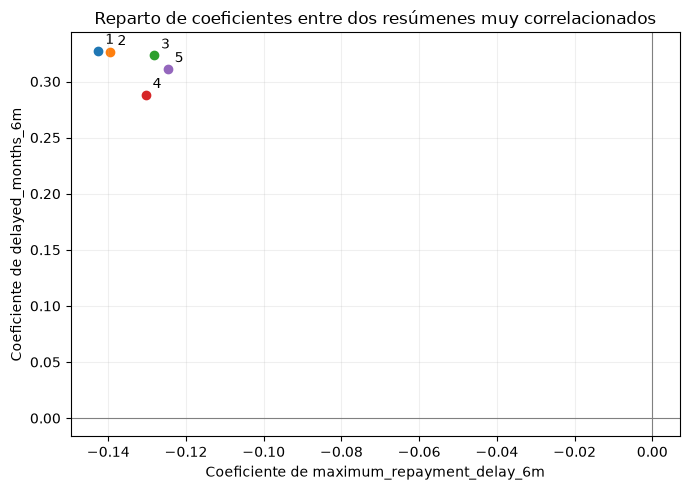

In [32]:
lr_coefficient_rows = []
lr_reference_rows = []
for fold, pipeline in enumerate(lr_models, start=1):
    names = pipeline["preprocess"].get_feature_names_out()
    lr_coefficient_rows.append(pd.Series(pipeline["model"].coef_[0], index=names, name=fold))
    encoder = pipeline["preprocess"].named_transformers_["categorical"].named_steps["encoder"]
    lr_reference_rows.append({
        variable: categories[drop_idx]
        for variable, categories, drop_idx in zip(
            categorical_features, encoder.categories_, encoder.drop_idx_
        )
    })

lr_references_by_fold = pd.DataFrame(lr_reference_rows, index=range(1, N_SPLITS + 1))
if (lr_references_by_fold.nunique(dropna=False) > 1).any():
    raise ValueError("Las referencias cambian entre modelos; hay que alinear sus contrastes antes de compararlos.")
lr_coefficients_by_fold = pd.DataFrame(lr_coefficient_rows)
lr_coefficients_by_fold.index.name = "Partición"
lr_coefficient_stability = pd.DataFrame({
    "Media": lr_coefficients_by_fold.mean(),
    "Desviación típica": lr_coefficients_by_fold.std(ddof=1),
    "Modelos con entrada": lr_coefficients_by_fold.notna().sum(),
    "Coeficiente positivo": (lr_coefficients_by_fold > 0).sum(),
    "Coeficiente negativo": (lr_coefficients_by_fold < 0).sum(),
    "Coeficiente nulo": (lr_coefficients_by_fold == 0).sum(),
})
lr_coefficient_stability = lr_coefficient_stability.loc[
    lr_coefficient_stability["Media"].abs().sort_values(ascending=False).index
]
display(lr_coefficient_stability.round(4))

plot_columns = lr_coefficient_stability.index[::-1]
fig, ax = plt.subplots(figsize=(11, 9))
positions = np.arange(1, len(plot_columns) + 1)
ax.boxplot(
    [lr_coefficients_by_fold[column].dropna().to_numpy() for column in plot_columns],
    vert=False, positions=positions, showfliers=False,
)
for fold in lr_coefficients_by_fold.index:
    ax.scatter(lr_coefficients_by_fold.loc[fold, plot_columns], positions,
               s=25, alpha=0.8, label=f"Partición {fold}")
ax.set_yticks(positions, labels=plot_columns)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title="Variabilidad de los coeficientes de los cinco modelos seleccionados",
       xlabel="Coeficiente: una desviación típica o categoría frente a referencia")
ax.legend()
plt.tight_layout()
plt.show()

first_variable = "maximum_repayment_delay_6m"
second_variable = "delayed_months_6m"
fig, ax = plt.subplots(figsize=(7, 5))
for fold in lr_coefficients_by_fold.index:
    x_value = lr_coefficients_by_fold.loc[fold, first_variable]
    y_value = lr_coefficients_by_fold.loc[fold, second_variable]
    ax.scatter(x_value, y_value)
    ax.annotate(str(fold), (x_value, y_value), xytext=(5, 5), textcoords="offset points")
ax.axvline(0, color="gray", linewidth=0.8)
ax.axhline(0, color="gray", linewidth=0.8)
ax.set(xlabel=f"Coeficiente de {first_variable}", ylabel=f"Coeficiente de {second_variable}",
       title="Reparto de coeficientes entre dos resúmenes muy correlacionados")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

 Las 19 entradas aparecen en los cinco modelos y no hay inversiones de signo. Los coeficientes positivos principales son estables: `zero_payment_months_6m` (0,5051 ± 0,0095), `latest_repayment_status` (0,4151 ± 0,0133), `utilization_sep` (0,3926 ± 0,0120) y el plan de asistencia (0,4520 ± 0,0262). `total_payment_6m` mantiene signo negativo (−0,1692 ± 0,0089).

Las categorías poco frecuentes son más inestables: `education_unknown` se anula en tres modelos y es positiva en dos; `education_other` y `marital_status_other_or_unknown` son nulas en dos y negativas en tres. El retraso máximo es negativo y los meses con retraso positivos en las cinco particiones; el reparto ilustra por qué deben interpretarse juntos y por qué no son efectos independientes.

En el gráfico del par correlacionado, **el retraso máximo es negativo y el número de meses con retraso es positivo en las cinco particiones**. El modelo 2 presenta el coeficiente más negativo del primero y el más positivo del segundo. Este reparto muestra por qué conviene interpretar conjuntamente ambos resúmenes: sus coeficientes no equivalen a efectos independientes sobre el riesgo. Con cinco ajustes y configuraciones distintas, el gráfico no identifica el mecanismo que produce ese reparto ni demuestra una relación general entre sus coeficientes.

### <a id="sec-5-8"></a> 5.8. Visualización con InterpretML

Se reproduce el modelo de la partición 1 con los mismos parámetros y entradas transformadas para reutilizarlo en las explicaciones locales del apartado 8. No se vuelve a ajustar el preprocesamiento ni se realiza otra búsqueda.

In [62]:
from interpret.glassbox import LogisticRegression as ExplainableLogisticRegression

lr_explainer = ExplainableLogisticRegression(
    feature_names=list(lr_reference_names),
    feature_types=["continuous"] * len(lr_reference_names),
    **lr_reference_model.get_params(),
)
with warnings.catch_warnings():
    warnings.simplefilter("error", ConvergenceWarning)
    lr_explainer.fit(lr_reference_transformed, y.iloc[lr_reference_train_idx])

lr_explanation_input = lr_reference_preprocessor.transform(X_raw.iloc[lr_reference_valid_idx])
if not np.allclose(lr_explainer._model().coef_, lr_reference_model.coef_, rtol=1e-6, atol=1e-8):
    raise ValueError("Los coeficientes de InterpretML no coinciden con los del modelo explicado.")
if not np.allclose(
    lr_explainer.predict_proba(lr_explanation_input),
    lr_reference_pipeline.predict_proba(X_raw.iloc[lr_reference_valid_idx]),
    rtol=1e-6, atol=1e-8,
):
    raise ValueError("Las probabilidades de InterpretML no coinciden con las del modelo explicado.")
print("Coeficientes y probabilidades coinciden con el modelo de la partición 1.")
lr_global_explanation = lr_explainer.explain_global(name="Regresión logística: partición 1")
show(lr_global_explanation)

/home/damian/miniforge3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/damian/miniforge3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


Coeficientes y probabilidades coinciden con el modelo de la partición 1.


La comprobación confirma que los coeficientes y las probabilidades de la reproducción en InterpretML coinciden con los del modelo de la partición 1. Por tanto, la vista global explica ese mismo ajuste, no un modelo alternativo con otras predicciones. La visualización aporta una forma de explorar sus contribuciones; no añade una evaluación independiente ni transforma sus asociaciones en efectos causales.

### <a id="sec-5-9"></a> 5.9. Síntesis de la interpretación y limitaciones

La regresión logística ofrece una explicación global compacta mediante coeficientes y odds ratios. En los cinco entrenamientos mantienen signo positivo `zero_payment_months_6m`, `latest_repayment_status`, `utilization_sep`, `delayed_months_6m` y el plan de asistencia; `total_payment_6m` mantiene signo negativo. Las magnitudes varían y algunas categorías poco frecuentes alternan entre coeficientes nulos y no nulos.

Los límites principales son los habituales del modelo: el coeficiente negativo de `maximum_repayment_delay_6m` es condicional a los resúmenes de retraso correlacionados; la asociación positiva del plan no implica causalidad; los códigos no positivos de `latest_repayment_status` están incompletamente documentados; y el tratamiento numérico impone linealidad en los log-odds. La regularización no produce una representación uniformemente dispersa: la partición 1 conserva 19 coeficientes y las demás, 18–19. La variabilidad entre cinco ajustes solapados es descriptiva, no un intervalo de confianza. Las explicaciones locales se desarrollan en el apartado 8 y el modelo final en el 10.

[Volver al índice](#indice)

## <a id="sec-6"></a> 6. Explainable Boosting Machine

### <a id="sec-6-1"></a> 6.1. Modelo aditivo y explicabilidad

Explainable Boosting Machine (EBM) es un modelo aditivo generalizado que aprende una función para cada variable mediante boosting de árboles pequeños y combina varias réplicas del entrenamiento (*bags*). Para clasificación binaria, la predicción tiene la forma:

$$
\log\left(\frac{p}{1-p}\right)=\beta_0+\sum_{j=1}^{15}f_j(x_j),
\qquad p=P(Y=1\mid X).
$$

Se fija **`interactions=0`**, de modo que cada término corresponde a una sola variable original. El modelo puede aprender umbrales, mesetas y relaciones no monótonas, pero no añade funciones conjuntas entre variables. Los resúmenes y cocientes que ya existen en los datos mantienen sus definiciones.

La explicación global consiste en inspeccionar las funciones $f_j$: una contribución positiva aumenta el logit respecto al intercepto y una negativa lo reduce. La probabilidad resulta de aplicar la función logística a la suma completa; una función aislada no es una curva independiente de probabilidad. La correlación entre predictores puede influir en cómo se reparte la contribución, y las funciones no identifican efectos causales.

Se utilizan los 15 predictores originales, sin escalado ni one-hot, mediante el pipeline del apartado 2. Las categóricas se declaran nominales y las numéricas continuas; estas últimas se discretizan internamente, incluidos los recuentos y el código de estado de pago. No se inventan significados para sus códigos no positivos, ni se fuerzan formas monótonas a partir de intuiciones no verificadas.

### <a id="sec-6-2"></a> 6.2. Configuraciones y control del coste

La búsqueda compara cuatro configuraciones:

| Parámetro | Valores | Justificación |
| --- | --- | --- |
| `max_bins` | 16 y 32 | Comparar funciones con una discretización más gruesa o más detallada. Es un máximo de intervalos/categorías, no el número garantizado de intervalos utilizados. |
| `min_samples_leaf` | 10 y 50 | Comparar mínimos de registros por hoja de los árboles usados en boosting. No es un mínimo garantizado de observaciones en cada intervalo final. |

Se mantienen `max_leaves=2`, `learning_rate=0.05`, un máximo de 2.000 rondas y cuatro réplicas externas de bagging. `greedy_ratio=0` y `cyclic_progress=True` utilizan actualizaciones cíclicas por términos. Estas elecciones acotan el coste y facilitan una primera representación aditiva; la búsqueda no demuestra que sean globalmente óptimas.

La parada temprana usa `validation_size=0.15` y `early_stopping_rounds=50`. Esa reserva se crea **dentro de los datos que recibe cada ajuste**, sin consultar la validación interna de selección ni la externa de evaluación. Es distinta de las cinco particiones internas definidas en el apartado 3 y su reparto es gestionado por EBM; no se afirma que mantenga agrupados los perfiles idénticos. Los grupos sí se mantienen separados en las particiones internas y externas usadas para seleccionar y evaluar.

Se selecciona la mayor media de ROC-AUC interna. En caso de empate exacto, se prefiere `max_bins` menor y después `min_samples_leaf` mayor. El umbral utiliza la misma rejilla y criterio de exactitud equilibrada que la regresión logística.

Se requieren las funciones `metric_scores` y `choose_threshold` del apartado 3.4.1. Si se conserva el kernel de las ejecuciones anteriores, ya estarán disponibles; no es necesario repetir el entrenamiento de regresión logística.

In [34]:
from time import perf_counter
from scipy.special import expit
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, ParameterGrid, cross_val_predict

EBM_FIXED_PARAMS = {
    "feature_types": [
        "nominal" if column in categorical_features else "continuous"
        for column in feature_columns
    ],
    "interactions": 0,
    "max_leaves": 2,
    "learning_rate": 0.05,
    "greedy_ratio": 0,
    "cyclic_progress": True,
    "max_rounds": 2000,
    "outer_bags": 4,
    "validation_size": 0.15,
    "early_stopping_rounds": 50,
}
EBM_PARAM_GRID = {
    "model__max_bins": [16, 32],
    "model__min_samples_leaf": [10, 50],
}
ebm_base_pipeline = make_ebm_pipeline(**EBM_FIXED_PARAMS)
display(pd.DataFrame(list(ParameterGrid(EBM_PARAM_GRID))).rename(columns={
    "model__max_bins": "Máximo de bins", "model__min_samples_leaf": "Mínimo por hoja"
}))
print("Configuraciones por búsqueda interna:", len(list(ParameterGrid(EBM_PARAM_GRID))))
print("Interacciones:", ebm_base_pipeline["model"].interactions)

,Máximo de bins,Mínimo por hoja
0,16,10
1,16,50
2,32,10
3,32,50


Configuraciones por búsqueda interna: 4
Interacciones: 0


### <a id="sec-6-3"></a> 6.3. Evaluación anidada de cinco particiones

Se reutilizan exactamente las particiones externas y las reglas de selección de la regresión logística. En cada entrenamiento externo, cinco particiones internas comparan las cuatro configuraciones. La elegida genera probabilidades OOF internas para ajustar el umbral y se reentrena con todo ese entrenamiento externo antes de predecir su validación.

Se realizan **130 ajustes de EBM**: por cada partición externa, 20 de búsqueda, 5 de probabilidades internas OOF y 1 del modelo externo. Cada ajuste incluye cuatro réplicas de bagging y puede requerir numerosas rondas; su coste es mayor que el de un ajuste de regresión logística. La celda anuncia cada búsqueda y muestra el tiempo al terminar la partición, sin cambiar el paralelismo reproducible establecido en el apartado 1.

Se guardan modelos, búsquedas, tablas de umbrales y predicciones externas OOF. Se comprueba además que no se hayan aprendido términos de interacción. La ROC-AUC sobre el entrenamiento se conserva solo como diagnóstico del ajuste; no se utiliza para seleccionar ni como estimación de generalización.

In [35]:
ebm_models = []
ebm_search_results = []
ebm_threshold_tables = []
ebm_settings_rows = []
ebm_default_rows = []
ebm_tuned_rows = []
ebm_oof_probability = np.full(len(y), np.nan)
ebm_oof_threshold = np.full(len(y), np.nan)
ebm_oof_fold = np.zeros(len(y), dtype=int)

for fold, (outer_train_idx, outer_valid_idx) in enumerate(cv_splits, start=1):
    fold_start = perf_counter()
    print(f"Partición EBM {fold}/{N_SPLITS}: comienza la búsqueda interna (20 ajustes).", flush=True)
    inner_X = X_raw.iloc[outer_train_idx]
    inner_y = y.iloc[outer_train_idx]
    inner_splits = make_inner_splits(outer_train_idx)
    search = GridSearchCV(
        clone(ebm_base_pipeline), EBM_PARAM_GRID, cv=inner_splits,
        scoring=SCORING, refit=False, n_jobs=N_JOBS, error_score="raise",
    )
    search.fit(inner_X, inner_y)
    search_table = pd.DataFrame(search.cv_results_).sort_values(
        ["mean_test_roc_auc", "param_model__max_bins", "param_model__min_samples_leaf"],
        ascending=[False, True, False],
    )
    best_row = search_table.iloc[0]
    best_params = best_row["params"]
    selected_pipeline = clone(ebm_base_pipeline).set_params(**best_params)
    print(f"Partición {fold}: búsqueda terminada; generación de probabilidades OOF internas.", flush=True)
    inner_probability = cross_val_predict(
        selected_pipeline, inner_X, inner_y, cv=inner_splits,
        method="predict_proba", n_jobs=N_JOBS,
    )[:, 1]
    threshold, threshold_table = choose_threshold(inner_y, inner_probability, inner_splits)
    selected_pipeline.fit(inner_X, inner_y)
    model = selected_pipeline["model"]
    if not np.array_equal(model.classes_, [0, 1]):
        raise ValueError("El orden de clases esperado es [0, 1].")
    if model.interactions != 0 or any(len(term) != 1 for term in model.term_features_):
        raise ValueError("Se esperaba un EBM aditivo sin términos de interacción.")
    outer_probability = selected_pipeline.predict_proba(X_raw.iloc[outer_valid_idx])[:, 1]
    outer_y = y.iloc[outer_valid_idx]
    ebm_default_rows.append(metric_scores(outer_y, outer_probability, DEFAULT_THRESHOLD))
    ebm_tuned_rows.append(metric_scores(outer_y, outer_probability, threshold))
    ebm_oof_probability[outer_valid_idx] = outer_probability
    ebm_oof_threshold[outer_valid_idx] = threshold
    ebm_oof_fold[outer_valid_idx] = fold
    ebm_settings_rows.append({
        "Partición": fold,
        "max_bins": best_params["model__max_bins"],
        "min_samples_leaf": best_params["model__min_samples_leaf"],
        "ROC-AUC interna": best_row["mean_test_roc_auc"],
        "ROC-AUC entrenamiento": roc_auc_score(inner_y, selected_pipeline.predict_proba(inner_X)[:, 1]),
        "ROC-AUC externa": roc_auc_score(outer_y, outer_probability),
        "Umbral": threshold,
        "Términos univariantes": len(model.term_features_),
    })
    ebm_models.append(selected_pipeline)
    ebm_search_results.append(search_table)
    ebm_threshold_tables.append(threshold_table)
    print(f"Partición {fold}/{N_SPLITS} completada en {(perf_counter() - fold_start) / 60:.1f} min: "
          f"max_bins={best_params['model__max_bins']}, "
          f"min_samples_leaf={best_params['model__min_samples_leaf']}, "
          f"umbral={threshold:.2f}", flush=True)

if not np.isfinite(ebm_oof_probability).all() or not np.all(ebm_oof_fold > 0):
    raise ValueError("Faltan predicciones externas OOF de EBM.")
ebm_fold_settings = pd.DataFrame(ebm_settings_rows).set_index("Partición")
ebm_scores_default = pd.DataFrame(ebm_default_rows, index=ebm_fold_settings.index)
ebm_scores_tuned = pd.DataFrame(ebm_tuned_rows, index=ebm_fold_settings.index)
ebm_oof_results = pd.DataFrame({
    ID_COLUMN: train_raw[ID_COLUMN],
    "true_class": y,
    "fold": ebm_oof_fold,
    "probability_class_1": ebm_oof_probability,
    "threshold": ebm_oof_threshold,
    "prediction_default": (ebm_oof_probability >= DEFAULT_THRESHOLD).astype(int),
    "prediction_tuned": (ebm_oof_probability >= ebm_oof_threshold).astype(int),
}, index=X_raw.index)
display(ebm_fold_settings.round(4))

Partición EBM 1/5: comienza la búsqueda interna (20 ajustes).
Partición 1: búsqueda terminada; generación de probabilidades OOF internas.
Partición 1/5 completada en 0.5 min: max_bins=32, min_samples_leaf=50, umbral=0.20
Partición EBM 2/5: comienza la búsqueda interna (20 ajustes).
Partición 2: búsqueda terminada; generación de probabilidades OOF internas.
Partición 2/5 completada en 0.5 min: max_bins=32, min_samples_leaf=10, umbral=0.20
Partición EBM 3/5: comienza la búsqueda interna (20 ajustes).
Partición 3: búsqueda terminada; generación de probabilidades OOF internas.
Partición 3/5 completada en 0.9 min: max_bins=32, min_samples_leaf=10, umbral=0.25
Partición EBM 4/5: comienza la búsqueda interna (20 ajustes).
Partición 4: búsqueda terminada; generación de probabilidades OOF internas.
Partición 4/5 completada en 0.5 min: max_bins=32, min_samples_leaf=50, umbral=0.20
Partición EBM 5/5: comienza la búsqueda interna (20 ajustes).
Partición 5: búsqueda terminada; generación de probabi

,max_bins,min_samples_leaf,ROC-AUC interna,ROC-AUC entrenamiento,ROC-AUC externa,Umbral,Términos univariantes
Partición,,,,,,,
1,32,50,0.7755,0.7807,0.7739,0.20,15
2,32,10,0.7734,0.7794,0.7831,0.20,15
3,32,10,0.7748,0.7803,0.7800,0.25,15
4,32,50,0.7746,0.7809,0.7764,0.20,15
5,32,10,0.7775,0.7839,0.7633,0.25,15


Las cinco búsquedas seleccionan **`max_bins=32`**. Cuatro eligen `min_samples_leaf=10` y una, la partición 5, elige 50. Esto sugiere que la discretización más detallada de las dos opciones obtiene la mejor ROC-AUC interna en estos entrenamientos; no demuestra que aumentar los bins más allá de 32 mejore el resultado. Se mantiene la rejilla previamente definida y se señala que su máximo se selecciona en todas las particiones.

Los cinco modelos contienen **15 términos univariantes, sin interacciones**. Los umbrales elegidos son 0,20 en tres particiones y 0,25 en dos, siempre mediante la validación interna. La ROC-AUC de entrenamiento varía entre 0,7787 y 0,7851 y la externa entre 0,7641 y 0,7827. La mayor diferencia entrenamiento–validación es aproximadamente 0,021 en la partición 2; en las particiones 3 y 5 la externa es ligeramente superior. Estas diferencias son diagnósticos de muestras distintas y no constituyen una prueba de ausencia de sobreajuste.

### <a id="sec-6-4"></a> 6.4. Resultados externos y efecto del umbral

Se registran las seis métricas de cada partición con umbral 0,5 y con el umbral ajustado internamente. Las medias y desviaciones típicas se calculan igual que en las familias anteriores y se comparan con la referencia mayoritaria. La comparación conjunta con regresión logística y el modelo lógico se realizará en el apartado 7.

Cambiar el umbral no modifica ROC-AUC. Se examina si la mejora de exactitud equilibrada interna se reproduce fuera de ese entrenamiento y qué ocurre con sensibilidad, precisión y exactitud. No se describirá un aumento de detección como una mejora general si aumenta también el número de falsos positivos.

In [36]:
print("Resultados externos de EBM con umbral 0,5:")
display(ebm_scores_default.round(4))
print("Resultados externos de EBM con umbral interno ajustado:")
display(ebm_scores_tuned.round(4))

ebm_summary_default = pd.DataFrame({
    "Media": ebm_scores_default.mean(),
    "Desviación típica": ebm_scores_default.std(ddof=1),
})
ebm_summary_tuned = pd.DataFrame({
    "Media": ebm_scores_tuned.mean(),
    "Desviación típica": ebm_scores_tuned.std(ddof=1),
})
ebm_comparison = pd.concat({
    "Referencia mayoritaria": baseline_summary,
    "EBM: umbral 0,5": ebm_summary_default,
    "EBM: umbral ajustado": ebm_summary_tuned,
}, axis=1)
display(ebm_comparison.round(4))
print("Cambio de métricas externas al ajustar el umbral (ajustado − 0,5):")
display((ebm_scores_tuned - ebm_scores_default).round(4))

Resultados externos de EBM con umbral 0,5:


,roc_auc,accuracy,balanced_accuracy,recall,precision,f1
Partición,,,,,,
1,0.7739,0.8200,0.6368,0.3189,0.6550,0.4289
2,0.7831,0.8164,0.6280,0.3007,0.6444,0.4100
3,0.7800,0.8166,0.6278,0.2997,0.6463,0.4095
4,0.7764,0.8194,0.6258,0.2893,0.6732,0.4047
5,0.7633,0.8188,0.6261,0.2915,0.6659,0.4055


Resultados externos de EBM con umbral interno ajustado:


,roc_auc,accuracy,balanced_accuracy,recall,precision,f1
Partición,,,,,,
1,0.7739,0.7140,0.6985,0.6717,0.3969,0.4989
2,0.7831,0.7174,0.7067,0.6880,0.4029,0.5082
3,0.7800,0.7622,0.6990,0.5891,0.4536,0.5125
4,0.7764,0.7158,0.7005,0.6739,0.3994,0.5016
5,0.7633,0.7636,0.6945,0.5745,0.4545,0.5075


Referencia mayoritaria                   EBM: umbral 0,5  \
                                   Media Desviación típica           Media   
roc_auc                           0.5000            0.0000          0.7753   
accuracy                          0.7879            0.0001          0.8182   
balanced_accuracy                 0.5000            0.0000          0.6289   
recall                            0.0000            0.0000          0.3000   
precision                         0.0000            0.0000          0.6570   
f1                                0.0000            0.0000          0.4117   

                                    EBM: umbral ajustado                    
                  Desviación típica                Media Desviación típica  
roc_auc                      0.0076               0.7753            0.0076  
accuracy                     0.0016               0.7346            0.0259  
balanced_accuracy            0.0046               0.6998            0.0044  
recall                       0.0116               0.6394            0.0532  
precision                    0.0124               0.4214            0.0298  
f1                           0.0099               0.5057            0.0054

Cambio de métricas externas al ajustar el umbral (ajustado − 0,5):


,roc_auc,accuracy,balanced_accuracy,recall,precision,f1
Partición,,,,,,
1,0.0,-0.1060,0.0617,0.3528,-0.2582,0.0700
2,0.0,-0.0990,0.0787,0.3874,-0.2416,0.0982
3,0.0,-0.0544,0.0712,0.2893,-0.1928,0.1030
4,0.0,-0.1036,0.0747,0.3845,-0.2738,0.0968
5,0.0,-0.0552,0.0684,0.2830,-0.2115,0.1020


EBM alcanza una **ROC-AUC externa media de 0,7755, con desviación típica de 0,0077**, frente a 0,5 de la referencia mayoritaria. Esta medida muestra discriminación, pero no certifica calibración ni validez fuera del conjunto analizado.

Con umbral **0,5**, la exactitud media es **81,78 %**, la exactitud equilibrada 62,79 %, la sensibilidad 29,83 %, la precisión 65,56 % y F1 0,4099. Se supera la exactitud mayoritaria del 78,79 %, pero todavía quedan sin detectar aproximadamente siete de cada diez casos positivos.

Con los umbrales internos ajustados, la exactitud equilibrada sube al **69,97 %**, la sensibilidad al **64,05 %** y F1 a **0,5068**. Las tres métricas mejoran en las cinco validaciones externas. La contrapartida es una precisión del **42,32 %** y una exactitud del **73,42 %**, inferior a la obtenida con 0,5 y a la referencia mayoritaria. ROC-AUC permanece igual, porque las probabilidades no cambian.

La mejora media de exactitud equilibrada es de aproximadamente **7,18 puntos porcentuales**, mientras que la exactitud disminuye **8,36 puntos**. Por tanto, el ajuste favorece la detección a costa de más falsos positivos; no es una mejora uniforme. Se conservan ambas versiones y no se elige un nuevo umbral usando las etiquetas externas.

### <a id="sec-6-5"></a> 6.5. Primera exploración de las funciones aprendidas

Se utiliza el modelo del **entrenamiento externo de la partición 1**, como ejemplo fijado por su posición, no por su rendimiento. La vista `Summary` ordena las variables por la media ponderada del valor absoluto de sus contribuciones (*Mean Absolute Score*). Esta medida describe cuánto varían sus contribuciones en los datos de entrenamiento; no indica dirección, causalidad ni importancia predictiva independiente de las otras entradas.

Al seleccionar una variable se observa su función en **log-odds** y su distribución. Las numéricas se conservan en sus unidades originales; las categóricas se muestran como niveles nominales. Las funciones pueden contener saltos por la discretización. Las bandas mostradas reflejan variabilidad de las réplicas de bagging, no intervalos de confianza causales o garantías de generalización.

El intercepto se muestra por separado. Su transformación logística es la probabilidad de un caso hipotético cuya suma de contribuciones sea cero; no se identifica automáticamente con la prevalencia positiva del conjunto. No se modifican ni monotonizan las funciones, pues una edición cambiaría el modelo cuyo rendimiento acabamos de evaluar.

Esta primera vista permitirá identificar las funciones que convenga analizar con más detalle tras revisar las salidas. La interpretación local comparada se mantiene en el apartado 8.

In [37]:
EBM_REFERENCE_FOLD = 1
ebm_reference_pipeline = ebm_models[EBM_REFERENCE_FOLD - 1]
ebm_reference_model = ebm_reference_pipeline["model"]

ebm_global_importance = pd.DataFrame({
    "Variable": ebm_reference_model.term_names_,
    "Media del valor absoluto de la contribución": ebm_reference_model.term_importances(),
}).sort_values("Media del valor absoluto de la contribución", ascending=False)
display(ebm_global_importance.round(4))
print("Tipos de variables aprendidos:", dict(zip(
    ebm_reference_model.feature_names_in_, ebm_reference_model.feature_types_in_
)))
ebm_reference_intercept = float(ebm_reference_model.intercept_[0])
print(f"Intercepto (log-odds): {ebm_reference_intercept:.4f}")
print(f"Probabilidad con suma de contribuciones cero: {expit(ebm_reference_intercept):.2%}")
ebm_global_explanation = ebm_reference_model.explain_global(name="EBM aditivo: partición 1")
show(ebm_global_explanation)

,Variable,Media del valor absoluto de la contribución
11,payment_to_bill_ratio_6m,0.3009
5,latest_repayment_status,0.2361
7,delayed_months_6m,0.1953
12,zero_payment_months_6m,0.1890
14,repayment_assistance_plan,0.1642
4,age,0.1419
13,utilization_sep,0.1259
10,total_payment_6m,0.0945
9,bill_change_sep_to_apr,0.0896
8,average_bill_6m,0.0561


Tipos de variables aprendidos: {'credit_limit': 'continuous', 'sex': 'nominal', 'education': 'nominal', 'marital_status': 'nominal', 'age': 'continuous', 'latest_repayment_status': 'continuous', 'maximum_repayment_delay_6m': 'continuous', 'delayed_months_6m': 'continuous', 'average_bill_6m': 'continuous', 'bill_change_sep_to_apr': 'continuous', 'total_payment_6m': 'continuous', 'payment_to_bill_ratio_6m': 'continuous', 'zero_payment_months_6m': 'continuous', 'utilization_sep': 'continuous', 'repayment_assistance_plan': 'nominal'}
Intercepto (log-odds): -1.5812
Probabilidad con suma de contribuciones cero: 17.06%


La mayor media absoluta de contribución corresponde a **`payment_to_bill_ratio_6m` (0,3158)**, seguida de `latest_repayment_status` (0,2445), `zero_payment_months_6m` (0,2134), `delayed_months_6m` (0,1830) y el plan de asistencia (0,1632). Esta ordenación no contiene el signo de las funciones. Tampoco es directamente comparable con las magnitudes de coeficientes de regresión logística, que describen otros contrastes y otra representación.

Las funciones almacenadas en la vista global permiten observar:

- **Cociente entre pagos y facturas:** la contribución es positiva para cocientes pequeños, se vuelve negativa en valores intermedios y vuelve a ser positiva en la región alta. No se trata de una relación monótona; los valores altos pueden reflejar pagos extraordinarios o denominadores pequeños según el diccionario. La forma aprendida no demuestra que pagar más aumente causalmente la dificultad.
- **Estado reciente y meses con retraso:** la contribución crece en términos generales en los códigos positivos del estado reciente y al acumular meses con retraso, con saltos derivados de la discretización. No se asignan significados nuevos a los códigos negativos o cero.
- **Meses sin pago:** un mes sin pago tiene una contribución más negativa que cero meses, mientras que varios meses sin pago producen contribuciones crecientemente positivas. El modelo distingue casos que un único coeficiente lineal no puede representar con esa misma forma.
- **Edad:** la contribución es mayor en las edades más jóvenes, disminuye durante parte de la edad adulta y vuelve a aumentar en el tramo superior. Las edades extremas contienen menos registros, por lo que esa forma necesita una lectura cautelosa; no se identifica su mecanismo causal.
- **Plan de asistencia:** `no` tiene una contribución cercana a −0,103 y `yes` a 0,387. El contraste entre ambos términos es aproximadamente 0,491 log-odds. Esto describe la asociación aprendida y no demuestra perjuicio causado por el plan.

El retraso máximo presenta una función no monótona y contribución positiva para algunos retrasos elevados, aunque su coeficiente logístico fue negativo. Son explicaciones de modelos y representaciones diferentes, condicionadas por la información compartida con los demás resúmenes; la discrepancia no identifica cuál representa un efecto causal.

`sex` (0,0089) y `marital_status` (0,0135) tienen menor media absoluta de contribución. Eso no demuestra equidad ni ausencia de asociaciones. La probabilidad correspondiente al intercepto de −1,6001 es **16,80 %** cuando la suma de contribuciones es cero, no la prevalencia del conjunto. Las siguientes gráficas facilitarán inspeccionar estas formas y su variación entre modelos.

Los resultados mantienen el requisito de aditividad y muestran el intercambio entre detección y aciertos totales al ajustar el umbral. La explicación global revela relaciones no lineales y no monótonas que requieren examinar sus funciones, no solo una clasificación de importancia. Las siguientes comprobaciones utilizan los cinco modelos ya guardados; no vuelven a entrenarlos ni seleccionan una configuración final.

### <a id="sec-6-6"></a> 6.6. Gráficas de todas las funciones univariantes

Se representan las once funciones numéricas y las cuatro categóricas del modelo de la partición 1. Todas utilizan la misma escala vertical en log-odds para facilitar su comparación. Las numéricas se muestran como funciones escalonadas; los niveles nominales como puntos con sus bandas de variación entre réplicas.

Los intervalos pueden tener anchos muy diferentes y contener cantidades distintas de registros. La vista interactiva anterior incluye sus distribuciones y permite ampliar detalles: las colas de importes monetarios pueden comprimir visualmente los cambios situados en valores habituales. Los valores intermedios de recuentos y códigos no representan necesariamente valores observables, aunque se dibujen los límites de los intervalos.

Las bandas son las mismas medidas de variación del modelo que ofrece InterpretML; no son pruebas de significación. No se muestran bins especiales de ausentes que la explicación global omita, y no se extrapola la lectura de un intervalo extremo a una tendencia continua.

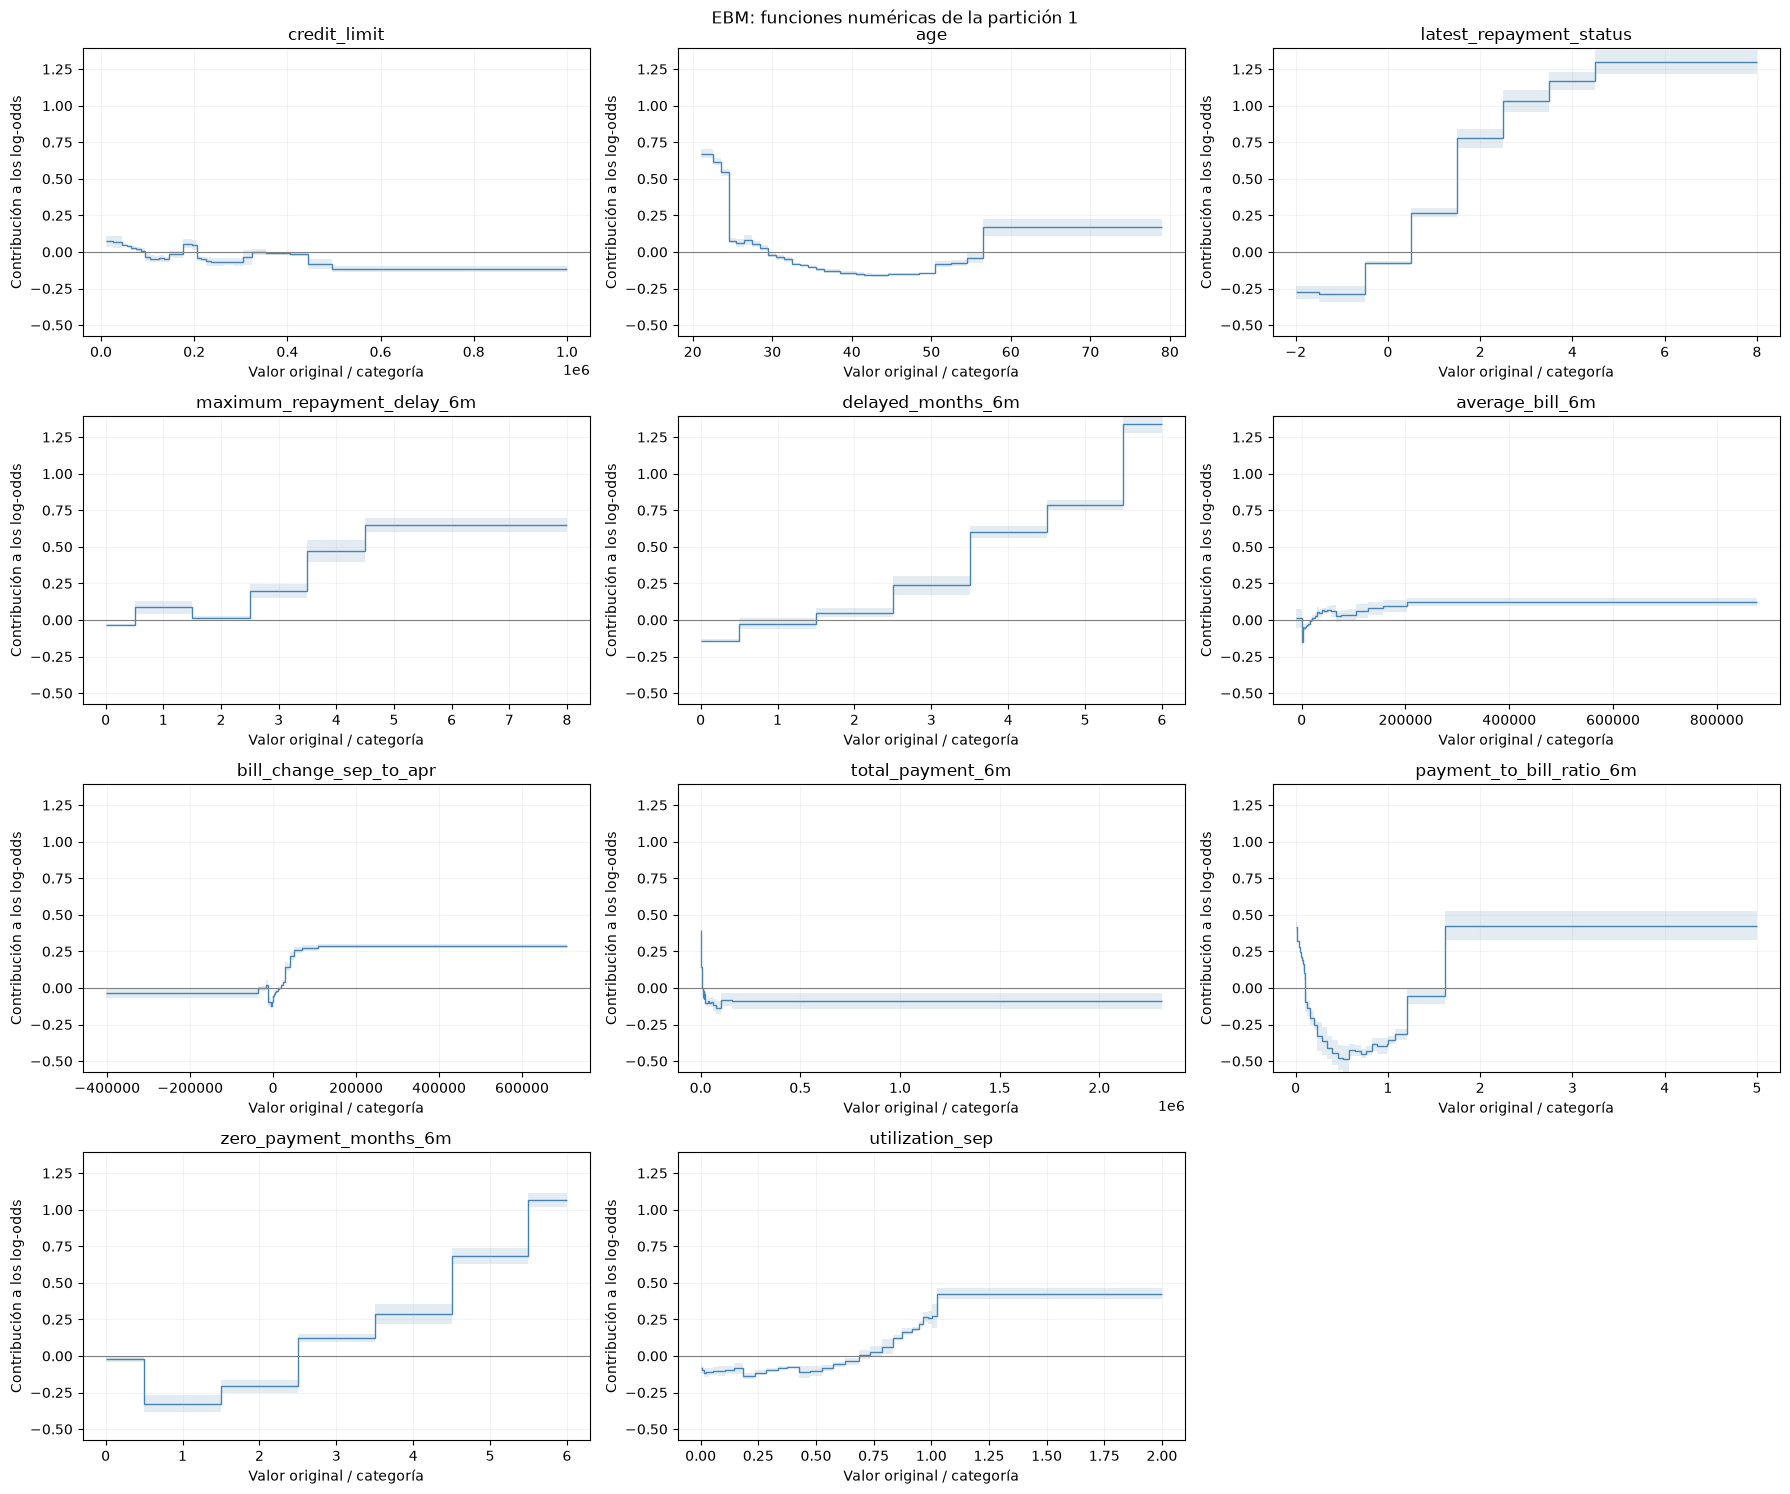

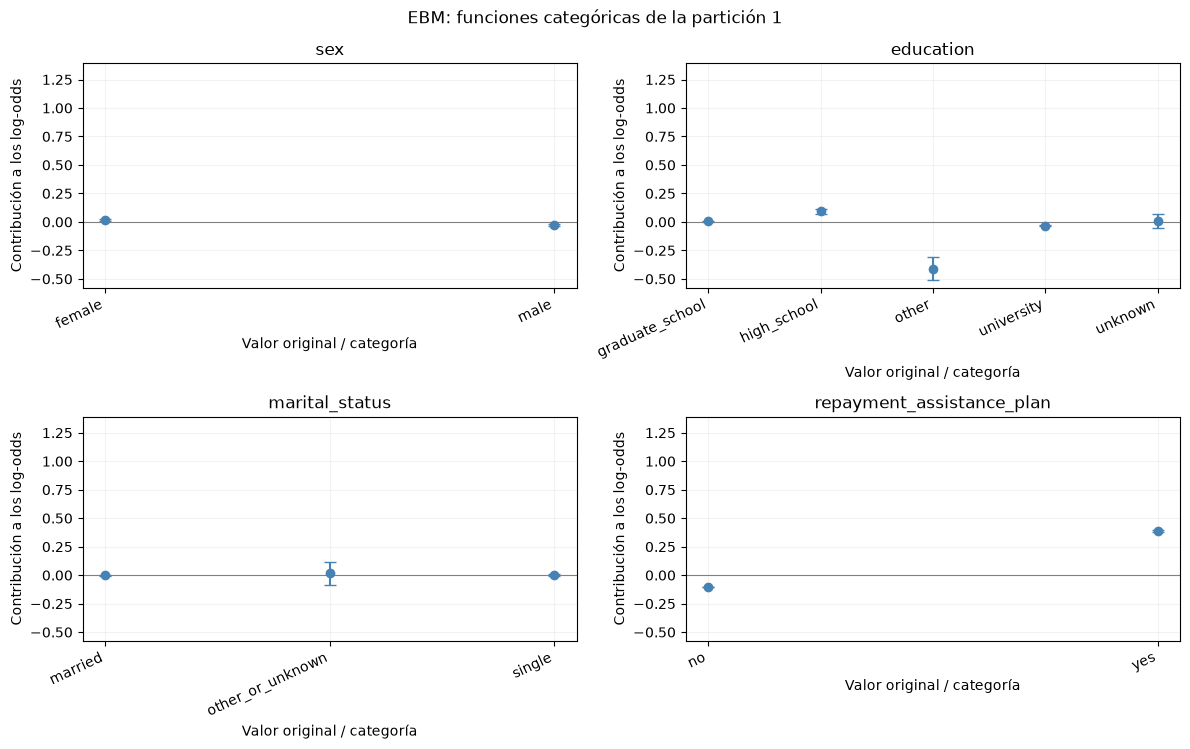

In [38]:
ebm_term_data = {
    name: ebm_global_explanation.data(term_idx)
    for term_idx, name in enumerate(ebm_reference_model.term_names_)
}


def plot_ebm_functions(variables, title, ncols):
    nrows = int(np.ceil(len(variables) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 3.8 * nrows), squeeze=False)
    for ax, variable in zip(axes.flat, variables):
        data = ebm_term_data[variable]
        scores = np.asarray(data["scores"], dtype=float)
        lower = data["lower_bounds"]
        upper = data["upper_bounds"]
        if variable in numeric_features:
            edges = np.asarray(data["names"], dtype=float)
            ax.stairs(scores, edges, baseline=None, color="steelblue")
            if lower is not None and upper is not None:
                ax.stairs(np.asarray(upper), edges, baseline=np.asarray(lower),
                          fill=True, alpha=0.15, color="steelblue")
        else:
            labels = data["names"]
            positions = np.arange(len(labels))
            errors = None if lower is None else np.vstack([
                scores - np.asarray(lower), np.asarray(upper) - scores
            ])
            ax.errorbar(positions, scores, yerr=errors, fmt="o", capsize=4, color="steelblue")
            ax.set_xticks(positions, labels=labels, rotation=25, ha="right")
        ax.axhline(0, color="gray", linewidth=0.8)
        ax.set_ylim(data["scores_range"])
        ax.set(title=variable, xlabel="Valor original / categoría", ylabel="Contribución a los log-odds")
        ax.grid(alpha=0.15)
    for ax in list(axes.flat)[len(variables):]:
        ax.set_visible(False)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


plot_ebm_functions(numeric_features, "EBM: funciones numéricas de la partición 1", ncols=3)
plot_ebm_functions(categorical_features, "EBM: funciones categóricas de la partición 1", ncols=2)

Las funciones numéricas confirman que la relación con la dificultad no puede resumirse siempre mediante un único signo. El cociente entre pagos y facturas disminuye su contribución en la región baja e intermedia y la aumenta en la región alta; la edad tiene mayor contribución en los más jóvenes, una región adulta de contribución negativa y un aumento en el tramo superior. En meses sin pago, los valores 1 y 2 tienen contribuciones menores que cero meses, mientras que a partir de 3 la contribución es positiva y creciente en este ajuste. Son formas del modelo, no afirmaciones sobre intervenciones.

La revisión de las demás funciones añade matices:

| Variable o grupo | Lectura de la función de la partición 1 |
| --- | --- |
| `latest_repayment_status` y `delayed_months_6m` | Las contribuciones aumentan en términos generales con los códigos positivos y la acumulación de meses con retraso. Los intervalos altos agrupan varios valores; sus mesetas no demuestran una equivalencia real entre esos estados. |
| `maximum_repayment_delay_6m` | La función no es completamente monótona y presenta contribuciones positivas en retrasos elevados. Su menor contribución global y la correlación con otros resúmenes aconsejan una interpretación conjunta. |
| `utilization_sep` | La contribución es principalmente negativa en la región baja e intermedia y aumenta hacia valores próximos o superiores a 1. No se identifica un efecto causal de incrementar la utilización. |
| `credit_limit` | Alterna pequeñas contribuciones positivas y negativas en la región baja e intermedia y se mantiene negativa en la región alta del ajuste. No reproduce un efecto lineal uniforme del límite. |
| `average_bill_6m` y `bill_change_sep_to_apr` | Muestran variaciones alrededor de los importes habituales y contribuciones positivas en algunos intervalos altos. Los rangos extremos comprimen los detalles de la figura; se requiere consultar la vista interactiva y su distribución. |
| `total_payment_6m` | La contribución es positiva para pagos nulos o muy pequeños y queda próxima a cero, ligeramente negativa, en una amplia región posterior. El ancho de la última meseta procede de los bins, no de evidencia uniforme para todos los importes elevados. |
| `education` | `unknown` es positiva y `other` negativa en este modelo, mientras que las categorías más frecuentes tienen contribuciones más próximas a cero. Los niveles poco frecuentes no justifican conclusiones generales sobre educación. |
| `sex` y `marital_status` | Sus contribuciones son pequeñas respecto a los principales términos. Esto no demuestra ausencia de sesgos ni equidad. |
| `repayment_assistance_plan` | La separación entre `yes` y `no` es clara en el ajuste, pero debe entenderse considerando la asignación selectiva del plan. |

Las regiones con pocos registros y las bandas de variación requieren cautela. Una banda estrecha entre cuatro réplicas tampoco garantiza que la función sea correcta fuera del conjunto. Las numéricas conservan sus unidades originales, lo que permite relacionar los intervalos con el diccionario sin confundirlos con una probabilidad aislada.

### <a id="sec-6-7"></a> 6.7. Variabilidad de las contribuciones globales

Se compara la media absoluta de contribución de cada variable en los cinco modelos. La tabla y los puntos muestran si el orden y la magnitud son consistentes. Esta comparación combina variaciones del ajuste, de sus configuraciones y de las distribuciones de entrenamiento utilizadas para ponderar las contribuciones.

Una importancia media similar no garantiza una función con la misma forma o signo. Por eso la siguiente subsección compara también muestras de las funciones. Con cinco entrenamientos solapados, las cajas son resúmenes descriptivos y no intervalos de confianza.

,Media,Desviación típica,Mínimo,Máximo
payment_to_bill_ratio_6m,0.3053,0.0090,0.2934,0.3152
latest_repayment_status,0.2297,0.0092,0.2156,0.2395
zero_payment_months_6m,0.1982,0.0081,0.1890,0.2082
delayed_months_6m,0.1917,0.0104,0.1743,0.2004
repayment_assistance_plan,0.1670,0.0069,0.1589,0.1769
age,0.1555,0.0137,0.1419,0.1758
utilization_sep,0.1531,0.0184,0.1259,0.1728
total_payment_6m,0.0902,0.0060,0.0816,0.0968
bill_change_sep_to_apr,0.0775,0.0081,0.0674,0.0896
average_bill_6m,0.0497,0.0090,0.0409,0.0621


/tmp/ipykernel_425044/293314989.py:17: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot([ebm_importance_by_fold[variable].dropna().to_numpy() for variable in plot_variables],


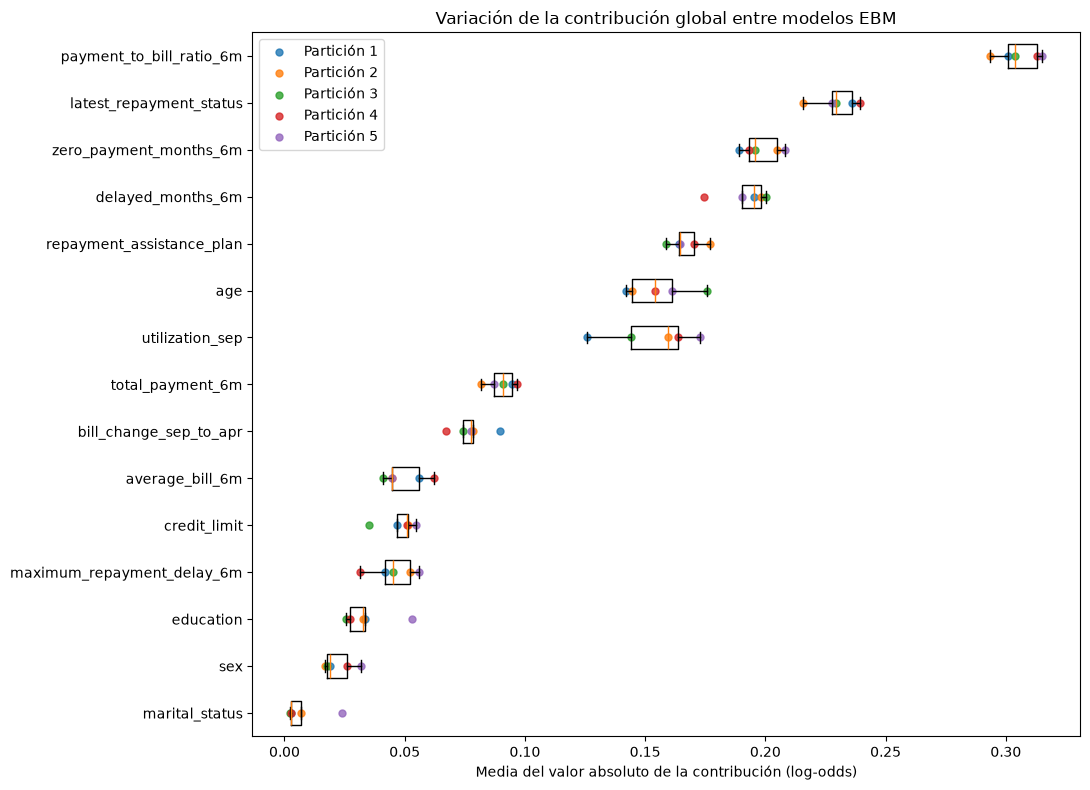

In [39]:
ebm_importance_by_fold = pd.DataFrame([
    pd.Series(pipeline["model"].term_importances(), index=pipeline["model"].term_names_, name=fold)
    for fold, pipeline in enumerate(ebm_models, start=1)
])
ebm_importance_by_fold.index.name = "Partición"
ebm_importance_stability = pd.DataFrame({
    "Media": ebm_importance_by_fold.mean(),
    "Desviación típica": ebm_importance_by_fold.std(ddof=1),
    "Mínimo": ebm_importance_by_fold.min(),
    "Máximo": ebm_importance_by_fold.max(),
}).sort_values("Media", ascending=False)
display(ebm_importance_stability.round(4))

plot_variables = ebm_importance_stability.index[::-1]
positions = np.arange(1, len(plot_variables) + 1)
fig, ax = plt.subplots(figsize=(11, 8))
ax.boxplot([ebm_importance_by_fold[variable].dropna().to_numpy() for variable in plot_variables],
           vert=False, positions=positions, showfliers=False)
for fold in ebm_importance_by_fold.index:
    ax.scatter(ebm_importance_by_fold.loc[fold, plot_variables], positions,
               s=25, alpha=0.8, label=f"Partición {fold}")
ax.set_yticks(positions, labels=plot_variables)
ax.set(title="Variación de la contribución global entre modelos EBM",
       xlabel="Media del valor absoluto de la contribución (log-odds)")
ax.legend()
plt.tight_layout()
plt.show()

El **cociente entre pagos y facturas tiene la mayor contribución global en los cinco modelos**: su mínimo (0,2931) supera el máximo observado de cualquiera de las demás variables. Su media es 0,3072 y su desviación típica 0,0103. El estado reciente de pago mantiene una contribución elevada (media 0,2270; desviación 0,0112).

Los meses sin pago (0,1961; desviación 0,0233) y los meses con retraso (0,1899; desviación 0,0085) tienen magnitudes próximas, pero el primero varía más. No debe fijarse un orden universal entre ambos a partir de la partición 1. El plan de asistencia mantiene una media 0,1656 y desviación 0,0087, y la edad 0,1535 y 0,0050.

Entre los términos de menor magnitud, `average_bill_6m` muestra variación apreciable: de 0,0318 a 0,0822. `sex` varía entre 0,0089 y 0,0381, aunque permanece muy por debajo de las principales contribuciones. La estabilidad del núcleo de variables es descriptiva; los cinco entrenamientos se solapan y los valores absolutos no informan por sí solos de la estabilidad de sus signos o formas.

### <a id="sec-6-8"></a> 6.8. Comparación de las funciones en valores comunes

Se examinan las cinco variables con mayor contribución global en la partición 1 y la edad, cuya forma presenta cambios de dirección. La selección es descriptiva y no utiliza las métricas externas para cambiar los modelos. Se evalúan sus términos sobre los mismos valores originales: todos los niveles observados en las categóricas y variables con pocos valores, o 21 cuantiles del entrenamiento de la partición 1 para las numéricas de mayor cardinalidad.

`eval_terms` devuelve las contribuciones de los términos, sin intercepto. Las líneas entre muestras numéricas sirven de guía y no reproducen necesariamente todos los saltos de los bins de cada modelo. Los niveles nominales se dibujan como puntos separados, sin imponerles orden. Las funciones están centradas con entrenamientos diferentes; un desplazamiento pequeño puede reflejar ese centrado además de cambios en su forma.

Para evaluar un término se crean entradas de sondeo cambiando solo esa variable respecto a una fila base. **No son clientes nuevos ni ejemplos de intervenciones**: únicamente permiten consultar cada función aditiva, sin interpretar la probabilidad completa de esas combinaciones.

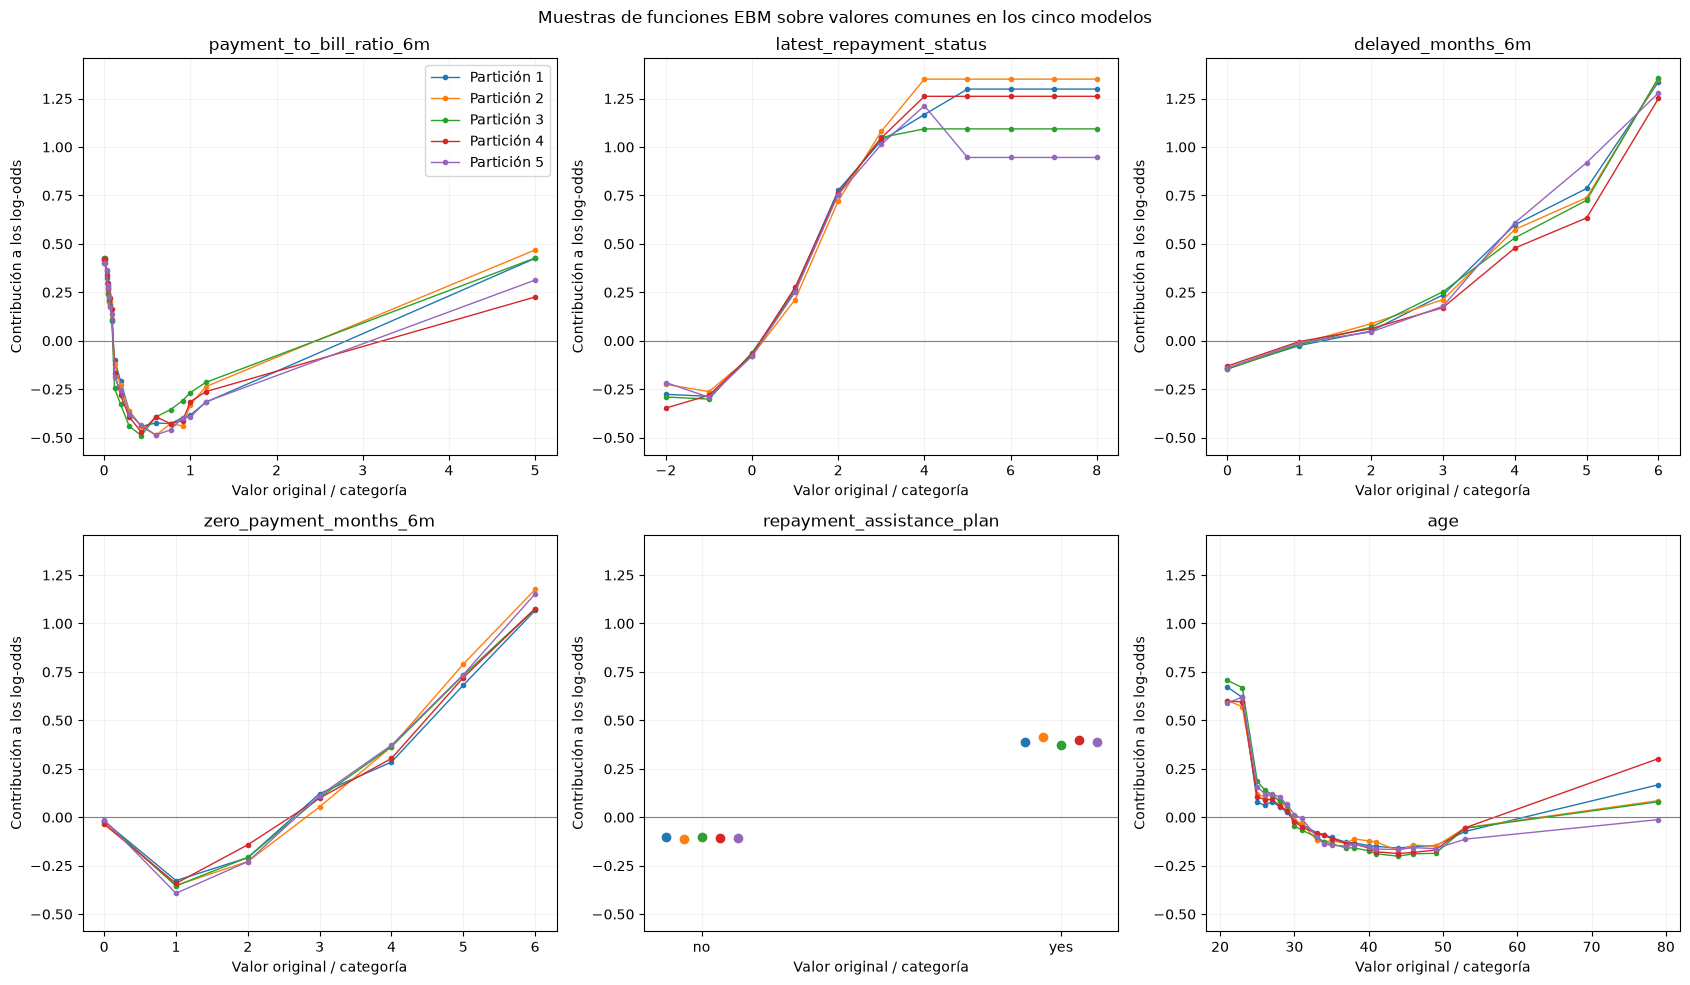

In [40]:
EBM_CURVE_VARIABLES = list(dict.fromkeys(
    ebm_global_importance["Variable"].head(5).tolist() + ["age"]
))
ebm_probe_train = X_raw.iloc[cv_splits[EBM_REFERENCE_FOLD - 1][0]]
ebm_curve_comparison = {}
for variable in EBM_CURVE_VARIABLES:
    observed = ebm_probe_train[variable].dropna()
    if variable in categorical_features or observed.nunique() <= 20:
        grid = sorted(observed.unique())
    else:
        grid = np.unique(np.quantile(observed, np.linspace(0, 1, 21)))
    probe = pd.concat([ebm_probe_train.iloc[[0]]] * len(grid), ignore_index=True)
    probe[variable] = grid
    table = pd.DataFrame({"Valor": grid})
    for fold, pipeline in enumerate(ebm_models, start=1):
        model = pipeline["model"]
        feature_idx = list(model.feature_names_in_).index(variable)
        term_idx = next(i for i, features in enumerate(model.term_features_)
                        if tuple(features) == (feature_idx,))
        table[f"Partición {fold}"] = model.eval_terms(pipeline["preprocess"].transform(probe))[:, term_idx]
    ebm_curve_comparison[variable] = table

fig, axes = plt.subplots(2, 3, figsize=(17, 10))
colors = plt.cm.tab10(np.arange(N_SPLITS))
all_values = np.concatenate([
    table.drop(columns="Valor").to_numpy().ravel() for table in ebm_curve_comparison.values()
])
y_limits = (all_values.min() - 0.1, all_values.max() + 0.1)
for ax, variable in zip(axes.flat, EBM_CURVE_VARIABLES):
    table = ebm_curve_comparison[variable]
    for fold in range(1, N_SPLITS + 1):
        scores = table[f"Partición {fold}"]
        if variable in categorical_features:
            positions = np.arange(len(table)) + (fold - 3) * 0.05
            ax.scatter(positions, scores, color=colors[fold - 1], label=f"Partición {fold}")
            ax.set_xticks(np.arange(len(table)), labels=table["Valor"])
        else:
            ax.plot(table["Valor"], scores, marker=".", linewidth=1,
                    color=colors[fold - 1], label=f"Partición {fold}")
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.set_ylim(y_limits)
    ax.set(title=variable, xlabel="Valor original / categoría", ylabel="Contribución a los log-odds")
    ax.grid(alpha=0.15)
for ax in list(axes.flat)[len(EBM_CURVE_VARIABLES):]:
    ax.set_visible(False)
axes.flat[0].legend()
fig.suptitle("Muestras de funciones EBM sobre valores comunes en los cinco modelos")
plt.tight_layout()
plt.show()

Las muestras sobre valores comunes muestran un **núcleo de formas consistente entre los cinco modelos**, con diferencias de magnitud y algunas discrepancias locales:

- **Cociente entre pagos y facturas:** todos los modelos muestran contribución positiva para valores muy bajos, negativa en la región intermedia y positiva en el extremo alto representado. La no monotonía se reproduce en los cinco ajustes. El tramo dibujado entre las últimas muestras es una guía visual: no demuestra crecimiento lineal entre esos valores ni localiza todos los saltos de los bins.
- **Estado reciente de pago:** los modelos son próximos para los códigos habituales y se separan más en los elevados. En la partición 4, la contribución disminuye al pasar del código 4 al 5, mientras que otros ajustes mantienen mesetas distintas. No puede afirmarse que la función sea creciente en todos los códigos y entrenamientos. Los valores altos poco frecuentes requieren especial cautela.
- **Meses sin pago:** la contribución de un mes sin pago es menor que la de cero meses en todos los ajustes, y las contribuciones crecen al acumular varios meses. La diferencia entre modelos es más visible en los recuentos altos. Este patrón condicional no prueba que un mes sin pago proteja frente a la dificultad.
- **Meses con retraso:** los cinco modelos presentan un aumento de contribución al acumular retrasos, con mayor separación en los valores altos. No se interpreta como un efecto independiente del retraso máximo o del estado reciente.
- **Plan de asistencia:** `no` se mantiene con contribución negativa y `yes` con positiva en todos los modelos. La asociación es consistente en estos ajustes y sigue sin identificar el efecto causal de recibir asistencia.
- **Edad:** se repite la contribución elevada en las edades más jóvenes, una región adulta de contribución negativa y un aumento hacia el tramo superior. La magnitud de este último difiere entre modelos y las edades extremas tienen menor respaldo de datos.

Esta comparación respalda la repetición de algunas formas en el ejercicio, pero no su validez causal ni poblacional. No se han cambiado las funciones para imponer monotonicidad o hacerlas coincidir con una expectativa previa.

### <a id="sec-6-9"></a> 6.9. Síntesis de la interpretación y limitaciones

EBM conserva una estructura de 15 términos univariantes sin interacciones y permite explicar la predicción como suma de contribuciones en log-odds. Las funciones muestran umbrales, mesetas y cambios de dirección que la representación logística lineal no recoge del mismo modo. El cociente entre pagos y facturas presenta la mayor media absoluta de contribución en los cinco ajustes; junto al estado reciente, los meses sin pago y los meses con retraso, constituye una parte consistente de la explicación global.

La estabilidad no es uniforme. Las categorías poco frecuentes, los estados de retraso elevados y las edades o importes extremos necesitan cautela. Los resúmenes correlacionados pueden repartirse la información de distintas formas, y ni sus curvas ni su clasificación por contribución identifican efectos independientes. La asociación positiva del plan de asistencia se mantiene, pero no autoriza a concluir que el plan cause perjuicio.

La evaluación externa obtiene ROC-AUC media 0,7755. El umbral ajustado favorece la detección y la exactitud equilibrada a costa de precisión y exactitud total. La explicabilidad aporta información adicional a esas métricas: permite identificar relaciones no monótonas, discrepancias entre modelos y regiones cuyo respaldo es limitado. No garantiza causalidad, equidad, calibración ni validez fuera del conjunto semisintético.

La interpretación global de EBM queda documentada. La comparación conjunta de rendimiento se desarrollará en el apartado 7 y las explicaciones locales para casos comunes en el 8. No se ha seleccionado todavía una familia final ni se ha utilizado el test sin etiquetas para ajustar decisiones.

[Volver al índice](#indice)

## <a id="sec-7"></a> 7. Comparación del rendimiento

### <a id="sec-7-1"></a> 7.1. Tabla conjunta de configuraciones y métricas

Se comparan las tres familias sobre las **mismas cinco validaciones externas**, con selección de configuraciones y umbrales dentro de cada entrenamiento. No se entrenan modelos nuevos ni se utilizan etiquetas del test. La tabla principal presenta una fila por clase de estimador, las configuraciones elegidas entre particiones y las seis métricas como **media ± desviación típica muestral**. Se incluye la referencia mayoritaria para contextualizar los resultados.

La primera tabla utiliza los umbrales ajustados internamente; la segunda muestra los mismos modelos con umbral 0,5. Cuando las configuraciones o umbrales varían, se indican sus valores observados y no se atribuyen los resultados a una única configuración final. Las métricas se calculan como medias de cinco particiones, no sobre todas las probabilidades OOF mezcladas.

Antes de comparar errores, se comprueba que los resultados OOF estén alineados por fila, identificador, etiqueta y partición. Si se reinició el kernel, deben recuperarse mediante la ejecución de los apartados anteriores: las tablas visibles guardadas en el notebook no restauran las variables de Python.

In [41]:
comparison_families = {
    "Árbol": {"key": "tree", "estimator": "DecisionTreeClassifier",
              "default": tree_scores_default, "tuned": tree_scores_tuned,
              "settings": tree_fold_settings, "oof": tree_oof_results,
              "config_columns": ["max_depth", "min_samples_leaf"]},
    "Regresión logística": {"key": "logistic", "estimator": "LogisticRegression",
                           "default": lr_scores_default, "tuned": lr_scores_tuned,
                           "settings": lr_fold_settings, "oof": lr_oof_results,
                           "config_columns": ["Penalización", "C"]},
    "EBM": {"key": "ebm", "estimator": "ExplainableBoostingClassifier",
            "default": ebm_scores_default, "tuned": ebm_scores_tuned,
            "settings": ebm_fold_settings, "oof": ebm_oof_results,
            "config_columns": ["max_bins", "min_samples_leaf"]},
}
comparison_metric_labels = {
    "roc_auc": "ROC-AUC", "accuracy": "Exactitud",
    "balanced_accuracy": "Exactitud equilibrada", "recall": "Sensibilidad",
    "precision": "Precisión", "f1": "F1",
}
expected_fold_numbers = np.zeros(len(y), dtype=int)
for fold, (_, valid_idx) in enumerate(cv_splits, start=1):
    expected_fold_numbers[valid_idx] = fold


def observed_values(series):
    values = sorted(series.dropna().unique())
    return ", ".join(
        f"{value:g}" if isinstance(value, (int, float, np.integer, np.floating)) else str(value)
        for value in values
    )


comparison_rows = []
comparison_default_rows = []
for name, family in comparison_families.items():
    frame = family["oof"]
    if not frame.index.equals(X_raw.index) or not frame[ID_COLUMN].equals(train_raw[ID_COLUMN]):
        raise ValueError(f"Las filas o los identificadores OOF no coinciden para {name}.")
    if not np.array_equal(frame["true_class"].to_numpy(), y.to_numpy()):
        raise ValueError(f"Las etiquetas OOF no coinciden para {name}.")
    if not np.array_equal(frame["fold"].to_numpy(), expected_fold_numbers):
        raise ValueError(f"Las particiones OOF no coinciden para {name}.")
    for version in ("default", "tuned"):
        if list(family[version].index) != list(range(1, N_SPLITS + 1)):
            raise ValueError(f"No están las cinco particiones ordenadas para {name}.")
    config = "; ".join(
        f"{column}={{{observed_values(family['settings'][column])}}}"
        for column in family["config_columns"]
    )
    if name == "EBM":
        config = "interactions=0; " + config
    row = {"Estimador": family["estimator"], "Configuraciones observadas": config,
           "Umbrales internos": observed_values(family["settings"]["Umbral"])}
    default_row = {"Estimador": family["estimator"]}
    for metric, label in comparison_metric_labels.items():
        tuned_scores = family["tuned"][metric]
        default_scores = family["default"][metric]
        row[label] = f"{tuned_scores.mean():.4f} ± {tuned_scores.std(ddof=1):.4f}"
        default_row[label] = f"{default_scores.mean():.4f} ± {default_scores.std(ddof=1):.4f}"
    comparison_rows.append(row)
    comparison_default_rows.append(default_row)

baseline_row = {"Estimador": "DummyClassifier", "Configuraciones observadas": "strategy=most_frequent",
                "Umbrales internos": "No se ajusta"}
for metric, label in comparison_metric_labels.items():
    baseline_row[label] = f"{baseline_scores[metric].mean():.4f} ± {baseline_scores[metric].std(ddof=1):.4f}"
comparison_results = pd.DataFrame(comparison_rows + [baseline_row]).set_index("Estimador")
comparison_results_default = pd.DataFrame(comparison_default_rows).set_index("Estimador")
print("Resultados con umbrales seleccionados internamente:")
with pd.option_context("display.max_colwidth", None, "display.max_columns", None):
    display(comparison_results)
print("Los mismos modelos con umbral 0,5:")
display(comparison_results_default)
print("Predicciones OOF alineadas para los tres modelos.")

Resultados con umbrales seleccionados internamente:


,Configuraciones observadas,Umbrales internos,ROC-AUC,Exactitud,Exactitud equilibrada,Sensibilidad,Precisión,F1
Estimador,,,,,,,,
DecisionTreeClassifier,max_depth={3}; min_samples_leaf={500},"0.2, 0.25",0.7360 ± 0.0064,0.7743 ± 0.0151,0.6709 ± 0.0083,0.4912 ± 0.0184,0.4713 ± 0.0286,0.4804 ± 0.0140
LogisticRegression,"Penalización={l1, l2}; C={0.1, 1}","0.2, 0.25",0.7518 ± 0.0068,0.7405 ± 0.0264,0.6809 ± 0.0033,0.5774 ± 0.0446,0.4223 ± 0.0277,0.4860 ± 0.0072
ExplainableBoostingClassifier,"interactions=0; max_bins={32}; min_samples_leaf={10, 50}","0.2, 0.25",0.7753 ± 0.0076,0.7346 ± 0.0259,0.6998 ± 0.0044,0.6394 ± 0.0532,0.4214 ± 0.0298,0.5057 ± 0.0054
DummyClassifier,strategy=most_frequent,No se ajusta,0.5000 ± 0.0000,0.7879 ± 0.0001,0.5000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000


Los mismos modelos con umbral 0,5:


,ROC-AUC,Exactitud,Exactitud equilibrada,Sensibilidad,Precisión,F1
Estimador,,,,,,
DecisionTreeClassifier,0.7360 ± 0.0064,0.8044 ± 0.0019,0.5625 ± 0.0054,0.1424 ± 0.0119,0.6876 ± 0.0140,0.2357 ± 0.0166
LogisticRegression,0.7518 ± 0.0068,0.8109 ± 0.0013,0.6046 ± 0.0030,0.2463 ± 0.0077,0.6414 ± 0.0117,0.3558 ± 0.0075
ExplainableBoostingClassifier,0.7753 ± 0.0076,0.8182 ± 0.0016,0.6289 ± 0.0046,0.3000 ± 0.0116,0.6570 ± 0.0124,0.4117 ± 0.0099


Predicciones OOF alineadas para los tres modelos.


En la ejecución documentada, la ROC-AUC media ordena las familias como **EBM (0,7755), regresión logística (0,7515) y árbol (0,7372)**. Con umbrales ajustados, EBM presenta las mayores medias de exactitud equilibrada (0,6997), sensibilidad (0,6405) y F1 (0,5068). El árbol mantiene mayor exactitud (0,7793) y precisión (0,4805) que las otras dos familias con sus umbrales ajustados.

Logística y árbol tienen F1 ajustados muy próximos (0,4833 y 0,4846), aunque no detectan la misma proporción de positivos: su sensibilidad media es 0,5955 y 0,4890, respectivamente. Por ello, una sola métrica puede ocultar diferencias de comportamiento.

Con umbral 0,5, EBM obtiene la mayor exactitud media (0,8178), seguida de logística (0,8106) y árbol (0,8040), pero todos detectan menos del 30 % de los positivos. Ajustar por exactitud equilibrada mejora la detección y reduce los aciertos totales en los tres modelos. La exactitud ajustada queda por debajo de la referencia mayoritaria en las tres familias; esto debe mantenerse visible dado que la exactitud del test interviene en la evaluación del proyecto.

### <a id="sec-7-2"></a> 7.2. Comparación por partición y variabilidad

Las líneas unen los resultados de una misma familia en las cinco particiones, identificadas de forma común. Se muestran ROC-AUC y exactitud equilibrada con umbral ajustado. Las particiones no constituyen una secuencia temporal y las líneas no representan una tendencia temporal.

La tabla de diferencias compara pares de modelos dentro de cada partición y resume su diferencia media, desviación típica y número de diferencias positivas. Es una comparación descriptiva: los entrenamientos se solapan y cinco resultados no bastan para interpretar la desviación típica o la coincidencia de signos como una prueba de significación. No se realizan búsquedas nuevas con estos resultados externos.

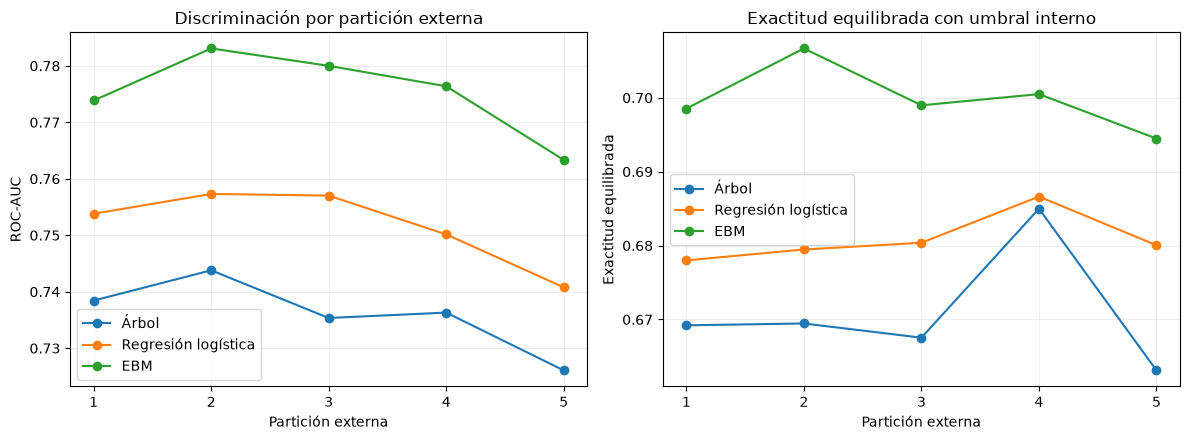

,Comparación (A − B),Métrica,Diferencia media,Desviación típica,Particiones con A > B,Empates
0,EBM − Regresión logística,ROC-AUC,0.0235,0.0025,5,0
1,EBM − Regresión logística,Exactitud equilibrada,0.0189,0.0054,5,0
2,EBM − Regresión logística,F1,0.0198,0.0099,5,0
3,EBM − Árbol,ROC-AUC,0.0393,0.0035,5,0
4,EBM − Árbol,Exactitud equilibrada,0.0290,0.0081,5,0
5,EBM − Árbol,F1,0.0254,0.0173,4,0
6,Regresión logística − Árbol,ROC-AUC,0.0158,0.0033,5,0
7,Regresión logística − Árbol,Exactitud equilibrada,0.0100,0.0056,5,0
8,Regresión logística − Árbol,F1,0.0056,0.0076,4,0


In [42]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, family in comparison_families.items():
    for ax, metric, title in (
        (axes[0], "roc_auc", "Discriminación por partición externa"),
        (axes[1], "balanced_accuracy", "Exactitud equilibrada con umbral interno"),
    ):
        ax.plot(family["tuned"].index, family["tuned"][metric], marker="o", label=name)
        ax.set(title=title, xlabel="Partición externa", ylabel=comparison_metric_labels[metric])
        ax.set_xticks(range(1, N_SPLITS + 1))
        ax.grid(alpha=0.2)
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

comparison_pairs = [("EBM", "Regresión logística"), ("EBM", "Árbol"), ("Regresión logística", "Árbol")]
paired_rows = []
for first, second in comparison_pairs:
    for metric in ["roc_auc", "balanced_accuracy", "f1"]:
        difference = comparison_families[first]["tuned"][metric] - comparison_families[second]["tuned"][metric]
        paired_rows.append({
            "Comparación (A − B)": f"{first} − {second}",
            "Métrica": comparison_metric_labels[metric],
            "Diferencia media": difference.mean(),
            "Desviación típica": difference.std(ddof=1),
            "Particiones con A > B": int((difference > 0).sum()),
            "Empates": int((difference == 0).sum()),
        })
comparison_paired_differences = pd.DataFrame(paired_rows)
display(comparison_paired_differences.round(4))

La diferencia media de ROC-AUC de EBM respecto a logística es aproximadamente **0,0239**, y respecto al árbol, **0,0383**. EBM supera a las otras dos familias en ROC-AUC, exactitud equilibrada y F1 ajustados en las cinco particiones. Logística supera al árbol en ROC-AUC y exactitud equilibrada en las cinco; en F1 lo supera en cuatro, pero su mayor diferencia negativa en la otra deja una media ligeramente inferior (−0,0013). El número de particiones ganadas y la diferencia media resumen aspectos distintos. La comparación indica una ventaja descriptiva de discriminación dentro de las búsquedas realizadas, no superioridad universal de la familia ni significación estadística demostrada.

La variabilidad entre particiones debe interpretarse con el nivel medio y con los cambios de umbral. Por ejemplo, una desviación típica menor no compensa automáticamente una media inferior, y la estabilidad de las métricas no implica estabilidad de las explicaciones.

### <a id="sec-7-3"></a> 7.3. Análisis de falsos positivos y falsos negativos

Se construyen matrices de confusión con las **predicciones externas OOF**, de modo que cada registro contribuye una vez y su modelo no lo utilizó para entrenar. Para los umbrales ajustados, cada registro conserva el que se seleccionó en su entrenamiento externo; no se aplica un umbral nuevo común después de observar sus etiquetas.

La tabla cuenta verdaderos negativos (VN), falsos positivos (FP), falsos negativos (FN) y verdaderos positivos (VP). Añade las tasas de falsos positivos entre los negativos reales y de falsos negativos entre los positivos reales. Las matrices son recuentos acumulados de los 25.000 registros: no son medias de particiones, por lo que sus tasas agregadas pueden diferir ligeramente de las medias anteriores.

Detectar más positivos puede aumentar las alertas sobre casos sin dificultad. Sin costes de error ni un objetivo operativo especificados, no se asigna un coste económico inventado a FP y FN ni se declara una regla de decisión universalmente preferible.

,Modelo,Decisión,VN,FP,FN,VP,Falsos positivos (%),Falsos negativos (%)
0,Árbol,"Umbral 0,5",19354,343,4548,755,1.74,85.76
1,Árbol,Umbral interno,16752,2945,2698,2605,14.95,50.88
2,Regresión logística,"Umbral 0,5",18966,731,3997,1306,3.71,75.37
3,Regresión logística,Umbral interno,15450,4247,2241,3062,21.56,42.26
4,EBM,"Umbral 0,5",18865,832,3712,1591,4.22,70.00
5,EBM,Umbral interno,14974,4723,1912,3391,23.98,36.06


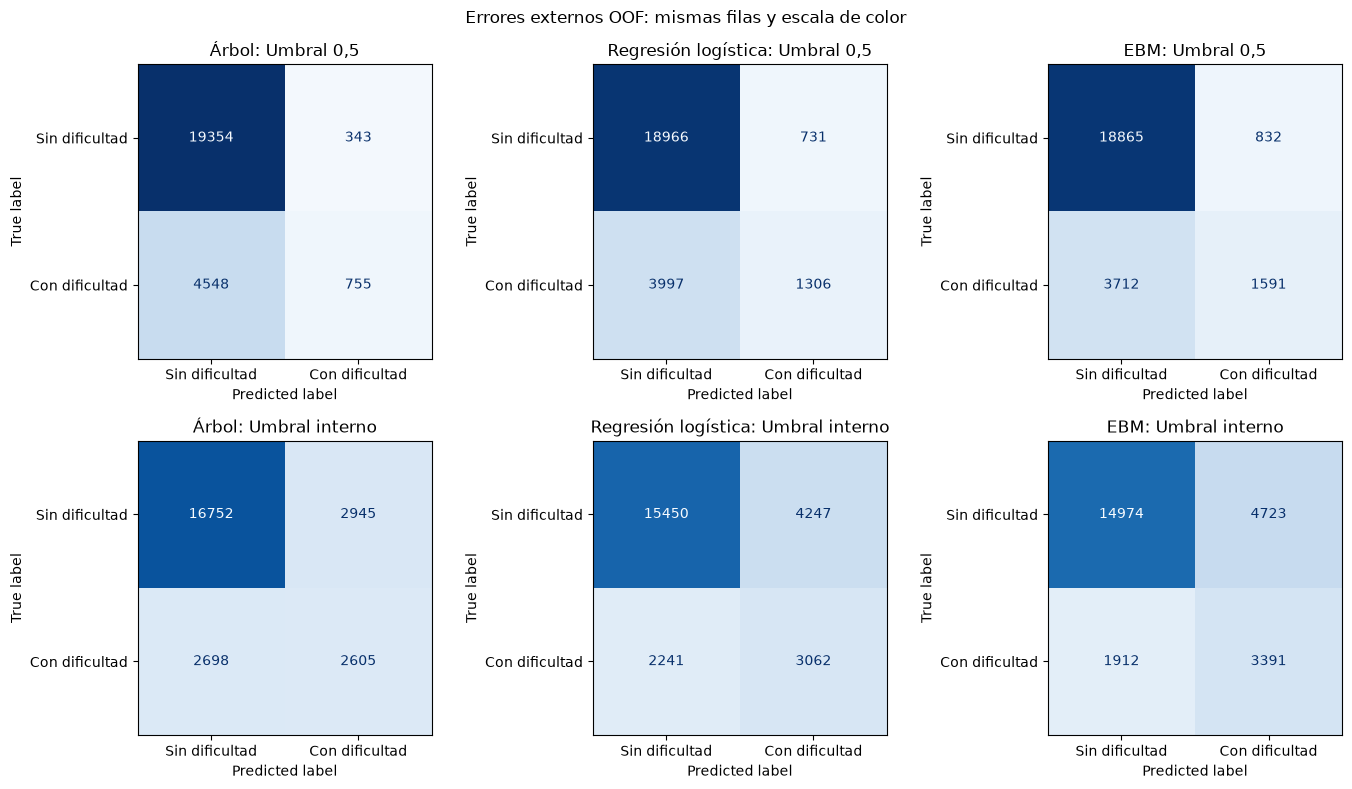

In [43]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

comparison_error_rows = []
comparison_confusions = {}
for name, family in comparison_families.items():
    frame = family["oof"]
    for rule, column in (("Umbral 0,5", "prediction_default"), ("Umbral interno", "prediction_tuned")):
        matrix = confusion_matrix(frame["true_class"], frame[column], labels=[0, 1])
        tn, fp, fn, tp = matrix.ravel()
        comparison_confusions[(name, rule)] = matrix
        comparison_error_rows.append({
            "Modelo": name, "Decisión": rule,
            "VN": tn, "FP": fp, "FN": fn, "VP": tp,
            "Falsos positivos (%)": 100 * fp / (tn + fp),
            "Falsos negativos (%)": 100 * fn / (tp + fn),
        })
comparison_error_counts = pd.DataFrame(comparison_error_rows)
display(comparison_error_counts.round(2))

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
maximum_count = max(matrix.max() for matrix in comparison_confusions.values())
for column_idx, name in enumerate(comparison_families):
    for row_idx, rule in enumerate(["Umbral 0,5", "Umbral interno"]):
        ax = axes[row_idx, column_idx]
        display_matrix = ConfusionMatrixDisplay(
            comparison_confusions[(name, rule)], display_labels=["Sin dificultad", "Con dificultad"]
        ).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
        display_matrix.im_.set_clim(0, maximum_count)
        ax.set_title(f"{name}: {rule}")
fig.suptitle("Errores externos OOF: mismas filas y escala de color")
plt.tight_layout()
plt.show()

Los recuentos concretan el intercambio entre tipos de error. Con umbrales internos, **EBM detecta 3.401 positivos y deja 1.902 sin detectar**; logística detecta 3.159 y deja 2.144, y el árbol detecta 2.593 y deja 2.710. EBM detecta **242 positivos más que logística**, a costa de **130 falsos positivos adicionales** (4.743 frente a 4.613).

Frente al árbol, EBM detecta **808 positivos más**, pero genera **1.936 falsos positivos adicionales**. El árbol tiene menos errores totales con sus umbrales internos, aunque deja sin detectar más casos de dificultad. Su mayor exactitud no equivale a mejor detección, ni la mayor detección de EBM implica que cometa menos errores de todos los tipos.

El efecto del umbral es importante: en EBM, pasar de 0,5 al umbral interno añade 1.820 verdaderos positivos y 3.909 falsos positivos. Esto explica por qué aumentan sensibilidad y exactitud equilibrada mientras disminuyen precisión y exactitud. Son recuentos externos acumulados; no se usan para elegir retrospectivamente otro umbral.

### <a id="sec-7-4"></a> 7.4. Coincidencias y discrepancias entre errores

Se comparan las decisiones con los umbrales internos para reconocer si los modelos fallan sobre los mismos registros. Un modelo con mejor media puede equivocarse en casos que otro resuelve. El acuerdo entre los tres tampoco certifica que una predicción sea correcta.

`comparison_cases` conserva identificadores, clase real, partición, probabilidades, umbrales y decisiones para el posterior análisis local. Aquí solo se describe el acuerdo; no se usan estas etiquetas para entrenar un ensamble, modificar umbrales o seleccionar variables. La interpretación de casos concretos y sus explicaciones se realizará en el apartado 8.

In [44]:
comparison_cases = pd.DataFrame({
    ID_COLUMN: train_raw[ID_COLUMN], "true_class": y, "fold": expected_fold_numbers
}, index=X_raw.index)
for name, family in comparison_families.items():
    key = family["key"]
    frame = family["oof"]
    comparison_cases[f"{key}_probability"] = frame["probability_class_1"]
    comparison_cases[f"{key}_threshold"] = frame["threshold"]
    comparison_cases[f"{key}_prediction"] = frame["prediction_tuned"]
    comparison_cases[f"{key}_error"] = frame["prediction_tuned"] != y

error_columns = [f"{family['key']}_error" for family in comparison_families.values()]
error_flags = comparison_cases[error_columns]
comparison_error_patterns = error_flags.value_counts().rename("Registros").reset_index()
comparison_error_patterns["Modelos equivocados"] = comparison_error_patterns.apply(
    lambda row: ", ".join(name for name, family in comparison_families.items()
                         if row[f"{family['key']}_error"]) or "Ninguno", axis=1
)
display(comparison_error_patterns[["Modelos equivocados", "Registros"]])

error_overlap_rows = []
for first, second in comparison_pairs:
    first_key = comparison_families[first]["key"]
    second_key = comparison_families[second]["key"]
    first_error = comparison_cases[f"{first_key}_error"]
    second_error = comparison_cases[f"{second_key}_error"]
    error_overlap_rows.append({
        "Modelo A": first, "Modelo B": second,
        "Ambos fallan": int((first_error & second_error).sum()),
        "Solo falla A": int((first_error & ~second_error).sum()),
        "Solo falla B": int((~first_error & second_error).sum()),
        "Predicciones diferentes": int((comparison_cases[f"{first_key}_prediction"] !=
                                         comparison_cases[f"{second_key}_prediction"]).sum()),
    })
display(pd.DataFrame(error_overlap_rows))

common_error_rows = []
for target_class in [0, 1]:
    class_flags = error_flags.loc[y == target_class]
    common_error_rows.append({
        "Clase real": target_class, "Registros": len(class_flags),
        "Todos aciertan": int((~class_flags.any(axis=1)).sum()),
        "Al menos uno falla": int(class_flags.any(axis=1).sum()),
        "Todos fallan": int(class_flags.all(axis=1).sum()),
    })
display(pd.DataFrame(common_error_rows))

,Modelos equivocados,Registros
0,Ninguno,15982
1,"Árbol, Regresión logística, EBM",3743
2,EBM,1386
3,"Regresión logística, EBM",1050
4,Regresión logística,939
5,"Árbol, Regresión logística",756
6,Árbol,688
7,"Árbol, EBM",456


,Modelo A,Modelo B,Ambos fallan,Solo falla A,Solo falla B,Predicciones diferentes
0,EBM,Regresión logística,4793,1842,1695,3537
1,EBM,Árbol,4199,2436,1444,3880
2,Regresión logística,Árbol,4499,1989,1144,3133


,Clase real,Registros,Todos aciertan,Al menos uno falla,Todos fallan
0,0,19697,13637,6060,2124
1,1,5303,2345,2958,1619


Los tres modelos aciertan simultáneamente en **16.056 registros (64,22 %)** y fallan simultáneamente en **3.833 (15,33 %)**, con sus umbrales internos. Los errores compartidos incluyen **2.199 negativos reales clasificados como positivos** y **1.634 positivos clasificados como negativos**. Estos últimos representan aproximadamente el 30,81 % de todos los casos de dificultad: una parte relevante no es detectada por ninguna de las tres reglas de decisión evaluadas.

También existen discrepancias: EBM y logística difieren en **3.170 predicciones**; en 1.529 solo falla EBM y en 1.641 solo falla logística. Por tanto, la ventaja media de EBM no significa que resuelva todos los casos que resuelve logística. El árbol y EBM difieren en 3.712 decisiones, y árbol y logística en 3.340.

Las coincidencias y discrepancias justifican examinar en el apartado 8 tanto casos con acuerdo como casos con explicaciones o decisiones distintas, incluyendo ambas clases. El acuerdo no garantiza acierto y estos recuentos no demuestran que un ensamble mejore el rendimiento sin entrenarlo y evaluarlo con un protocolo adecuado.

### <a id="sec-7-5"></a> 7.5. Rendimiento, complejidad e interpretabilidad

La complejidad se describe con medidas propias de cada representación, no con una puntuación arbitraria que equipare hojas, coeficientes e intervalos. En cada familia se utilizan los cinco modelos guardados. Los intervalos de EBM se cuentan a partir de sus cortes aprendidos y grupos categóricos, excluyendo los bins especiales de ausentes o categorías desconocidas.

| Familia | Qué debe inspeccionarse para entenderla | Ventaja y límite de su explicación |
| --- | --- | --- |
| Árbol | Recorridos, condiciones, soporte y probabilidad de cada hoja. | Permite leer las ocho reglas completas. El último nivel cambia entre entrenamientos y las probabilidades son constantes dentro de una hoja. |
| Regresión logística | Coeficientes, referencias, unidades de los contrastes y odds ratios. | Tiene una ecuación compacta, pero las asociaciones son condicionales y la correlación dificulta atribuir contribuciones independientes. La representación inicial impone linealidad en log-odds. |
| EBM aditivo | Quince funciones, sus intervalos/categorías y la suma de contribuciones. | Permite inspeccionar no linealidades sin interacciones explícitas. Requiere revisar más detalles y no elimina la ambigüedad entre variables correlacionadas ni la incertidumbre en zonas con pocos datos. |

Las búsquedas tuvieron distintos tamaños y límites: nueve configuraciones CART con profundidad máxima 3, ocho logísticas y cuatro EBM con límites de rondas, bags y bins. La comparación se refiere a **estos procedimientos y presupuestos**, no al mejor rendimiento alcanzable por cada familia.

In [45]:
def numeric_range(values):
    values = list(values)
    lower, upper = min(values), max(values)
    return str(lower) if lower == upper else f"{lower}–{upper}"


def original_logistic_variable(entry):
    if entry in feature_columns:
        return entry
    return next(variable for variable in categorical_features if entry.startswith(variable + "_"))


logistic_active_original_counts = []
for pipeline in lr_models:
    names = pipeline["preprocess"].get_feature_names_out()
    active_names = names[pipeline["model"].coef_[0] != 0]
    logistic_active_original_counts.append(len({original_logistic_variable(name) for name in active_names}))

ebm_regular_bin_counts = []
for pipeline in ebm_models:
    total_bins = 0
    for levels in pipeline["model"].bins_:
        bins = levels[0]
        total_bins += len(set(bins.values())) if isinstance(bins, dict) else len(bins) + 1
    ebm_regular_bin_counts.append(total_bins)

comparison_complexity = pd.DataFrame([
    {"Familia": "Árbol", "Variables originales disponibles": len(feature_columns),
     "Variables originales utilizadas": numeric_range((tree_importance_by_fold > 0).sum(axis=1)),
     "Representación": f"Profundidad {numeric_range(tree_fold_settings['Profundidad efectiva'])}; "
                        f"{numeric_range(tree_fold_settings['Hojas'])} hojas; {numeric_range(tree_fold_settings['Nodos'])} nodos",
     "Detalle adicional": "Reglas de hasta tres condiciones"},
    {"Familia": "Regresión logística", "Variables originales disponibles": len(feature_columns),
     "Variables originales utilizadas": numeric_range(logistic_active_original_counts),
     "Representación": f"{numeric_range(lr_fold_settings['Columnas transformadas'])} columnas; "
                        f"{numeric_range(lr_fold_settings['Coeficientes no nulos'])} coeficientes activos, más intercepto",
     "Detalle adicional": "Referencias categóricas y numéricas estandarizadas"},
    {"Familia": "EBM", "Variables originales disponibles": len(feature_columns),
     "Variables originales utilizadas": len(ebm_models[0]["model"].term_features_),
     "Representación": f"{numeric_range(ebm_fold_settings['Términos univariantes'])} funciones; cero interacciones",
     "Detalle adicional": f"{numeric_range(ebm_regular_bin_counts)} intervalos/grupos regulares en total"},
]).set_index("Familia")
with pd.option_context("display.max_colwidth", None):
    display(comparison_complexity)

,Variables originales disponibles,Variables originales utilizadas,Representación,Detalle adicional
Familia,,,,
Árbol,15,4–6,Profundidad 3; 8 hojas; 15 nodos,Reglas de hasta tres condiciones
Regresión logística,15,15,"19 columnas; 18–19 coeficientes activos, más intercepto",Referencias categóricas y numéricas estandarizadas
EBM,15,15,15 funciones; cero interacciones,249–250 intervalos/grupos regulares en total


La tabla concreta el esfuerzo de inspección de estos ajustes: el árbol utiliza **3–5 variables originales y ocho reglas**; logística mantiene **15–19 coeficientes activos sobre 19 columnas**, que corresponden a **14–15 variables originales**; EBM conserva **15 funciones con 249–250 intervalos o grupos categóricos regulares en total**.

La anulación de una columna one-hot no equivale a descartar toda su variable original, lo que explica la diferencia entre los conteos logísticos. Del mismo modo, los intervalos de EBM no son reglas conjuntas comparables uno a uno con las hojas del árbol. Estas medidas permiten describir el tamaño de cada representación, sin convertirlas en una escala única de interpretabilidad.

### <a id="sec-7-6"></a> 7.6. Discusión y alcance de la comparación

En la ejecución actual, EBM presenta la mejor discriminación media y, con ajuste interno del umbral, la mayor sensibilidad, exactitud equilibrada y F1. Su explicación exige revisar quince funciones, pero estas permiten reconocer relaciones no monótonas que quedan simplificadas en logística o en un árbol pequeño. El mejor resultado predictivo no convierte sus funciones en efectos causales.

El árbol ofrece la estructura más directamente inspeccionable como conjunto de reglas y mantiene mayor precisión y exactitud con sus umbrales ajustados, aunque su sensibilidad es menor. La logística ofrece un resumen por coeficientes y contrastes explícitos; sus resultados muestran que una ecuación relativamente compacta tampoco evita dificultades de interpretación por regularización, codificación y correlación. No se establece una clasificación universal de interpretabilidad: se describe qué puede entenderse y qué necesita cautela en cada representación.

La decisión final tendrá que explicitar qué equilibrio entre discriminación, errores y claridad de explicación se considera más adecuado. No se elige un umbral nuevo a partir de las matrices externas ni se decide la familia solo por una diferencia pequeña en una métrica. Elegir la familia con estos resultados puede introducir optimismo en la estimación de la ganadora, aunque sus búsquedas internas se hayan separado de la evaluación externa.

Las matrices muestran el coste en falsos positivos de mejorar la detección, y el análisis de coincidencias identifica tanto errores compartidos como casos que cada modelo resuelve de forma diferente. Estos resultados dejan preparada la selección descriptiva de casos para el apartado 8. La discusión comparada de las explicaciones se desarrollará en el 9, y la justificación y entrenamiento de la familia final, en el 10. No se han generado predicciones del test sin etiquetas.

[Volver al índice](#indice)

## <a id="sec-8"></a> 8. Interpretación local comparada

### <a id="sec-8-1"></a> 8.1. Selección de casos comunes y procedencia

Se utilizan **los mismos cuatro registros en las tres familias**, todos pertenecientes a la validación externa de la partición 1. Para cada modelo se utiliza el ajuste de esa partición, que no entrenó con dichos registros ni con sus perfiles idénticos. Las configuraciones y umbrales proceden únicamente de su entrenamiento interno.

Se fijan cuatro situaciones para examinar explicaciones y errores, incluyendo ambas clases:

| Caso | Clase real | Situación con los umbrales internos |
| --- | --- | --- |
| 1 | 0 | Los tres modelos aciertan: ausencia de dificultad. |
| 2 | 1 | Los tres modelos aciertan: presencia de dificultad. |
| 3 | 0 | El árbol acierta y EBM produce un falso positivo; se observa también la decisión logística. |
| 4 | 1 | Los tres modelos producen un falso negativo. |

Dentro de cada situación se escoge el primer identificador en orden alfabético. Es una selección reproducible de ejemplos, **no una muestra representativa ni una evaluación adicional**. Sus etiquetas se utilizan para describir los escenarios, no para reajustar los modelos. Las frecuencias de estos cuatro ejemplos no estiman las tasas de error de la población.

In [46]:
LOCAL_FOLD = 1
local_pool = comparison_cases.loc[comparison_cases["fold"] == LOCAL_FOLD].copy()
local_prediction_columns = [f"{family['key']}_prediction" for family in comparison_families.values()]
all_predict_zero = local_pool[local_prediction_columns].eq(0).all(axis=1)
all_predict_one = local_pool[local_prediction_columns].eq(1).all(axis=1)
local_scenarios = [
    ("Acuerdo correcto: clase 0", (local_pool["true_class"] == 0) & all_predict_zero),
    ("Acuerdo correcto: clase 1", (local_pool["true_class"] == 1) & all_predict_one),
    ("Clase 0: árbol correcto, falso positivo EBM",
     (local_pool["true_class"] == 0) & (local_pool["tree_prediction"] == 0) & (local_pool["ebm_prediction"] == 1)),
    ("Clase 1: falso negativo compartido", (local_pool["true_class"] == 1) & all_predict_zero),
]
selected_local_rows = []
for scenario, mask in local_scenarios:
    candidates = local_pool.loc[mask].sort_values(ID_COLUMN)
    if candidates.empty:
        raise ValueError(f"No hay registros del escenario '{scenario}' en la partición {LOCAL_FOLD}.")
    chosen = candidates.iloc[[0]].copy()
    chosen["Escenario"] = scenario
    selected_local_rows.append(chosen)
local_cases = pd.concat(selected_local_rows)
local_cases.insert(0, "Caso", [f"Caso {number}" for number in range(1, len(local_cases) + 1)])
local_positions = X_raw.index.get_indexer(local_cases.index)
local_train_idx, local_valid_idx = cv_splits[LOCAL_FOLD - 1]
if not np.isin(local_positions, local_valid_idx).all():
    raise ValueError("Un caso no pertenece a la validación externa indicada.")
if np.isin(profile_groups[local_positions], profile_groups[local_train_idx]).any():
    raise ValueError("Un perfil de los casos aparece en el entrenamiento externo.")
local_X = X_raw.loc[local_cases.index].copy()
local_y = y.loc[local_cases.index]
display(local_cases[["Caso", ID_COLUMN, "Escenario", "true_class", "fold"]])
local_input_table = local_X.copy()
local_input_table.insert(0, ID_COLUMN, local_cases[ID_COLUMN])
print("Variables originales de los mismos cuatro casos:")
with pd.option_context("display.max_columns", None):
    display(local_input_table)
print("Los cuatro casos y sus perfiles están fuera del entrenamiento de los modelos explicados.")

,Caso,row_id,Escenario,true_class,fold
798,Caso 1,CR26-100008,Acuerdo correcto: clase 0,0,1
24275,Caso 2,CR26-100025,Acuerdo correcto: clase 1,1,1
16209,Caso 3,CR26-100040,"Clase 0: árbol correcto, falso positivo EBM",0,1
24054,Caso 4,CR26-100209,Clase 1: falso negativo compartido,1,1


Variables originales de los mismos cuatro casos:


,row_id,credit_limit,sex,education,marital_status,age,latest_repayment_status,maximum_repayment_delay_6m,delayed_months_6m,average_bill_6m,bill_change_sep_to_apr,total_payment_6m,payment_to_bill_ratio_6m,zero_payment_months_6m,utilization_sep,repayment_assistance_plan
798,CR26-100008,40000,male,graduate_school,single,31,0,0,0,2400,8500,6300,0.43,1,0.21,no
24275,CR26-100025,30000,female,high_school,married,22,2,2,2,27500,5800,4300,0.03,0,1.02,no
16209,CR26-100040,70000,female,graduate_school,single,23,0,0,0,10800,-3000,7400,0.11,0,0.13,yes
24054,CR26-100209,50000,male,high_school,single,23,0,0,0,4500,7600,8000,0.29,1,0.16,no


Los cuatro casos y sus perfiles están fuera del entrenamiento de los modelos explicados.


### <a id="sec-8-2"></a> 8.2. Probabilidades, umbrales y decisiones

Se recalculan las probabilidades con los modelos guardados y se comprueba su coincidencia con las predicciones OOF. La tabla muestra la clase real, la probabilidad de dificultad, el umbral interno, las decisiones con 0,5 y con ese umbral, y el acierto con la regla interna.

Una probabilidad inferior a 0,5 puede dar una predicción positiva si supera el umbral interno. Las probabilidades de distintos modelos tampoco son automáticamente igual de fiables: aquí no se ha demostrado su calibración. Se conservará la distinción entre explicar cómo se obtuvo una probabilidad y explicar por qué esa probabilidad supera o no el umbral.

In [47]:
local_pipelines = {
    "Árbol": tree_models[LOCAL_FOLD - 1],
    "Regresión logística": lr_models[LOCAL_FOLD - 1],
    "EBM": ebm_models[LOCAL_FOLD - 1],
}
local_thresholds = {
    name: float(family["settings"].loc[LOCAL_FOLD, "Umbral"])
    for name, family in comparison_families.items()
}
local_probabilities = {}
local_prediction_rows = []
for name, pipeline in local_pipelines.items():
    key = comparison_families[name]["key"]
    probabilities = pipeline.predict_proba(local_X)[:, 1]
    if not np.allclose(probabilities, local_cases[f"{key}_probability"], rtol=1e-9, atol=1e-12):
        raise ValueError(f"Las probabilidades no coinciden con las OOF para {name}.")
    threshold = local_thresholds[name]
    if not np.allclose(local_cases[f"{key}_threshold"], threshold):
        raise ValueError(f"El umbral no coincide con el utilizado en las OOF para {name}.")
    local_probabilities[name] = probabilities
    for position, (_, case) in enumerate(local_cases.iterrows()):
        prediction = int(probabilities[position] >= threshold)
        if prediction != case[f"{key}_prediction"]:
            raise ValueError(f"La decisión no coincide con la OOF para {name}.")
        local_prediction_rows.append({
            "Caso": case["Caso"], "Modelo": name, ID_COLUMN: case[ID_COLUMN],
            "Clase real": int(case["true_class"]), "Probabilidad de clase 1": probabilities[position],
            "Umbral interno": threshold,
            "Predicción con 0,5": int(probabilities[position] >= DEFAULT_THRESHOLD),
            "Predicción interna": prediction, "Acierto": prediction == case["true_class"],
        })
local_prediction_table = pd.DataFrame(local_prediction_rows).set_index(["Caso", "Modelo"]).sort_index()
display(local_prediction_table.round(4))

row_id  Clase real  Probabilidad de clase 1  \
Caso   Modelo                                                                  
Caso 1 EBM                  CR26-100008           0                   0.0546   
       Regresión logística  CR26-100008           0                   0.1194   
       Árbol                CR26-100008           0                   0.0734   
Caso 2 EBM                  CR26-100025           1                   0.6621   
       Regresión logística  CR26-100025           1                   0.4258   
       Árbol                CR26-100025           1                   0.4732   
Caso 3 EBM                  CR26-100040           0                   0.2486   
       Regresión logística  CR26-100040           0                   0.1497   
       Árbol                CR26-100040           0                   0.1252   
Caso 4 EBM                  CR26-100209           1                   0.1150   
       Regresión logística  CR26-100209           1                   0.1373   
       Árbol                CR26-100209           1                   0.0734   

                            Umbral interno  Predicción con 0,5  \
Caso   Modelo                                                    
Caso 1 EBM                            0.20                   0   
       Regresión logística            0.25                   0   
       Árbol                          0.25                   0   
Caso 2 EBM                            0.20                   1   
       Regresión logística            0.25                   0   
       Árbol                          0.25                   0   
Caso 3 EBM                            0.20                   0   
       Regresión logística            0.25                   0   
       Árbol                          0.25                   0   
Caso 4 EBM                            0.20                   0   
       Regresión logística            0.25                   0   
       Árbol                          0.25                   0   

                            Predicción interna  Acierto  
Caso   Modelo                                            
Caso 1 EBM                                   0     True  
       Regresión logística                   0     True  
       Árbol                                 0     True  
Caso 2 EBM                                   1     True  
       Regresión logística                   1     True  
       Árbol                                 1     True  
Caso 3 EBM                                   1    False  
       Regresión logística                   0     True  
       Árbol                                 0     True  
Caso 4 EBM                                   0    False  
       Regresión logística                   0    False  
       Árbol                                 0    False

**Resultados.** Los casos 1 y 2 se clasifican correctamente en las tres familias. En el caso 3, árbol y logística aciertan, mientras que EBM produce un falso positivo. El caso 4 es un falso negativo compartido. Los umbrales son 0,25 para árbol y logística, y 0,20 para EBM. En el caso 2, las tres probabilidades son inferiores a 0,5, pero superan sus umbrales internos; la regla de decisión resulta decisiva para detectar este positivo.


### <a id="sec-8-3"></a> 8.3. Explicación local del árbol: recorrido y hoja

Para cada registro se muestra el recorrido real por los nodos internos, incluyendo su valor de entrada y la condición satisfecha. La explicación utiliza la rama efectivamente recorrida; no basta con citar las variables de mayor importancia global.

La tabla de hojas muestra el soporte de entrenamiento, los positivos que contiene y su probabilidad, junto a la decisión con el umbral interno. Esas frecuencias se calculan únicamente con el entrenamiento del árbol. La clase real del caso explicado no interviene en su probabilidad. Las condiciones impresas redondean los límites; el recorrido utiliza los umbrales originales.

El árbol puede asignar la misma explicación y probabilidad a registros diferentes si alcanzan la misma hoja, aunque sus otras variables o etiquetas difieran. No se impone al árbol una descomposición aditiva de importancias como la de los otros modelos: su explicación directa es la secuencia de reglas y la frecuencia aprendida en la hoja.

In [48]:
local_tree_pipeline = local_pipelines["Árbol"]
local_tree_model = local_tree_pipeline["model"]
local_tree_names = local_tree_pipeline["preprocess"].get_feature_names_out()
local_tree_input = local_tree_pipeline["preprocess"].transform(local_X)
local_tree_paths = local_tree_model.decision_path(local_tree_input)
local_tree_leaves = local_tree_model.apply(local_tree_input)
local_tree_training_input = local_tree_pipeline["preprocess"].transform(X_raw.iloc[local_train_idx])
local_tree_training_leaves = local_tree_model.apply(local_tree_training_input)
local_tree_training_y = y.iloc[local_train_idx].to_numpy()
local_tree_rules = leaf_rules(local_tree_model, local_tree_names)
local_tree_path_rows = []
local_tree_leaf_rows = []
for position, (_, case) in enumerate(local_cases.iterrows()):
    nodes = local_tree_paths.indices[local_tree_paths.indptr[position]:local_tree_paths.indptr[position + 1]]
    for node in nodes:
        feature_idx = int(local_tree_model.tree_.feature[node])
        if feature_idx < 0:
            continue
        value = float(local_tree_input.iloc[position, feature_idx])
        threshold = local_tree_model.tree_.threshold[node]
        operator = "<=" if value <= threshold else ">"
        local_tree_path_rows.append({
            "Caso": case["Caso"], "Nodo": node,
            "Entrada": local_tree_names[feature_idx], "Valor del caso": value,
            "Condición seguida": f"{local_tree_names[feature_idx]} {operator} {threshold:.6g}",
        })
    leaf = int(local_tree_leaves[position])
    training_mask = local_tree_training_leaves == leaf
    positives = int(local_tree_training_y[training_mask].sum())
    support = int(training_mask.sum())
    probability = positives / support
    if not np.isclose(probability, local_probabilities["Árbol"][position]):
        raise ValueError("La frecuencia de hoja no coincide con la probabilidad del caso.")
    local_tree_leaf_rows.append({
        "Caso": case["Caso"], "Hoja": leaf, "Regla completa": local_tree_rules[leaf],
        "Registros de entrenamiento": support, "Positivos de entrenamiento": positives,
        "Probabilidad": probability, "Umbral": local_thresholds["Árbol"],
        "Predicción": int(probability >= local_thresholds["Árbol"]),
    })
local_tree_path_table = pd.DataFrame(local_tree_path_rows)
local_tree_leaf_table = pd.DataFrame(local_tree_leaf_rows).set_index("Caso")
with pd.option_context("display.max_colwidth", None, "display.max_columns", None):
    display(local_tree_path_table)
    display(local_tree_leaf_table.round(4))

,Caso,Nodo,Entrada,Valor del caso,Condición seguida
0,Caso 1,0,latest_repayment_status,0.00,latest_repayment_status <= 0.5
1,Caso 1,1,payment_to_bill_ratio_6m,0.43,payment_to_bill_ratio_6m > 0.105
2,Caso 1,5,repayment_assistance_plan_yes,0.00,repayment_assistance_plan_yes <= 0.5
3,Caso 2,0,latest_repayment_status,2.00,latest_repayment_status > 0.5
4,Caso 2,8,payment_to_bill_ratio_6m,0.03,payment_to_bill_ratio_6m <= 0.105
5,Caso 2,9,delayed_months_6m,2.00,delayed_months_6m <= 5.5
6,Caso 3,0,latest_repayment_status,0.00,latest_repayment_status <= 0.5
7,Caso 3,1,payment_to_bill_ratio_6m,0.11,payment_to_bill_ratio_6m > 0.105
8,Caso 3,5,repayment_assistance_plan_yes,1.00,repayment_assistance_plan_yes > 0.5
9,Caso 4,0,latest_repayment_status,0.00,latest_repayment_status <= 0.5


,Hoja,Regla completa,Registros de entrenamiento,Positivos de entrenamiento,Probabilidad,Umbral,Predicción
Caso,,,,,,,
Caso 1,6,latest_repayment_status <= 0.5 Y payment_to_bill_ratio_6m > 0.105 Y repayment_assistance_plan_yes <= 0.5,6754,496,0.0734,0.25,0
Caso 2,10,latest_repayment_status > 0.5 Y payment_to_bill_ratio_6m <= 0.105 Y delayed_months_6m <= 5.5,2257,1068,0.4732,0.25,1
Caso 3,7,latest_repayment_status <= 0.5 Y payment_to_bill_ratio_6m > 0.105 Y repayment_assistance_plan_yes > 0.5,1270,159,0.1252,0.25,0
Caso 4,6,latest_repayment_status <= 0.5 Y payment_to_bill_ratio_6m > 0.105 Y repayment_assistance_plan_yes <= 0.5,6754,496,0.0734,0.25,0


**Lectura de las hojas.** Los cuatro registros alcanzan hojas distintas. Sus probabilidades corresponden exactamente a las frecuencias de positivos del entrenamiento: 486/6.747 en el caso 1, 990/2.131 en el caso 2, 1.283/6.683 en el caso 3 y 159/1.316 en el caso 4. Todas las rutas utilizan el estado reciente de devolución, la proporción de pagos y los meses sin pago. El caso 4 muestra el límite de esta representación: comparte hoja con muchos registros negativos y recibe una probabilidad baja aunque su clase real sea 1.


### <a id="sec-8-4"></a> 8.4. Reconstrucción de logística y EBM por contribuciones

Para logística se calcula $c_j=\beta_j z_j$ sobre las entradas transformadas del caso. **El signo del coeficiente no basta para conocer el de la contribución**: una numérica por debajo de la media tiene $z_j<0$ y puede aportar negativamente aunque $\beta_j>0$. Las columnas one-hot se agregan por variable original para comparar los dos modelos con los mismos nombres de variables.

Para EBM se obtienen directamente los valores $f_j(x_j)$ de sus funciones. En ambos modelos se verifica:

$$
p=\operatorname{sigmoid}\left(\text{intercepto}+\sum_j c_j\right).
$$

Además se expresa el umbral de decisión en la misma escala: $\log(t/(1-t))$. Se predice clase 1 si la suma total supera o iguala ese límite, que es negativo cuando $t<0,5$. Una suma de log-odds negativa no implica necesariamente clase 0 con el umbral interno.

Los interceptos y referencias son diferentes: logística utiliza numéricas centradas y categorías de referencia; EBM centra las contribuciones con sus datos de entrenamiento. No se comparan las magnitudes como si fueran efectos independientes equivalentes entre modelos. Una categoría de referencia con contribución cero tampoco significa ausencia de relación con el resultado.

In [49]:
from scipy.special import expit, logit

local_lr_pipeline = local_pipelines["Regresión logística"]
local_lr_model = local_lr_pipeline["model"]
local_lr_input = local_lr_pipeline["preprocess"].transform(local_X)
local_lr_names = local_lr_pipeline["preprocess"].get_feature_names_out()
local_logistic_entries = pd.DataFrame(
    local_lr_input.to_numpy() * local_lr_model.coef_[0],
    index=local_cases.index, columns=local_lr_names,
)
local_logistic_contributions = local_logistic_entries.T.groupby(
    [original_logistic_variable(name) for name in local_lr_names]
).sum().T.reindex(columns=feature_columns, fill_value=0)
local_lr_intercept = float(local_lr_model.intercept_[0])

local_ebm_pipeline = local_pipelines["EBM"]
local_ebm_model = local_ebm_pipeline["model"]
local_ebm_input = local_ebm_pipeline["preprocess"].transform(local_X)
local_ebm_contributions = pd.DataFrame(
    local_ebm_model.eval_terms(local_ebm_input),
    index=local_cases.index, columns=local_ebm_model.term_names_,
).reindex(columns=feature_columns)
local_ebm_intercept = float(local_ebm_model.intercept_[0])

local_additive_models = {
    "Regresión logística": {"contributions": local_logistic_contributions, "intercept": local_lr_intercept},
    "EBM": {"contributions": local_ebm_contributions, "intercept": local_ebm_intercept},
}
local_reconstruction_rows = []
for name, data in local_additive_models.items():
    totals = data["intercept"] + data["contributions"].sum(axis=1)
    if not np.allclose(expit(totals), local_probabilities[name], rtol=1e-9, atol=1e-12):
        raise ValueError(f"La suma de contribuciones no reconstruye las probabilidades de {name}.")
    for position, (index, case) in enumerate(local_cases.iterrows()):
        local_reconstruction_rows.append({
            "Caso": case["Caso"], "Modelo": name,
            "Intercepto": data["intercept"],
            "Suma de contribuciones": data["contributions"].loc[index].sum(),
            "Log-odds totales": totals.loc[index],
            "Logit del umbral": float(logit(local_thresholds[name])),
            "Probabilidad reconstruida": float(expit(totals.loc[index])),
            "Predicción": int(totals.loc[index] >= logit(local_thresholds[name])),
        })
local_reconstruction_table = pd.DataFrame(local_reconstruction_rows).set_index(["Caso", "Modelo"]).sort_index()
display(local_reconstruction_table.round(4))
print("Las sumas reconstruyen las probabilidades de los modelos guardados.")

Intercepto  Suma de contribuciones  \
Caso   Modelo                                                    
Caso 1 EBM                     -1.5812                 -1.2702   
       Regresión logística     -1.6464                 -0.3512   
Caso 2 EBM                     -1.5812                  2.2539   
       Regresión logística     -1.6464                  1.3476   
Caso 3 EBM                     -1.5812                  0.4750   
       Regresión logística     -1.6464                 -0.0904   
Caso 4 EBM                     -1.5812                 -0.4593   
       Regresión logística     -1.6464                 -0.1918   

                            Log-odds totales  Logit del umbral  \
Caso   Modelo                                                    
Caso 1 EBM                           -2.8513           -1.3863   
       Regresión logística           -1.9977           -1.0986   
Caso 2 EBM                            0.6727           -1.3863   
       Regresión logística           -0.2989           -1.0986   
Caso 3 EBM                           -1.1062           -1.3863   
       Regresión logística           -1.7369           -1.0986   
Caso 4 EBM                           -2.0405           -1.3863   
       Regresión logística           -1.8382           -1.0986   

                            Probabilidad reconstruida  Predicción  
Caso   Modelo                                                      
Caso 1 EBM                                     0.0546           0  
       Regresión logística                     0.1194           0  
Caso 2 EBM                                     0.6621           1  
       Regresión logística                     0.4258           1  
Caso 3 EBM                                     0.2486           1  
       Regresión logística                     0.1497           0  
Caso 4 EBM                                     0.1150           0  
       Regresión logística                     0.1373           0

Las sumas reconstruyen las probabilidades de los modelos guardados.


**Comprobación de la reconstrucción.** Las sumas reproducen las ocho probabilidades de logística y EBM. En el caso 2, los log-odds son negativos (−0,4068 y −1,0133), pero superan los límites de decisión correspondientes (−1,0986 y −1,3863). En el caso 3, EBM también supera su límite, mientras que logística permanece por debajo del suyo. Por tanto, el signo de la suma por sí solo no determina la clase con estos umbrales.


### <a id="sec-8-5"></a> 8.5. Gráficas de contribuciones para los casos comunes

Las barras muestran todas las variables originales de los cuatro casos: azul para contribuciones positivas y naranja para negativas en los log-odds; los ceros se muestran en gris. Se mantiene el mismo orden de variables y la misma escala horizontal en los ocho paneles. El orden resume las magnitudes observadas en estos ejemplos, no una importancia global.

Cada panel indica el intercepto, la suma total de log-odds y el límite de decisión correspondiente. El intercepto se mantiene separado de las barras de variables. No se deben sumar probabilidades ni comparar solo la barra mayor: la decisión depende de toda la suma y del umbral. El significado de cero y de la referencia sigue siendo propio de cada modelo.

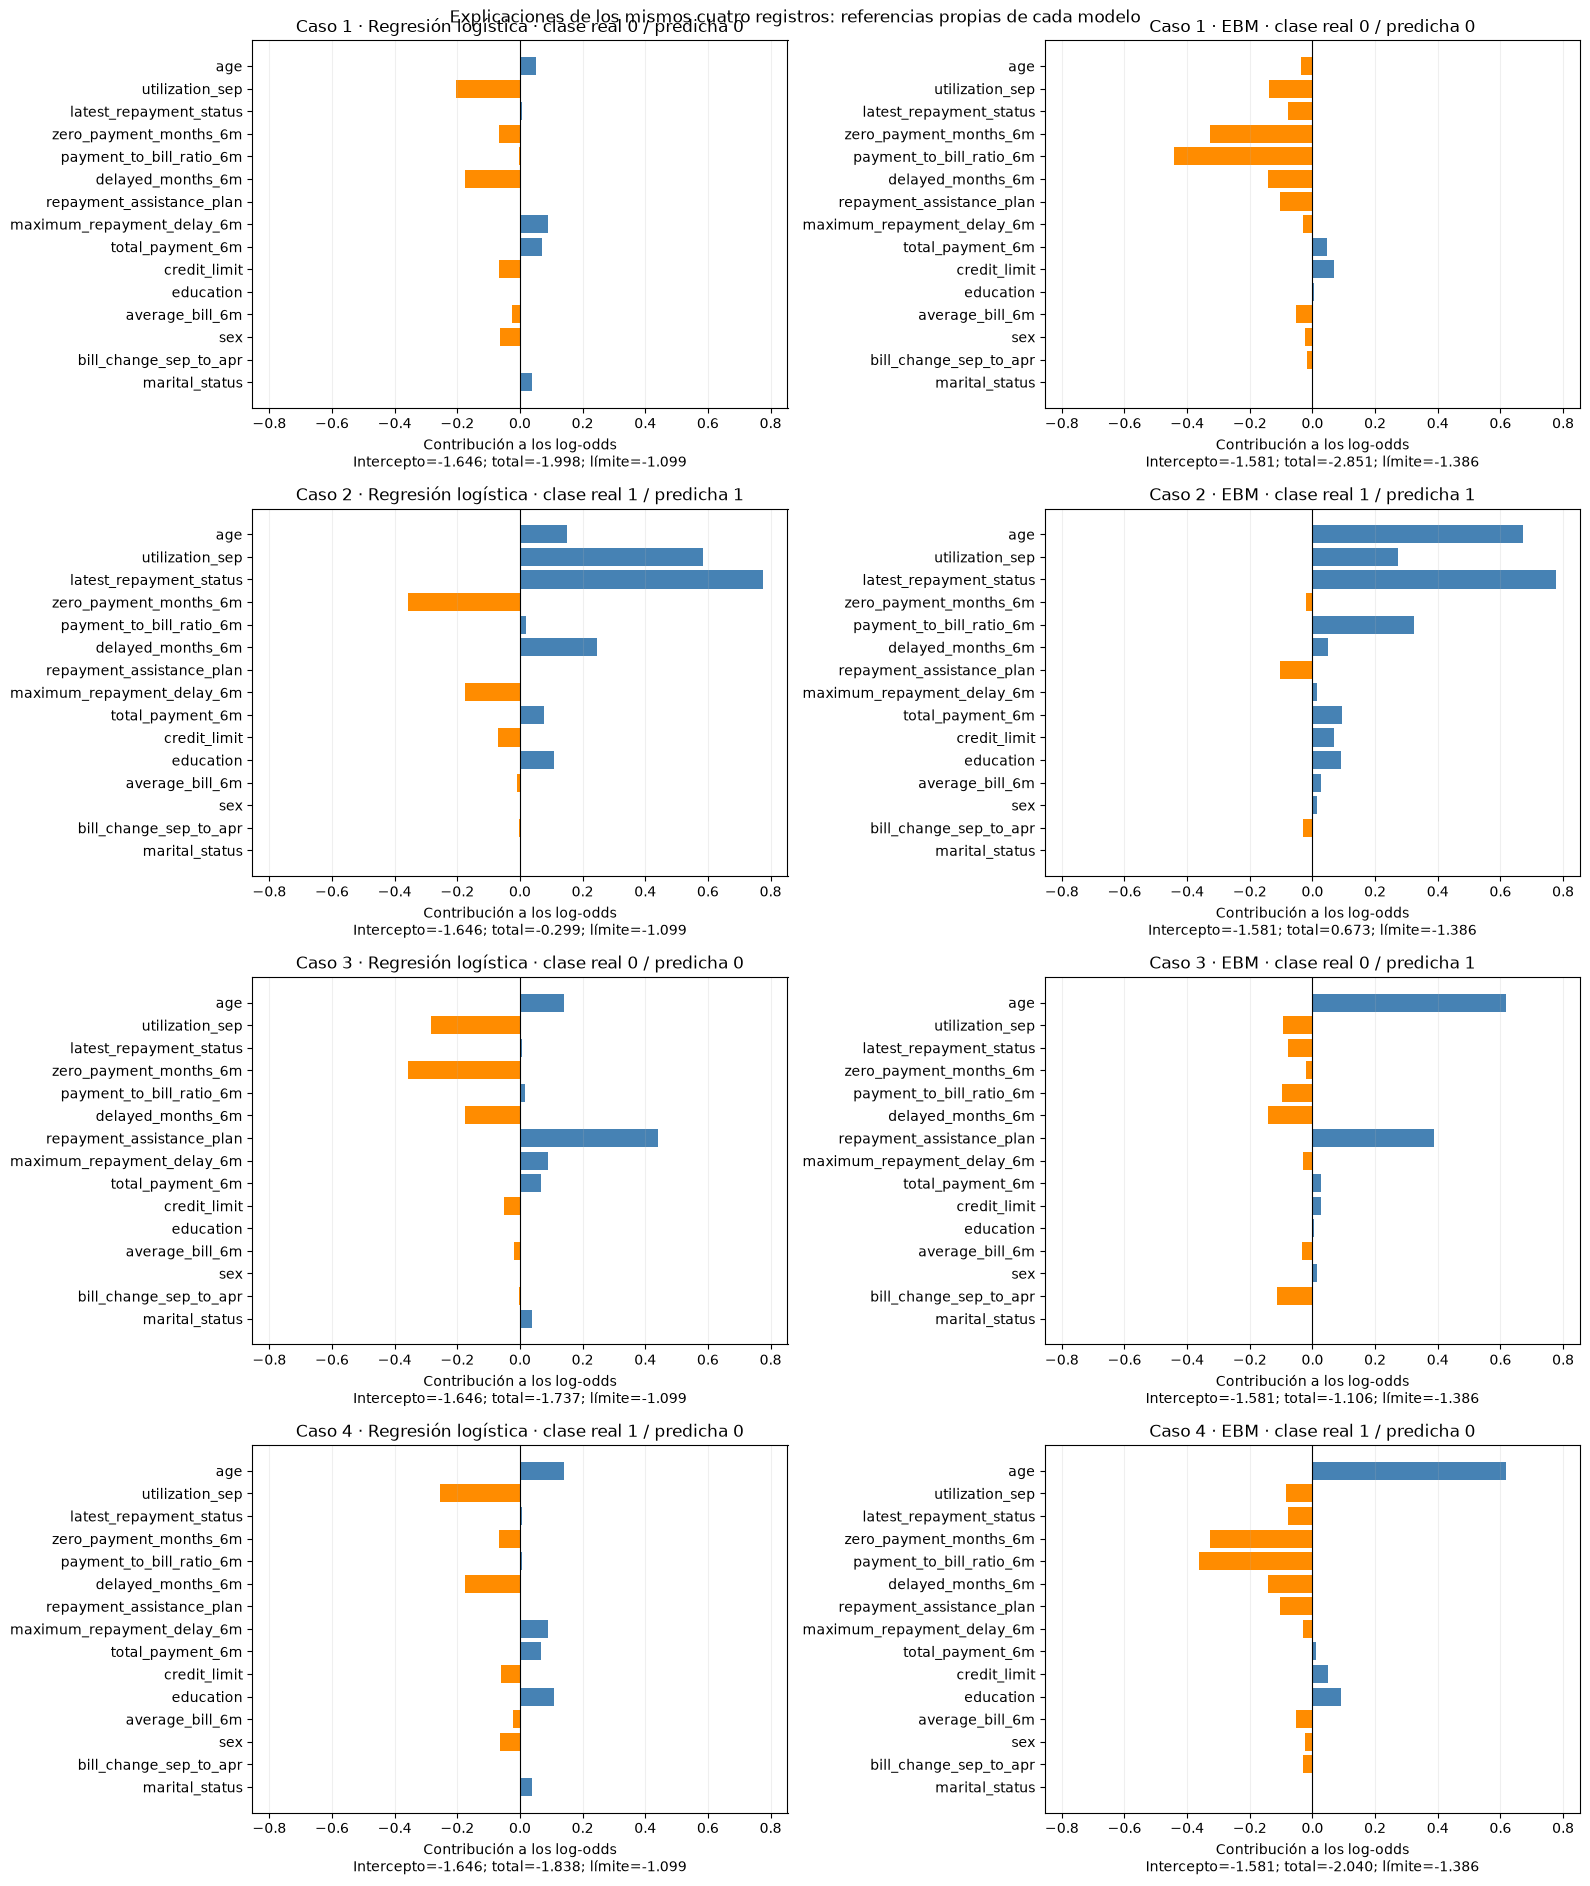

In [50]:
local_variable_order = (
    local_logistic_contributions.abs().mean() + local_ebm_contributions.abs().mean()
).sort_values().index
maximum_contribution = max(
    np.abs(data["contributions"].to_numpy()).max() for data in local_additive_models.values()
)
plot_limit = max(maximum_contribution * 1.1, 0.1)
fig, axes = plt.subplots(len(local_cases), 2, figsize=(16, 4.8 * len(local_cases)), squeeze=False)
for row_idx, (index, case) in enumerate(local_cases.iterrows()):
    for column_idx, (name, data) in enumerate(local_additive_models.items()):
        ax = axes[row_idx, column_idx]
        contributions = data["contributions"].loc[index, local_variable_order]
        colors = ["steelblue" if value > 0 else "darkorange" if value < 0 else "gray" for value in contributions]
        ax.barh(contributions.index, contributions.values, color=colors)
        ax.axvline(0, color="black", linewidth=0.8)
        ax.set_xlim(-plot_limit, plot_limit)
        total = data["intercept"] + contributions.sum()
        threshold_logit = float(logit(local_thresholds[name]))
        prediction = int(total >= threshold_logit)
        ax.set_title(f"{case['Caso']} · {name} · clase real {int(case['true_class'])} / predicha {prediction}")
        ax.set_xlabel(
            "Contribución a los log-odds\n"
            f"Intercepto={data['intercept']:.3f}; total={total:.3f}; límite={threshold_logit:.3f}"
        )
        ax.grid(axis="x", alpha=0.2)
fig.suptitle("Explicaciones de los mismos cuatro registros: referencias propias de cada modelo")
plt.tight_layout()
plt.show()

### <a id="sec-8-6"></a> 8.6. Vistas locales de InterpretML

Se muestran también las explicaciones locales interactivas de logística y EBM. El selector de instancias utiliza el orden de los casos 1–4 y permite explorar sus contribuciones. En logística, la vista presenta columnas transformadas, mientras que las barras anteriores agrupan las one-hot por variable original; la suma total se conserva.

Se reutiliza la reproducción logística de la partición 1 ya validada en 7.8 y se comprueba su coincidencia en estos registros. EBM explica directamente su modelo guardado. No se ajusta ningún modelo nuevo. La posibilidad de explicar un error describe por qué el modelo lo comete; no demuestra que la explicación justifique la decisión ni que revele la causa real del resultado.

**Lectura de los encabezados interactivos.** InterpretML utiliza su decisión predeterminada, equivalente aquí al umbral 0,5; estas vistas no incorporan los umbrales internos del proyecto. Por eso EBM muestra clase predicha 0 en los casos 2 y 3, aunque sus decisiones internas sean 1. En la vista logística, los valores «Actual» y «Predicted» del encabezado son las probabilidades asignadas a la clase real y a la clase predicha por la biblioteca, respectivamente; no son las etiquetas 0 y 1. Para consultar las etiquetas y decisiones del proyecto debe utilizarse la tabla de 10.2. Las barras siguen explicando el cálculo del modelo: cambiar el umbral no cambia esas contribuciones.


In [51]:
if LOCAL_FOLD != LR_REFERENCE_FOLD:
    raise ValueError("La vista logística disponible corresponde a otra partición; debe prepararse su reproducción correspondiente.")
if not np.allclose(
    lr_explainer.predict_proba(local_lr_input)[:, 1], local_probabilities["Regresión logística"],
    rtol=1e-6, atol=1e-8,
):
    raise ValueError("La reproducción de InterpretML no coincide con el modelo logístico de estos casos.")
local_case_selector = local_cases[["Caso", ID_COLUMN, "true_class"]].reset_index(drop=True)
print("Orden de instancias en las vistas interactivas:")
display(local_case_selector)
lr_local_explanation = lr_explainer.explain_local(
    local_lr_input, local_y.to_numpy(), name="Logística: cuatro casos externos comunes"
)
ebm_local_explanation = local_ebm_model.explain_local(
    local_ebm_input, local_y.to_numpy(), name="EBM: cuatro casos externos comunes"
)
show(lr_local_explanation, 0)
show(ebm_local_explanation, 0)

Orden de instancias en las vistas interactivas:


,Caso,row_id,true_class
0,Caso 1,CR26-100008,0
1,Caso 2,CR26-100025,1
2,Caso 3,CR26-100040,0
3,Caso 4,CR26-100209,1


### <a id="sec-8-7"></a> 8.7. Alcance y revisión de las explicaciones locales

**Caso 1: acuerdo correcto en clase 0.** El árbol asigna una probabilidad de 0,0720 mediante la regla de estado reciente ≤ 0,5, proporción de pagos > 0,105 y meses sin pago ≤ 2,5. En logística destacan las contribuciones negativas del estado reciente (−0,374), los meses sin pago (−0,369) y el total pagado (−0,308). En EBM predominan las de la proporción de pagos (−0,426) y el estado reciente (−0,295), que compensan, entre otras, la contribución positiva del cambio de saldo (+0,265). Logística y EBM obtienen probabilidades de 0,0444 y 0,0582. Coinciden en la decisión, aunque difiere el peso asignado a cada variable.

**Caso 2: acuerdo correcto en clase 1 gracias al umbral interno.** El árbol combina estado reciente > 0,5, proporción de pagos ≤ 0,105 y meses sin pago ≤ 2,5, con probabilidad 0,4646. En logística aumentan los log-odds la utilización del crédito (+0,434), los meses con retraso (+0,415) y el estado reciente (+0,391). En EBM destacan la proporción de pagos (+0,311), el estado reciente (+0,262) y los meses con retraso (+0,196). Los dos meses sin pago aportan positivamente en logística (+0,229) y negativamente en EBM (−0,236), respecto a las referencias de cada modelo. Esta diferencia ilustra que el acuerdo final puede coexistir con explicaciones distintas. Las probabilidades logística y EBM son 0,3997 y 0,2663: los tres modelos aciertan con sus umbrales internos y fallarían con 0,5.

**Caso 3: discrepancia y falso positivo de EBM.** El árbol asigna 0,1920 y logística 0,1832, ambos por debajo de 0,25. En logística, la contribución positiva de la utilización (+0,472) queda parcialmente compensada por los meses sin pago (−0,369) y los meses con retraso (−0,158). EBM asigna 0,2110: destacan las aportaciones positivas de la proporción de pagos (+0,352), el cambio de saldo (+0,289) y la utilización (+0,206). Su probabilidad supera en apenas 0,0110 el umbral 0,20. La discrepancia depende tanto de las funciones aprendidas como de los distintos umbrales. Este caso no motiva cambiar el umbral después de observar su etiqueta ni contradice el mejor rendimiento agregado de EBM.

**Caso 4: falso negativo compartido.** Los cinco meses sin pago aumentan los log-odds en logística (+1,128) y EBM (+0,767). Sin embargo, otras contribuciones y el intercepto mantienen las probabilidades en 0,1539 y 0,1364, por debajo de sus umbrales. En logística compensan especialmente el estado reciente (−0,756) y la utilización (−0,400); en EBM, la proporción de pagos (−0,469) y el estado reciente (−0,306). El árbol llega a una hoja con probabilidad 0,1208 pese a seguir la rama de más de 2,5 meses sin pago. Una variable con contribución positiva elevada no determina por sí sola la decisión. Los saldos nulos y la proporción de pagos registrada deben leerse conforme a su definición, sin inferir una causa del resultado ni modificar sus valores por el error observado.

Las comprobaciones confirman que los recorridos y las sumas explican fielmente las probabilidades de los modelos guardados. Esto permite entender también sus errores, pero no demuestra que sus decisiones estén justificadas ni que las asociaciones aprendidas sean causales. Un falso negativo compartido tampoco prueba un error en la etiqueta.

Los cuatro ejemplos no sustituyen la evaluación de los 25.000 registros del apartado 7 ni permiten estimar la frecuencia de estas situaciones. No se ajustan modelos ni umbrales a partir de ellos. La discusión conjunta de coincidencias, discrepancias y limitaciones se desarrollará en el apartado 9.

[Volver al índice](#indice)


## <a id="sec-9"></a> 9. Discusión de las explicaciones

### <a id="sec-9-1"></a> 9.1. Qué aporta cada forma de explicación

Los tres modelos permiten inspeccionar directamente el cálculo aprendido, pero requieren lecturas diferentes. El árbol resume la predicción en un recorrido de hasta tres condiciones y una frecuencia de hoja; logística combina coeficientes con las entradas transformadas; EBM suma quince funciones univariantes. En el apartado 8 se verificó que los recorridos y las contribuciones reconstruyen las probabilidades de los casos comunes.

Esa fidelidad al cálculo no garantiza facilidad de comprensión. Las ocho reglas del árbol pueden leerse completas, aunque agrupan perfiles distintos bajo la misma probabilidad. Logística ofrece una ecuación compacta, pero exige conocer el escalado, las categorías de referencia y el significado de las odds. EBM hace visibles saltos y cambios de dirección, a costa de revisar más funciones e intervalos. La utilidad de cada explicación depende de la pregunta: seguir una decisión concreta, resumir asociaciones o estudiar la forma de una relación.

[Volver al índice](#indice)


### <a id="sec-9-2"></a> 9.2. Coincidencias y variables relevantes

El comportamiento de pago constituye un núcleo compartido, aunque su relevancia se expresa de forma distinta en cada representación:

| Variable o grupo | Evidencia comparada | Lectura y límite |
| --- | --- | --- |
| Estado reciente de devolución | Aparece en la raíz de los cinco árboles, mantiene coeficiente positivo en logística y contribución elevada en EBM. | Es una señal compartida; los códigos no positivos tienen documentación incompleta y no deben traducirse en categorías inventadas. |
| Cociente entre pagos y facturas | Divide el segundo nivel de los árboles y tiene la mayor media absoluta de contribución en los cinco EBM. | EBM revela una relación no monótona que un único coeficiente logístico no representa. |
| Meses sin pago y meses con retraso | Destacan en logística y EBM; los meses sin pago también intervienen en el árbol de referencia. | Los resúmenes relacionados comparten información; no identifican factores independientes. |
| Plan de asistencia | Mantiene asociación positiva en logística y EBM. | Su ausencia en las reglas del árbol de referencia no demuestra irrelevancia. Su asociación no identifica el efecto de recibir asistencia. |

No se equiparan las importancias por impureza, los coeficientes estandarizados y las medias absolutas de contribución: responden a preguntas diferentes. Tampoco una variable globalmente destacada tiene que dominar todos los casos; en el caso 1, por ejemplo, logística destaca el estado reciente y los meses sin pago, mientras que EBM da mayor magnitud a la contribución del cociente entre pagos y facturas.

[Volver al índice](#indice)


### <a id="sec-9-3"></a> 9.3. Discrepancias entre explicaciones y decisiones

Las diferencias no se limitan al orden de las variables. Logística impone linealidad en los log-odds para cada numérica; EBM permite formas no lineales sin interacciones explícitas; el árbol utiliza condiciones conjuntas y probabilidades constantes por hoja. Estas restricciones pueden producir explicaciones distintas aun utilizando los mismos datos.

El caso 2 muestra acuerdo en la decisión con discrepancia en las contribuciones: dos meses sin pago aportan positivamente en logística y negativamente en EBM, respecto a sus propias referencias. Un signo local distinto no constituye una contradicción lógica entre modelos ni prueba que uno de ellos esté mal implementado. Además, los tres aciertan gracias a sus umbrales internos: explicar la probabilidad exige revisar el modelo, y explicar la etiqueta exige considerar también el umbral.

En el caso 3, EBM supera por poco su umbral y produce un falso positivo, mientras que árbol y logística aciertan. Su mejor rendimiento medio no garantiza mejores decisiones en todos los registros. En el caso 4, los tres producen un falso negativo pese a que los meses sin pago elevan las contribuciones de los modelos aditivos. La suma completa y el intercepto compensan esa señal. El acuerdo tampoco certifica el acierto: en el conjunto OOF se observaron 3.833 errores compartidos con los umbrales internos.

[Volver al índice](#indice)


### <a id="sec-9-4"></a> 9.4. Estabilidad y dependencia entre variables

Los cinco árboles conservan las divisiones de sus dos primeros niveles, pero cambian algunas condiciones terminales. En logística, los signos activos son estables en los ajustes observados, mientras varían la magnitud de los coeficientes y la selección de algunas categorías. EBM repite varias formas principales, con mayores discrepancias en estados de retraso altos y otras regiones con pocos datos. La estabilidad de las métricas no garantiza estabilidad de las explicaciones.

La correlación entre el retraso máximo y los meses con retraso dificulta separar sus asociaciones. Así debe leerse el coeficiente logístico negativo del retraso máximo: es una asociación condicional en presencia de las demás entradas, no evidencia de que retrasarse más reduzca la dificultad. La regularización puede repartir o anular coeficientes entre predictores relacionados; EBM también puede repartir información entre sus funciones. La ausencia de interacciones explícitas no elimina esa dependencia en los datos.

La repetición entre cinco entrenamientos aporta evidencia descriptiva dentro de este ejercicio. Como los entrenamientos se solapan y sus configuraciones pueden variar, no representa cinco réplicas independientes ni un intervalo de confianza sobre la explicación poblacional.

[Volver al índice](#indice)


### <a id="sec-9-5"></a> 9.5. Asociaciones aprendidas y límites causales

La asociación positiva del plan de asistencia no permite concluir que recibir ayuda cause dificultad. Puede reflejar que el plan se asigna a registros con mayor riesgo previo; con este análisis no se identifica el mecanismo de asignación ni el efecto de una intervención.

Del mismo modo, una contribución negativa no justifica recomendar un cambio de conducta. Consultar una función de EBM o variar una entrada de la ecuación logística manteniendo las demás constantes describe una respuesta matemática del modelo. No demuestra qué ocurriría al intervenir sobre una persona. Además, cambiar aisladamente un resumen derivado de pagos o facturas puede producir un perfil incoherente con las otras variables.

Las explicaciones describen asociaciones aprendidas en un conjunto semisintético. No se ha demostrado calibración, equidad entre grupos ni validez en otra población o periodo. La baja contribución de una variable demográfica tampoco acredita ausencia de sesgo: otras entradas pueden contener información relacionada y aquí no se han evaluado errores por grupo.

[Volver al índice](#indice)


### <a id="sec-9-6"></a> 9.6. Balance de la discusión y posibles mejoras

EBM obtiene la mejor discriminación observada y permite estudiar relaciones no monótonas; el árbol ofrece la estructura completa más breve para seguir decisiones; logística facilita contrastes explícitos mediante coeficientes y odds ratios. Ninguna representación elimina las dificultades de interpretación de variables correlacionadas, las referencias de las contribuciones o la posibilidad de errores compartidos. Por ello, el rendimiento y la claridad de las explicaciones deben valorarse conjuntamente, como requiere el objetivo del proyecto.

Una ampliación razonable sería aclarar los códigos de pago y las fórmulas de los resúmenes, examinar el respaldo de datos en los extremos y comprobar la estabilidad de las explicaciones bajo otras particiones. También podrían estudiarse calibración y errores por grupo si se quisiera evaluar otros usos del modelo. Son líneas futuras, no resultados obtenidos en este trabajo; cualquier cambio de variables, restricciones o configuración requeriría una nueva evaluación dentro del protocolo establecido.

Los cuatro casos locales ilustran mecanismos y discrepancias, pero fueron seleccionados por sus escenarios y no permiten estimar su frecuencia. Esta discusión integra las evidencias globales y locales sin reajustar los modelos ni sus umbrales. La justificación de la familia elegida y su entrenamiento final se desarrollan en el [apartado 10](#sec-10).

[Volver al índice](#indice)


## <a id="sec-10"></a> 10. Selección y entrenamiento final

### <a id="sec-10-1"></a> 10.1. Justificación de la familia seleccionada

Se selecciona **Explainable Boosting Machine con `interactions=0`**. En la evaluación externa obtiene la mayor ROC-AUC media (0,7755, frente a 0,7515 de logística y 0,7372 del árbol), y supera a ambas familias en las cinco particiones. Con los umbrales internos también presenta las mayores medias de sensibilidad, exactitud equilibrada y F1.

La elección incorpora la explicabilidad: sus quince funciones permiten revisar las asociaciones no lineales y reconstruir las predicciones individuales por suma de contribuciones. El árbol tiene una estructura más breve y logística facilita contrastes mediante odds ratios, pero EBM ofrece un equilibrio adecuado entre discriminación y detalle de las relaciones aprendidas para este proyecto. No se afirma que sea siempre más interpretable ni que sus asociaciones sean causales.

Se mantiene el criterio previamente definido para el umbral: maximizar la exactitud equilibrada en validación cruzada. Esto favorece la detección de positivos a costa de más falsas alertas y menor exactitud total; con los umbrales internos, la exactitud externa quedó por debajo de la referencia mayoritaria. La exactitud forma parte de la evaluación de la entrega, pero no se cambia ahora el criterio para favorecerla retrospectivamente.

La configuración final no se elige por votación entre los cinco ajustes ni se reutiliza el modelo de referencia de la partición 1. Se repite el procedimiento de selección sobre todos los datos etiquetados. El test permanece al margen de estas decisiones.


### <a id="sec-10-2"></a> 10.2. Selección de la configuración con todos los datos etiquetados

Se conservan los parámetros fijos, las cuatro combinaciones de `max_bins` y `min_samples_leaf`, y las cinco particiones estratificadas por grupos de perfiles idénticos. Cada transformación se ajusta dentro de su entrenamiento. Se selecciona la mayor ROC-AUC media; en caso de empate se prefieren menos bins y un mayor mínimo de registros por hoja, como en el apartado 6.

La búsqueda requiere **20 ajustes**. Después se realizarán cinco ajustes para obtener probabilidades OOF de la configuración elegida y un ajuste final: **26 en total**. Se utiliza `refit=False` para evitar un ajuste adicional automático.


In [52]:
final_ready = False
final_pipeline = None
final_threshold = None
final_family = "EBM"
final_start = perf_counter()
final_positions = np.arange(len(y))
final_cv_splits = make_inner_splits(final_positions)
final_coverage = np.zeros(len(y), dtype=int)
for _, valid_idx in final_cv_splits:
    final_coverage[valid_idx] += 1
if not np.all(final_coverage == 1):
    raise ValueError("Cada registro debe recibir una única predicción OOF final.")
if PRIMARY_METRIC != "roc_auc" or THRESHOLD_METRIC != "balanced_accuracy":
    raise ValueError("Los criterios difieren de los definidos para este procedimiento.")

final_search = GridSearchCV(
    clone(ebm_base_pipeline), EBM_PARAM_GRID, cv=final_cv_splits,
    scoring=SCORING, refit=False, n_jobs=N_JOBS, error_score="raise",
)
print("Búsqueda final EBM: cuatro configuraciones × cinco particiones (20 ajustes).", flush=True)
final_search.fit(X_raw, y)
final_search_table = pd.DataFrame(final_search.cv_results_).sort_values(
    ["mean_test_roc_auc", "param_model__max_bins", "param_model__min_samples_leaf"],
    ascending=[False, True, False],
).reset_index(drop=True)
final_best_params = dict(final_search_table.iloc[0]["params"])
final_candidate_pipeline = clone(ebm_base_pipeline).set_params(**final_best_params)
display(final_search_table[[
    "param_model__max_bins", "param_model__min_samples_leaf",
    "mean_test_roc_auc", "std_test_roc_auc",
]].rename(columns={
    "param_model__max_bins": "max_bins",
    "param_model__min_samples_leaf": "min_samples_leaf",
    "mean_test_roc_auc": "ROC-AUC media de selección",
    "std_test_roc_auc": "DT de selección (ddof=0)",
}).round(4))
print("Configuración seleccionada:", final_best_params)
print(f"Búsqueda completada en {(perf_counter() - final_start) / 60:.1f} min.", flush=True)


Búsqueda final EBM: cuatro configuraciones × cinco particiones (20 ajustes).


,max_bins,min_samples_leaf,ROC-AUC media de selección,DT de selección (ddof=0)
0,32,10,0.7753,0.0068
1,32,50,0.7753,0.0068
2,16,10,0.7741,0.0068
3,16,50,0.7741,0.0068


Configuración seleccionada: {'model__max_bins': 32, 'model__min_samples_leaf': 10}
Búsqueda completada en 0.5 min.


**Resultado de la búsqueda.** Se seleccionan `max_bins=32` y `min_samples_leaf=10`, con ROC-AUC media de selección 0,7755. Es la combinación elegida en cuatro de las cinco búsquedas externas. La alternativa con 32 bins y mínimo de 50 registros obtiene 0,7754: la diferencia es muy pequeña y no demuestra una superioridad concluyente entre ambas configuraciones. Se conserva la ganadora conforme al criterio fijado, sin ampliar la búsqueda tras observar los resultados.


### <a id="sec-10-3"></a> 10.3. Selección del umbral con probabilidades OOF

Se generan probabilidades OOF de la configuración seleccionada: cada registro se predice mediante un ajuste que no lo utilizó ni incluyó su perfil idéntico en el entrenamiento. Se aplica la misma cuadrícula de umbrales y la misma función de selección del apartado 3. En caso de empate, se prefiere el umbral más próximo a 0,5 y después el menor.

La tabla compara las métricas por partición con 0,5 y con el umbral elegido. **Estos resultados sirven para seleccionar, no son una nueva evaluación externa**: la configuración y el umbral utilizan las etiquetas de estas validaciones. Aunque las probabilidades se calculen fuera del entrenamiento de cada ajuste, la selección puede introducir optimismo. La comparación de referencia sigue siendo la validación anidada del apartado 7, con la cautela adicional de haber elegido la familia a partir de ella.


In [53]:
print("Generación de probabilidades OOF para el umbral (cinco ajustes).", flush=True)
final_oof_probability = cross_val_predict(
    final_candidate_pipeline, X_raw, y, cv=final_cv_splits,
    method="predict_proba", n_jobs=N_JOBS,
)[:, 1]
if not np.isfinite(final_oof_probability).all() or not (
    (final_oof_probability >= 0) & (final_oof_probability <= 1)
).all():
    raise ValueError("Las probabilidades OOF finales no son válidas.")
final_threshold, final_threshold_table = choose_threshold(
    y, final_oof_probability, final_cv_splits
)
display(final_threshold_table.reset_index(drop=True).round(4))

final_selection_scores = {}
for label, threshold in [("0,5", DEFAULT_THRESHOLD), ("Seleccionado", final_threshold)]:
    final_selection_scores[label] = pd.DataFrame([
        metric_scores(y.iloc[valid_idx], final_oof_probability[valid_idx], threshold)
        for _, valid_idx in final_cv_splits
    ], index=pd.Index(range(1, N_SPLITS + 1), name="Partición"))
final_selection_summary = pd.concat({
    label: scores.agg(["mean", "std"]).T.rename(columns={"mean": "Media", "std": "DT muestral"})
    for label, scores in final_selection_scores.items()
}, axis=1)
display(final_selection_summary.round(4))
print(f"Umbral final por exactitud equilibrada: {final_threshold:.2f}")
print("Métricas de selección; no constituyen una evaluación externa adicional.")


Generación de probabilidades OOF para el umbral (cinco ajustes).


,Umbral,Exactitud equilibrada interna,Desviación típica,"Distancia a 0,5"
0,0.20,0.7016,0.0049,0.30
1,0.25,0.7001,0.0097,0.25
2,0.30,0.6880,0.0113,0.20
3,0.15,0.6874,0.0087,0.35
4,0.35,0.6733,0.0076,0.15
5,0.40,0.6585,0.0076,0.10
6,0.45,0.6437,0.0064,0.05
7,0.10,0.6405,0.0059,0.40
8,0.50,0.6289,0.0046,0.00
9,0.55,0.6125,0.0057,0.05


0,5             Seleccionado            
                    Media DT muestral        Media DT muestral
roc_auc            0.7753      0.0076       0.7753      0.0076
accuracy           0.8182      0.0016       0.7146      0.0022
balanced_accuracy  0.6289      0.0046       0.7016      0.0049
recall             0.3000      0.0116       0.6790      0.0112
precision          0.6570      0.0124       0.3985      0.0034
f1                 0.4117      0.0099       0.5023      0.0054

Umbral final por exactitud equilibrada: 0.20
Métricas de selección; no constituyen una evaluación externa adicional.


**Resultado del ajuste del umbral.** Se selecciona **0,20**, con exactitud equilibrada media 0,7007. El umbral 0,25 obtiene 0,7005; ambos resultados son próximos y no permiten afirmar una preferencia robusta por 0,20. No hay empate en la puntuación obtenida y se mantiene la regla de maximizarla, sin introducir ahora otro criterio.

Frente a 0,5, el umbral elegido aumenta la sensibilidad de 0,2983 a 0,6793 y F1 de 0,4099 a 0,5011. A cambio, la exactitud baja de 0,8178 a 0,7131 y la precisión de 0,6556 a 0,3970. Por tanto, se detectan más positivos, pero aumentan las falsas alertas: en estas validaciones, menos de cuatro de cada diez predicciones positivas son correctas. La ROC-AUC permanece en 0,7755 porque las probabilidades y su orden no cambian al aplicar otro umbral.

Estas cifras corresponden a la selección de la configuración y de un umbral común sobre los datos etiquetados; no deben sustituir las métricas externas del apartado 7 ni atribuirse al test. En particular, la exactitud equilibrada 0,7007 no se presenta como una mejora externa demostrada respecto a 0,6997.


### <a id="sec-10-4"></a> 10.4. Ajuste final y comprobación de la estructura

Una vez fijadas la configuración y la regla de decisión, se crea un pipeline nuevo y se ajusta con **todos los registros etiquetados**. Se mantienen la semilla, el preprocesamiento y el mecanismo de bagging y parada temprana definido para EBM. Las divisiones internas de ese mecanismo no constituyen una evaluación externa nueva.

Se comprueban el orden de las clases, la presencia de una función por variable y la ausencia de interacciones. El pipeline entrenado queda en `final_pipeline`, el umbral en `final_threshold` y el indicador `final_ready` confirma que terminó el ajuste. No se calculan métricas de entrenamiento para sustituir las métricas externas ni se generan todavía predicciones del test.


In [54]:
final_ready = False
final_fit_start = perf_counter()
final_pipeline = clone(final_candidate_pipeline)
print(f"Ajuste final con {len(y):,} registros etiquetados y {len(feature_columns)} variables.", flush=True)
final_pipeline.fit(X_raw, y)
final_estimator = final_pipeline["model"]
if not np.array_equal(final_estimator.classes_, [0, 1]):
    raise ValueError("El orden de clases del modelo final debe ser [0, 1].")
if final_estimator.interactions != 0 or any(
    len(term) != 1 for term in final_estimator.term_features_
):
    raise ValueError("El modelo final debe ser aditivo y no contener interacciones.")
if (
    len(final_estimator.term_names_) != len(feature_columns)
    or set(final_estimator.term_names_) != set(feature_columns)
):
    raise ValueError("Se esperaba un término por cada variable original.")
final_model_summary = pd.DataFrame([{
    "Familia": final_family,
    "Registros etiquetados": len(y),
    "Variables originales": len(feature_columns),
    "max_bins": final_estimator.max_bins,
    "min_samples_leaf": final_estimator.min_samples_leaf,
    "interactions": final_estimator.interactions,
    "Funciones univariantes": len(final_estimator.term_names_),
    "Umbral": final_threshold,
    "Semilla": SEED,
}])
display(final_model_summary)
final_term_importance = pd.DataFrame({
    "Variable": final_estimator.term_names_,
    "Media absoluta de contribución (entrenamiento final)": final_estimator.term_importances(),
}).sort_values("Media absoluta de contribución (entrenamiento final)", ascending=False)
display(final_term_importance.round(4).reset_index(drop=True))
final_ready = True
print(f"Ajuste final completado en {(perf_counter() - final_fit_start) / 60:.1f} min.")
print("Pipeline y umbral preparados para el apartado 13.")


Ajuste final con 25,000 registros etiquetados y 15 variables.


,Familia,Registros etiquetados,Variables originales,max_bins,min_samples_leaf,interactions,Funciones univariantes,Umbral,Semilla
0,EBM,25000,15,32,10,0,15,0.2,42


,Variable,Media absoluta de contribución (entrenamiento final)
0,payment_to_bill_ratio_6m,0.3194
1,latest_repayment_status,0.2410
2,zero_payment_months_6m,0.2095
3,delayed_months_6m,0.1977
4,repayment_assistance_plan,0.1662
5,age,0.1645
6,utilization_sep,0.1242
7,total_payment_6m,0.0922
8,bill_change_sep_to_apr,0.0879
9,average_bill_6m,0.0738


Ajuste final completado en 0.0 min.
Pipeline y umbral preparados para el apartado 13.


### <a id="sec-10-5"></a> 10.5. Revisión del modelo final y alcance de los resultados

La tabla anterior resume la magnitud global de las contribuciones del **ajuste final**, no las medias de los cinco modelos externos. El núcleo de variables coincide con el discutido en los apartados 6 y 9: destacan el cociente entre pagos y facturas (0,3195), el estado reciente de devolución (0,2411), los meses sin pago (0,2096) y los meses con retraso (0,1977). Les siguen el plan de asistencia (0,1662) y la edad (0,1645). Esta coincidencia respalda la continuidad del patrón global observado en los ajustes externos, sin constituir una comprobación de estabilidad en nuevos datos.

El estado civil (0,0057), el sexo (0,0197) y la educación (0,0347) presentan las menores magnitudes globales en este ajuste. Las magnitudes no indican dirección, efectos independientes ni ausencia de relevancia en un caso concreto. Tampoco la baja magnitud de variables demográficas acredita equidad del modelo.

La siguiente vista permite consultar sus funciones directamente. Su centrado, intervalos y contribuciones corresponden al entrenamiento final y pueden diferir de los del modelo de referencia. Las explicaciones locales del apartado 8 conservan su valor como análisis de casos fuera del entrenamiento de sus respectivos modelos; no se presentan como explicaciones de este ajuste final, que ya ha utilizado todos los registros etiquetados.


In [55]:
if not final_ready:
    raise RuntimeError("Debe completarse el entrenamiento final antes de explicarlo.")
final_global_explanation = final_estimator.explain_global(name="EBM final: todos los datos etiquetados")
show(final_global_explanation)


El ajuste final ha terminado correctamente con 25.000 registros etiquetados, 15 funciones univariantes, `max_bins=32`, `min_samples_leaf=10`, `interactions=0`, semilla 42 y umbral 0,20. Las comprobaciones de estructura se han superado. La tabla permite discutir la magnitud global de las contribuciones; esa magnitud, por sí sola, no confirma las formas ni los signos de las funciones del ajuste final.

El entrenamiento con todos los datos no aporta una estimación independiente del rendimiento. El test sin etiquetas se utilizará únicamente para la predicción y exportación del [apartado 11](#sec-11), conservando el pipeline y el umbral seleccionados.

[Volver al índice](#indice)


## <a id="sec-11"></a> 11. Predicción y exportación del test

### <a id="sec-11-1"></a> 11.1. Comprobación de las entradas y del modelo final

Se utiliza exclusivamente el pipeline entrenado en el apartado 10 y su umbral seleccionado mediante validación cruzada. No se vuelve a ajustar el modelo, el preprocesamiento ni el umbral con el test.

Se comprueba que el test conserva los datos originales, no contiene etiquetas ni predicciones previas y dispone de las variables esperadas. Para predecir se ordenan los predictores como en el entrenamiento; la tabla de entrega conserva su orden original de filas y columnas.


In [56]:
if not globals().get("final_ready", False):
    raise RuntimeError("Ejecuta el entrenamiento final del apartado 12 antes de predecir.")
if final_pipeline is None or final_threshold is None or not 0 < final_threshold < 1:
    raise ValueError("Falta el pipeline final o su umbral no es válido.")
if not np.array_equal(final_pipeline["model"].classes_, [0, 1]):
    raise ValueError("Se esperaba el orden de clases [0, 1].")
if TARGET in test_raw.columns or PREDICTION_COLUMN in test_raw.columns:
    raise ValueError("El test de entrada debe ser el original, sin etiquetas ni predicciones.")
if set(test_raw.columns) != {ID_COLUMN, *feature_columns}:
    raise ValueError("Las columnas del test no coinciden con las esperadas.")
if test_raw[ID_COLUMN].isna().any() or test_raw[ID_COLUMN].duplicated().any():
    raise ValueError("Los identificadores del test deben estar informados y ser únicos.")

test_source_path = (data_dir / "test.csv").resolve()
test_source_check = pd.read_csv(test_source_path, dtype={ID_COLUMN: "string"})
pd.testing.assert_frame_equal(test_raw, test_source_check, check_exact=True)
pd.testing.assert_series_equal(test_raw[ID_COLUMN], test_row_ids, check_exact=True)
export_test_features = test_raw.loc[:, feature_columns].copy()
print(f"Test original verificado: {len(test_raw):,} filas y {test_raw.shape[1]} columnas.")
print(f"Modelo final: {type(final_pipeline['model']).__name__}; umbral: {final_threshold:.2f}.")


Test original verificado: 5,000 filas y 16 columnas.
Modelo final: ExplainableBoostingClassifier; umbral: 0.20.


### <a id="sec-11-2"></a> 11.2. Predicciones y distribución de las etiquetas

Se obtiene la probabilidad de la clase 1 mediante `predict_proba` y se asigna `predicted_class=1` cuando esa probabilidad es mayor o igual que el umbral final. No se utiliza `predict`, ya que aplicaría la regla predeterminada del estimador.

La copia de entrega añade **únicamente `predicted_class`, como última columna**, con enteros 0 o 1. Las probabilidades se conservan en memoria para inspección, pero no se añaden al CSV. La distribución resultante describe las decisiones del modelo: no estima la tasa real de dificultad ni permite calcular exactitud, sensibilidad u otras métricas sin etiquetas.


In [57]:
test_final_probabilities = final_pipeline.predict_proba(export_test_features)
if test_final_probabilities.shape != (len(test_raw), 2):
    raise ValueError("El número de probabilidades no coincide con las filas o las clases.")
if not np.isfinite(test_final_probabilities).all() or not (
    (test_final_probabilities >= 0) & (test_final_probabilities <= 1)
).all():
    raise ValueError("Las probabilidades del test no son válidas.")
if not np.allclose(test_final_probabilities.sum(axis=1), 1):
    raise ValueError("Las probabilidades por registro no suman 1.")
test_final_probability = test_final_probabilities[:, 1]
test_final_prediction = (test_final_probability >= final_threshold).astype(int)
submission_test = test_raw.copy(deep=True)
submission_test[PREDICTION_COLUMN] = test_final_prediction
expected_submission_columns = [*test_raw.columns, PREDICTION_COLUMN]
if list(submission_test.columns) != expected_submission_columns:
    raise ValueError("El orden de las columnas de entrega no es el esperado.")
if submission_test[PREDICTION_COLUMN].isna().any() or not submission_test[PREDICTION_COLUMN].isin([0, 1]).all():
    raise ValueError("Todas las predicciones deben ser 0 o 1, sin ausentes.")
pd.testing.assert_frame_equal(
    submission_test.loc[:, test_raw.columns], test_raw, check_exact=True
)

test_prediction_distribution = (
    submission_test[PREDICTION_COLUMN].value_counts().reindex([0, 1], fill_value=0)
    .rename_axis("Clase predicha").to_frame("Registros")
)
test_prediction_distribution["Porcentaje"] = (
    100 * test_prediction_distribution["Registros"] / len(submission_test)
)
display(test_prediction_distribution.round(2))
display(submission_test[[ID_COLUMN, PREDICTION_COLUMN]].head(10))
print("Filas, índice y valores originales conservados; se ha añadido una columna de etiquetas enteras.")


,Registros,Porcentaje
Clase predicha,,
0,3208,64.16
1,1792,35.84


,row_id,predicted_class
0,CR26-128173,0
1,CR26-102911,0
2,CR26-104960,0
3,CR26-123913,0
4,CR26-111750,0
5,CR26-107293,0
6,CR26-122877,0
7,CR26-119947,0
8,CR26-105365,0
9,CR26-101203,0


Filas, índice y valores originales conservados; se ha añadido una columna de etiquetas enteras.


### <a id="sec-11-3"></a> 11.3. Exportación y verificación de test.csv

El archivo se guarda como **`outputs/test.csv` en el proyecto**, separado del test original de `data/`. Si los datos se cargaron directamente en el directorio de trabajo, como puede ocurrir en Colab, la carpeta `outputs/` se crea dentro de ese directorio.

Se exporta con `index=False` para no introducir una columna de índice. Después se vuelve a leer el archivo y se comprueban su tamaño, el orden de las columnas, todos los valores originales y las etiquetas exportadas. La lectura de verificación utiliza los tipos originales y precisión de ida y vuelta para las columnas numéricas. Se verifica la conservación de los valores; el formato textual de un número puede normalizarse al escribir el CSV.


In [58]:
output_base_dir = data_dir.parent if data_dir.name == "data" else data_dir
output_dir = output_base_dir / "outputs"
output_dir.mkdir(parents=True, exist_ok=True)
export_path = (output_dir / "test.csv").resolve()
if export_path == test_source_path:
    raise ValueError("La exportación no puede sobrescribir el test original.")
submission_test.to_csv(export_path, index=False, encoding="utf-8")

export_dtypes = test_raw.dtypes.to_dict()
export_dtypes[PREDICTION_COLUMN] = "int64"
exported_test_check = pd.read_csv(
    export_path, dtype=export_dtypes, float_precision="round_trip"
)
if exported_test_check.shape != (len(test_raw), len(expected_submission_columns)):
    raise ValueError("El CSV exportado tiene un tamaño inesperado.")
if list(exported_test_check.columns) != expected_submission_columns:
    raise ValueError("El CSV exportado altera las columnas o su orden.")
pd.testing.assert_frame_equal(
    exported_test_check.loc[:, test_raw.columns], test_raw.reset_index(drop=True),
    check_exact=True,
)
if not np.array_equal(exported_test_check[PREDICTION_COLUMN].to_numpy(), test_final_prediction):
    raise ValueError("Las etiquetas del CSV no coinciden con las predicciones generadas.")
exported_predictions_sha256 = hashlib.sha256(export_path.read_bytes()).hexdigest()
display(pd.DataFrame([{
    "Archivo": str(export_path),
    "Filas": len(exported_test_check),
    "Columnas originales": len(test_raw.columns),
    "Columnas exportadas": len(exported_test_check.columns),
    "Etiquetas ausentes": int(exported_test_check[PREDICTION_COLUMN].isna().sum()),
    "Bytes": export_path.stat().st_size,
}]))
print("SHA-256:", exported_predictions_sha256)
print("Comprobaciones superadas: filas en el mismo orden, valores originales intactos y etiquetas coincidentes.")
print("Archivo listo para la entrega:", export_path)


,Archivo,Filas,Columnas originales,Columnas exportadas,Etiquetas ausentes,Bytes
0,/home/damian/Documents/MUIA/IAx/iax-group-3/ou...,5000,16,17,0,440777


SHA-256: c452c49105e230006fc2a68301c9e09c8b7ac9da58d7dd6f4052d4d53df1eb7f
Comprobaciones superadas: filas en el mismo orden, valores originales intactos y etiquetas coincidentes.
Archivo listo para la entrega: /home/damian/Documents/MUIA/IAx/iax-group-3/outputs/test.csv


### <a id="sec-11-4"></a> 11.4. Archivo de entrega y descarga en Colab

La entrega utiliza el **`test.csv` generado en `outputs/`**, que incluye las predicciones. El archivo original de entrada se conserva sin cambios. En Colab, la siguiente celda permite descargar el resultado; en ejecución local muestra su ruta.

Los recuentos de etiquetas y la integridad del archivo exportado se han comprobado directamente. No se modifican el modelo ni el umbral por la proporción de positivos obtenida en el test.


In [59]:
if "google.colab" in sys.modules:
    from google.colab import files
    files.download(str(export_path))
else:
    print("Recoge el archivo de entrega en:", export_path)


Recoge el archivo de entrega en: /home/damian/Documents/MUIA/IAx/iax-group-3/outputs/test.csv


**Revisión del archivo exportado.** La comprobación directa de `outputs/test.csv` confirma 5.000 filas y 17 columnas: las 16 originales, en el mismo orden y con todos sus valores conservados, más `predicted_class`. Se observan 3.208 etiquetas de clase 0 (64,16 %) y 1.792 de clase 1 (35,84 %), sin etiquetas vacías ni valores distintos de 0 y 1. Los identificadores conservan su orden original.

Esta distribución describe las decisiones del modelo con el umbral seleccionado; no es una estimación de la proporción real de dificultad. Sin las etiquetas reales del test no se puede medir su rendimiento. La referencia predictiva sigue siendo la evaluación externa del apartado 7.

[Volver al índice](#indice)


## <a id="sec-12"></a> 12. Conclusiones

### <a id="sec-12-1"></a> 12.1. Hallazgos principales

Se han comparado e interpretado un árbol CART pequeño, una regresión logística regularizada y un EBM aditivo sobre cinco particiones externas comunes. La selección interna de configuraciones y umbrales, el preprocesamiento dentro de cada entrenamiento y la agrupación de perfiles idénticos permiten separar el ajuste de la evaluación externa dentro del procedimiento definido.

EBM obtiene la mayor ROC-AUC media (0,7755), seguido de logística (0,7515) y árbol (0,7372). Con los umbrales internos también alcanza las mayores medias de exactitud equilibrada, sensibilidad y F1. El árbol conserva una explicación completa de ocho reglas y logística ofrece contrastes mediante coeficientes y odds ratios. Estos resultados describen los procedimientos y presupuestos explorados; no establecen una superioridad universal de una familia.

El principal resultado explicativo es un núcleo compartido de señales relacionadas con pagos y retrasos, cuya representación cambia entre modelos. El estado reciente de devolución, los meses sin pago y los meses con retraso destacan en varias representaciones; el cociente entre pagos y facturas domina las contribuciones globales de EBM y participa en las divisiones del árbol. Las funciones de EBM revelan relaciones no monótonas que una pendiente logística única no recoge.

Los casos locales muestran que coincidir en la decisión no implica utilizar las mismas contribuciones ni acertar. Los umbrales pueden cambiar la etiqueta sin alterar la probabilidad, y una señal de riesgo elevada puede quedar compensada por otras entradas y el intercepto. La explicabilidad permite examinar también estos errores, en lugar de limitar la valoración a una métrica agregada.

[Volver al índice](#indice)


### <a id="sec-12-2"></a> 12.2. Modelo final y entrega de predicciones

Se ha elegido EBM por el equilibrio observado entre discriminación y posibilidad de inspeccionar sus relaciones no lineales. Tras repetir la selección mediante cinco particiones sobre los datos etiquetados, se ha entrenado el modelo final con los 25.000 registros, `max_bins=32`, `min_samples_leaf=10` e `interactions=0`. El umbral seleccionado por exactitud equilibrada es 0,20.

Se ha generado `outputs/test.csv` con 5.000 predicciones: 3.208 de clase 0 y 1.792 de clase 1. La comprobación del archivo confirma la conservación de las filas y columnas originales y la incorporación de `predicted_class` como última columna. Estos recuentos describen las etiquetas producidas, no la dificultad real ni la exactitud del test, cuyas etiquetas no están disponibles.

[Volver al índice](#indice)


### <a id="sec-12-3"></a> 12.3. Limitaciones y posibles mejoras

La mejora de detección obtenida al reducir el umbral tiene un coste visible en precisión y exactitud total. En la evaluación externa, las tres familias quedan por debajo de la exactitud de la referencia mayoritaria cuando se aplican sus umbrales internos. Se conserva este resultado para hacer explícito el compromiso del criterio elegido, también relevante para la evaluación de la entrega.

La correlación entre resúmenes de pago, la documentación incompleta de algunos códigos y el menor respaldo de categorías o valores extremos limitan la interpretación. La estabilidad observada entre entrenamientos es descriptiva; los datos semisintéticos, la selección de la familia y los cuatro casos elegidos tampoco permiten establecer causalidad, equidad, calibración ni validez en otras poblaciones.

Como continuación, sería útil aclarar los códigos y las fórmulas de las variables derivadas, estudiar la estabilidad de las explicaciones bajo otras particiones y evaluar calibración y errores por grupo. Cualquier cambio de variables, restricciones o criterios de decisión debería volver a evaluarse mediante el protocolo de validación, sin utilizar el test para ajustar decisiones.

[Volver al índice](#indice)


## <a id="sec-13"></a> 13. Referencias y uso de IA generativa

### <a id="sec-13-1"></a> 13.1. Referencias

**Enunciado y datos del ejercicio**

- [Enunciado del proyecto de XAI 2026](../pdfs/project-statement-xai-2026.pdf): objetivos, modelos obligatorios, evaluación y entregables.
- [Diccionario de datos](../data/data-dictionary.xlsx), [train.csv](../data/train.csv) y [test.csv original](../data/test.csv): definiciones y datos proporcionados para el ejercicio. El diccionario identifica como origen *Default of Credit Card Clients*, de Yeh y Lien, UCI, DOI `10.24432/C55S3H`. El objetivo y algunas variables de este proyecto son semisintéticos; estos archivos no equivalen al conjunto original de UCI.

**Material docente de la asignatura, ETSIINF, Universidad Politécnica de Madrid**

- [Interpretable Machine Learning](../pdfs/tema2/2.0-xai-interpretable.pdf): conceptos generales de interpretabilidad.
- [Logical Models](../pdfs/tema2/2.1-xai-logical.pdf): representación e interpretación de modelos lógicos.
- [(Sparse) Linear Models](../pdfs/tema2/2.2-xai-linear.pdf): coeficientes, regularización e interpretación de modelos lineales.
- [Generalized additive models](../pdfs/tema2/2.3-xai-gam.pdf): estructura aditiva y funciones por variable.
- Notebooks de árboles: [tree-basics.ipynb](resources/tree-basics.ipynb) y [tree.ipynb](resources/tree.ipynb).
- Notebooks de regresión logística e interpretación de coeficientes: [logistic-regression.ipynb](resources/logistic-regression.ipynb) y [linear-coefficient-interpretation.ipynb](resources/linear-coefficient-interpretation.ipynb).
- Notebook de modelos aditivos: [ebm.ipynb](resources/ebm.ipynb).

**Software**

La implementación utiliza NumPy, pandas, SciPy, matplotlib, scikit-learn, InterpretML y openpyxl. El registro de versiones y las condiciones de ejecución se documentan en el [apartado 1](#sec-1).

[Volver al índice](#indice)


### <a id="sec-13-2"></a> 13.2. Uso de IA generativa

Se ha utilizado Codex, asistente de IA generativa de OpenAI, como apoyo en la organización del notebook, la propuesta y adaptación del código, la revisión del procedimiento de evaluación y la preparación de visualizaciones y comprobaciones de integridad. También se ha utilizado para explicar conceptos, revisar las salidas, proponer interpretaciones y redactar y corregir textos del trabajo.

El proceso ha sido iterativo: se han preparado las celdas por apartados, se han ejecutado por parte del grupo y se han revisado sus resultados con asistencia de IA antes de continuar. Las cifras presentadas proceden de las ejecuciones del código y del archivo de predicciones; la intervención de IA incluye tanto ayuda de implementación como de interpretación y redacción.

El grupo asume la responsabilidad de comprender el código, verificar los resultados y justificar las decisiones y afirmaciones incluidas en la entrega. Las interpretaciones asistidas deben contrastarse con las salidas, las definiciones de los datos y el material de la asignatura.

[Volver al índice](#indice)
